# 0.0 Introduzione

Lavoro su un dataset di **soddisfazione dei passeggeri di una compagnia aerea**, nel contesto di una compagnia attenta alla qualità del servizio e all'impatto ambientale.

Il task è una **classificazione binaria**: distinguere `satisfied` da `neutral or dissatisfied`, usando 22 variabili del cliente, del volo e dei servizi. La seconda etichetta comprende anche i neutrali: non la interpreto come sola insoddisfazione.

Mantengo questo percorso:

1. **EDA** del training set, feature per feature, con distribuzioni, grafici e interpretazioni;
2. **Preprocessing**: mancanti, outlier, zeri nei rating, encoding e confronto fra scaler;
3. **Feature selection** con T-test, Chi-square e Mutual Information;
4. **Due strade richieste dalla traccia**: tutte le feature e quattro feature significative al T-test. In entrambe confronto quattro algoritmi con cinque fold, ottimizzo i migliori due e valuto i risultati sul test;
5. **Approfondimenti**: mantengo la mia selezione ibrida come confronto aggiuntivo, analizzo l'importanza delle feature e confronto il modello senza rating con quello privo anche dei ritardi effettivi;
6. **Discussione**: risultati, possibili applicazioni e limiti, separando le associazioni osservate dalle ipotesi aziendali.

Questo è un dataset di survey: il modello completo aiuta a leggere la soddisfazione a posteriori. Non misura emissioni o consumi energetici. Il test pubblico era già stato osservato nelle versioni precedenti: questa revisione migliora il metodo, ma non produce una nuova validazione esterna.

# 1.0 Setup dell'Ambiente

## 1.1 Librerie Utili

**Autore: Stefano Nocco — Progetto Finale Data Science.**

Uso Python 3.11. Le versioni con cui ho rieseguito il notebook sono riportate nella cella seguente e in `requirements.txt`. Da un terminale, nella cartella del progetto:

```bash
python -m venv .venv
source .venv/bin/activate
python -m pip install -r requirements.txt
python -m ipykernel install --user --name finale2 --display-name "Finale 2 (Python 3.11)"
```

In Jupyter seleziono questo kernel e uso **Restart Kernel and Run All**. In Colab carico i due CSV e installo queste stesse versioni prima di riavviare il runtime. Per il solo notebook, il comando equivalente è:

```python
%pip install pandas==2.2.3 numpy==2.2.6 scipy==1.15.3 scikit-learn==1.7.2 matplotlib==3.10.6 seaborn==0.13.2 plotly==6.2.0 joblib==1.6.0 kaleido==1.1.0 Jinja2==3.1.6
```

Le griglie originali sono mantenute integralmente: l'esecuzione completa può richiedere parecchio tempo. Limito il parallelismo a otto processi; `N_JOBS` può essere ridotto senza cambiare gli esperimenti. Il piccolo modulo `airline_pipeline.py` viene scritto dal notebook stesso: permette di ricaricare il modello anche in un altro processo Python.

I grafici Plotly conservano i dati interattivi nel notebook e, se Kaleido e Chrome/Chromium sono disponibili, anche una copia PNG. Per rigenerare i PNG in un ambiente privo di Chrome: `plotly_get_chrome`. La copia PNG salvata resta visibile senza collegamento a Internet; non incorporo ripetutamente la libreria JavaScript.

In [1]:
from __future__ import annotations
import os
from pathlib import Path
import json
import hashlib
import importlib.metadata as metadata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.io as pio
import seaborn as sns
from typing import List, Optional, Tuple
from IPython.display import display, Markdown

pd.options.mode.copy_on_write = True
pd.set_option('display.width', 120)
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')
SEED = 0
np.random.seed(SEED)
N_JOBS = min(8, os.cpu_count() or 1)
DATA_DIR = Path('.')
RESULTS_DIR = Path('risultati')
RESULTS_DIR.mkdir(exist_ok=True)
versions = {name: metadata.version(name) for name in
            ['pandas', 'numpy', 'scipy', 'scikit-learn', 'matplotlib', 'seaborn', 'plotly', 'joblib']}
print('Versioni:', versions)
print('Processi paralleli:', N_JOBS)
try:
    go.Figure(go.Bar(y=[1])).to_image(format='png')
    pio.renderers.default = 'plotly_mimetype+png'
    print('Grafici: formato interattivo + PNG autonomo.')
except Exception as exc:
    pio.renderers.default = 'plotly_mimetype'
    print(f'PNG non disponibile ({type(exc).__name__}); mantengo il formato interattivo.')

Versioni: {'pandas': '2.2.3', 'numpy': '2.2.6', 'scipy': '1.15.3', 'scikit-learn': '1.7.2', 'matplotlib': '3.10.6', 'seaborn': '0.13.2', 'plotly': '6.2.0', 'joblib': '1.6.0'}
Processi paralleli: 8


Grafici: formato interattivo + PNG autonomo.


In [2]:
%%writefile airline_pipeline.py
"""Trasformazioni apprese soltanto sui dati passati a fit, anche dentro la CV."""
import numpy as np
import pandas as pd
from scipy.stats import ttest_ind, chi2_contingency
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.utils.validation import check_is_fitted

RATINGS = [
    'Inflight wifi service', 'Departure/Arrival time convenient',
    'Ease of Online booking', 'Gate location', 'Food and drink',
    'Online boarding', 'Seat comfort', 'Inflight entertainment',
    'On-board service', 'Leg room service', 'Baggage handling',
    'Checkin service', 'Inflight service', 'Cleanliness',
]
DELAYS = ['Departure Delay in Minutes', 'Arrival Delay in Minutes']
NUMERIC = ['Age', 'Flight Distance'] + DELAYS + RATINGS
CATEGORICAL = ['Gender', 'Customer Type', 'Type of Travel', 'Class']
PRE_FLIGHT = ['Age', 'Flight Distance'] + CATEGORICAL


def welch_ranking(X, y):
    """Welch sui valori osservati; gli zeri dei rating sono esclusi come N/A."""
    labels = np.asarray(y)
    rows = []
    for column in NUMERIC:
        values = pd.to_numeric(X[column], errors='raise')
        if column in RATINGS:
            values = values.replace(0, np.nan)
        group0 = values.iloc[np.flatnonzero(labels == 0)].dropna()
        group1 = values.iloc[np.flatnonzero(labels == 1)].dropna()
        if len(group0) < 2 or len(group1) < 2 or (group0.var() == 0 and group1.var() == 0):
            stat, p = 0.0, 1.0
        else:
            stat, p = ttest_ind(group0, group1, equal_var=False)
        rows.append({'feature': column, 't_stat': abs(float(stat)), 'p_value': float(p),
                     'n0': len(group0), 'n1': len(group1)})
    return (pd.DataFrame(rows).set_index('feature')
            .sort_values(['t_stat'], ascending=False, kind='stable'))


class SurveySelector(TransformerMixin, BaseEstimator):
    """T-test obbligatorio, confronto ibrido, oppure colonne fissate a priori."""
    def __init__(self, method='ttest', k=4, alpha=0.05, columns=None):
        self.method = method
        self.k = k
        self.alpha = alpha
        self.columns = columns

    def fit(self, X, y=None):
        self.n_fit_rows_ = len(X)
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.class_to_business_ = False
        if self.method == 'fixed':
            self.selected_features_ = list(self.columns)
        elif self.method in ('ttest', 'hybrid'):
            self.ranking_ = welch_ranking(X, y)
            significant = self.ranking_.query('p_value < @self.alpha')
            required = self.k if self.method == 'ttest' else 2
            if len(significant) < required:
                raise ValueError(f'Solo {len(significant)} variabili significative; ne servono {required}.')
            self.selected_features_ = significant.head(required).index.tolist()
            if self.method == 'hybrid':
                scores = {}
                for col in CATEGORICAL:
                    table = pd.crosstab(X[col].fillna('Mancante'), np.asarray(y))
                    dimension = min(table.shape) - 1
                    scores[col] = (np.sqrt(chi2_contingency(table)[0] / (table.values.sum() * dimension))
                                   if dimension > 0 else 0.0)
                self.categorical_ranking_ = pd.Series(scores).sort_values(ascending=False, kind='stable')
                self.selected_features_ += self.categorical_ranking_.head(2).index.tolist()
                self.class_to_business_ = 'Class' in self.selected_features_
        else:
            raise ValueError(f'Metodo non previsto: {self.method}')
        return self

    def transform(self, X):
        check_is_fitted(self, 'selected_features_')
        result = X.loc[:, self.selected_features_].copy()
        if self.class_to_business_:
            result['Class_Business'] = (result.pop('Class') == 'Business').astype(float)
        return result

    def get_feature_names_out(self, input_features=None):
        names = list(self.selected_features_)
        if self.class_to_business_:
            names.remove('Class')
            names.append('Class_Business')
        return np.asarray(names, dtype=object)


class SurveyPreprocessor(TransformerMixin, BaseEstimator):
    """Mediane, categorie e scaler conservati insieme per inferenza da righe grezze."""
    def __init__(self, add_zero_flags=True):
        self.add_zero_flags = add_zero_flags

    def _numeric(self, X):
        result = X.loc[:, self.numeric_].astype(float).copy()
        for col in self.rating_columns_:
            result[col] = result[col].replace(0, np.nan)
        return result

    def fit(self, X, y=None):
        self.n_fit_rows_ = len(X)
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.categorical_ = [c for c in X if c in CATEGORICAL]
        self.numeric_ = [c for c in X if c not in self.categorical_]
        self.rating_columns_ = [c for c in self.numeric_ if c in RATINGS]
        self.zero_columns_ = [c for c in self.rating_columns_ if (X[c] == 0).any()] if self.add_zero_flags else []
        self.robust_ = [c for c in self.numeric_ if c in DELAYS]
        self.standard_ = [c for c in self.numeric_ if c not in DELAYS]
        self.imputer_ = SimpleImputer(strategy='median', keep_empty_features=True)
        numeric = pd.DataFrame(self.imputer_.fit_transform(self._numeric(X)), columns=self.numeric_, index=X.index)
        self.robust_scaler_ = RobustScaler().fit(numeric[self.robust_]) if self.robust_ else None
        self.standard_scaler_ = StandardScaler().fit(numeric[self.standard_]) if self.standard_ else None
        if self.categorical_:
            self.category_imputer_ = SimpleImputer(strategy='most_frequent', keep_empty_features=True)
            categories = self.category_imputer_.fit_transform(X[self.categorical_])
            self.encoder_ = OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False)
            self.encoder_.fit(categories)
        names = self.numeric_ + [c + '_zeroflag' for c in self.zero_columns_]
        if self.categorical_:
            names += self.encoder_.get_feature_names_out(self.categorical_).tolist()
        self.output_features_ = np.asarray(names, dtype=object)
        return self

    def transform(self, X):
        check_is_fitted(self, 'output_features_')
        result = pd.DataFrame(self.imputer_.transform(self._numeric(X)), columns=self.numeric_, index=X.index)
        if self.robust_:
            result.loc[:, self.robust_] = self.robust_scaler_.transform(result[self.robust_])
        if self.standard_:
            result.loc[:, self.standard_] = self.standard_scaler_.transform(result[self.standard_])
        for col in self.zero_columns_:
            result[col + '_zeroflag'] = (X[col] == 0).astype(float)
        if self.categorical_:
            values = self.category_imputer_.transform(X[self.categorical_])
            encoded = self.encoder_.transform(values)
            result = pd.concat([result, pd.DataFrame(encoded, index=X.index,
                                columns=self.encoder_.get_feature_names_out(self.categorical_))], axis=1)
        return result.loc[:, self.output_features_]

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self, 'output_features_')
        return self.output_features_.copy()


Overwriting airline_pipeline.py


## 1.2 Loading dei dati

I CSV sono quelli della [cartella indicata nella traccia](https://drive.google.com/drive/folders/18MMXkE98uHDuWHDgXPpwD08Y7vyEnElk?usp=sharing). Li colloco accanto al notebook, senza rinominarli. La [scheda del dataset](https://www.kaggle.com/datasets/teejmahal20/airline-passenger-satisfaction) descrive le variabili; non specifica l'unità di `Flight Distance`, che quindi mantengo come unità del dataset.

In [3]:
for filename in ('train.csv', 'test.csv'):
    if not (DATA_DIR / filename).is_file():
        raise FileNotFoundError(f'Manca {filename}: scaricarlo dalla fonte e collocarlo accanto al notebook.')
raw_data_train = pd.read_csv(DATA_DIR / 'train.csv')
print('Training set:', raw_data_train.shape)

Training set: (103904, 25)


**Split train/test.** Mantengo i CSV già separati dalla fonte: 103.904 righe per l'addestramento e 25.976 per il test. L'EDA usa solo il train. Le trasformazioni mostrate nell'EDA sono dimostrative: per i modelli riparto dai dati grezzi e ricalcolo mediane, categorie, scaler e selezione **dentro ogni fold** della cross-validation.

Fisso algoritmi, griglie, metriche e regole di selezione prima di calcolare i nuovi punteggi sul test. Uso quest'ultimo per il confronto finale richiesto dalla traccia, senza ritoccare successivamente i modelli. Poiché il test era già noto, considero i risultati una verifica sul benchmark pubblico, non una stima su dati nuovi raccolti in produzione.

In [4]:
raw_data_train.head()

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,5,3,5,5,4,3,4,4,5,5,25,18.000,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,1,3,1,1,1,5,3,1,4,1,1,6.000,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,5,5,5,5,4,3,4,4,4,5,0,0.000,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,2,2,2,2,2,5,3,1,4,2,11,9.000,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,4,5,5,3,3,4,4,3,3,3,0,0.000,satisfied


In [5]:
raw_data_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 25 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Unnamed: 0                         103904 non-null  int64  
 1   id                                 103904 non-null  int64  
 2   Gender                             103904 non-null  object 
 3   Customer Type                      103904 non-null  object 
 4   Age                                103904 non-null  int64  
 5   Type of Travel                     103904 non-null  object 
 6   Class                              103904 non-null  object 
 7   Flight Distance                    103904 non-null  int64  
 8   Inflight wifi service              103904 non-null  int64  
 9   Departure/Arrival time convenient  103904 non-null  int64  
 10  Ease of Online booking             103904 non-null  int64  
 11  Gate location                      1039

In [6]:
raw_data_train.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,"103,904.000","51,951.500","29,994.646",0.000,"25,975.750","51,951.500","77,927.250","103,903.000"
id,"103,904.000","64,924.211","37,463.812",1.000,"32,533.750","64,856.500","97,368.250","129,880.000"
Age,"103,904.000",39.380,15.115,7.000,27.000,40.000,51.000,85.000
Flight Distance,"103,904.000","1,189.448",997.147,31.000,414.000,843.000,"1,743.000","4,983.000"
Inflight wifi service,"103,904.000",2.730,1.328,0.000,2.000,3.000,4.000,5.000
Departure/Arrival time convenient,"103,904.000",3.060,1.525,0.000,2.000,3.000,4.000,5.000
Ease of Online booking,"103,904.000",2.757,1.399,0.000,2.000,3.000,4.000,5.000
Gate location,"103,904.000",2.977,1.278,0.000,2.000,3.000,4.000,5.000
Food and drink,"103,904.000",3.202,1.330,0.000,2.000,3.000,4.000,5.000
Online boarding,"103,904.000",3.250,1.350,0.000,2.000,3.000,4.000,5.000


# 2.0 Exploratory Data Analysis

## 2.1 Valori Duplicati

In [7]:
print('Righe duplicate complete:', raw_data_train.duplicated().sum())
content_columns = raw_data_train.columns.difference(['id', 'Unnamed: 0'])
print('Righe duplicate senza identificativi:', raw_data_train[content_columns].duplicated().sum())
assert raw_data_train['id'].is_unique

Righe duplicate complete: 0
Righe duplicate senza identificativi: 0


## 2.2 Valori Mancanti

In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from typing import Optional

def report_missing_values(
    df: pd.DataFrame,
    *,
    top_n: Optional[int] = 10,
    show_heatmap: bool = True,
    figsize: tuple[int, int] = (12, 6),
) -> pd.Series:
    """
    Analyze and visualize missing values in a DataFrame.
    
    Parameters
    ----------
    df : pd.DataFrame
        The DataFrame to analyze.
    top_n : int | None, default 10
        Number of columns to show in the percentage ranking (None → all).
    show_heatmap : bool, default True
        If True, draws a heatmap of the missing cells.
    figsize : tuple[int, int], default (12, 6)
        Figure size for the heatmap.
    
    Returns
    -------
    pd.Series
        Series with the count of NaNs per column (only those with at least
        one missing value), sorted in descending order.
    """
    # 1. Conteggio dei NaN
    missing_counts = df.isna().sum()
    missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)

    print("Missing values per column:")
    print(missing_counts, "\n")

    # 2. Percentuali di NaN
    missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
    if top_n is not None:
        display(missing_pct.head(top_n))
    else:
        display(missing_pct)

    # 3. Heatmap opzionale
    if show_heatmap:
        plt.figure(figsize=figsize)
        sns.heatmap(df.isna(), cbar=False, yticklabels=False)
        plt.title("Map of missing values")
        plt.show()

    return missing_counts

Missing values per column:
Arrival Delay in Minutes    310
dtype: int64 



Arrival Delay in Minutes            0.298
Unnamed: 0                          0.000
Online boarding                     0.000
Departure Delay in Minutes          0.000
Cleanliness                         0.000
Inflight service                    0.000
Checkin service                     0.000
Baggage handling                    0.000
Leg room service                    0.000
On-board service                    0.000
Inflight entertainment              0.000
Seat comfort                        0.000
Food and drink                      0.000
id                                  0.000
Gate location                       0.000
Ease of Online booking              0.000
Departure/Arrival time convenient   0.000
Inflight wifi service               0.000
Flight Distance                     0.000
Class                               0.000
Type of Travel                      0.000
Age                                 0.000
Customer Type                       0.000
Gender                            

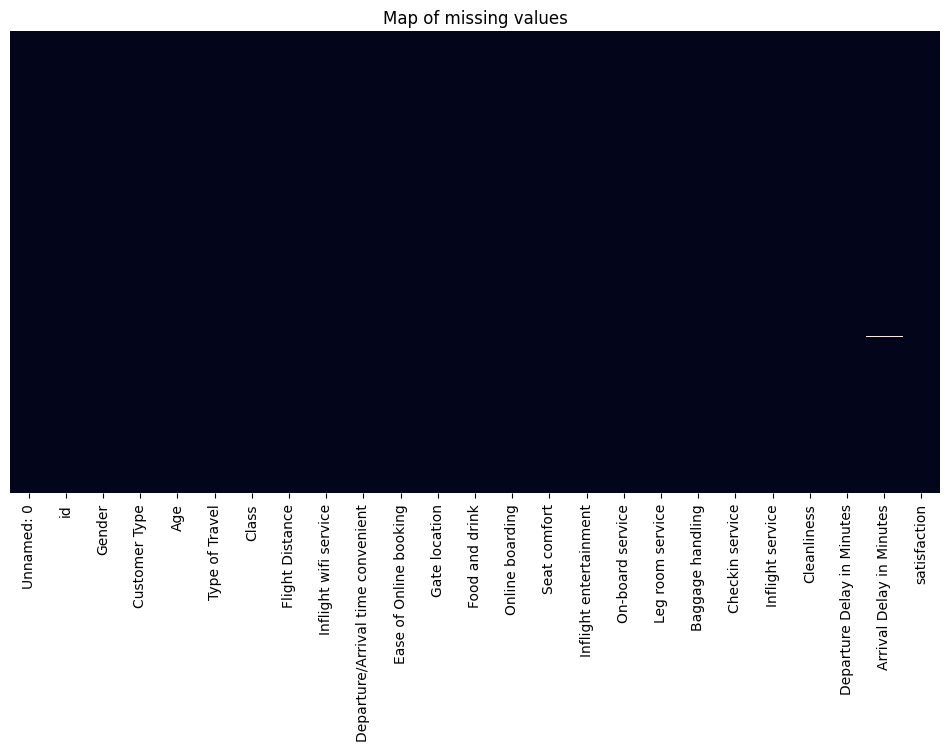

In [9]:
missing_counts = report_missing_values(raw_data_train, top_n=None, show_heatmap=True)

In [10]:
raw_data_train = raw_data_train.drop(columns=["Unnamed: 0"])

In [11]:
raw_data_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 24 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 103904 non-null  int64  
 1   Gender                             103904 non-null  object 
 2   Customer Type                      103904 non-null  object 
 3   Age                                103904 non-null  int64  
 4   Type of Travel                     103904 non-null  object 
 5   Class                              103904 non-null  object 
 6   Flight Distance                    103904 non-null  int64  
 7   Inflight wifi service              103904 non-null  int64  
 8   Departure/Arrival time convenient  103904 non-null  int64  
 9   Ease of Online booking             103904 non-null  int64  
 10  Gate location                      103904 non-null  int64  
 11  Food and drink                     1039

## 2.3 Esploriamo le Features

Per prima cosa, voglio vedere come sono distribuiti i differenti valori tra feature.

In [12]:
def summarize_feature(
    df: pd.DataFrame,
    column: str,
    /,
    *,
    dropna: bool = False,
    percent_decimals: int = 3
) -> pd.DataFrame:
    """
    Return a summary table (value, count, percent) for a single categorical column.

    Parameters
    ----------
    df : pd.DataFrame
        Source DataFrame.
    column : str
        Name of the column to summarise.
    dropna : bool, default False
        If True, exclude NaN from the counts.
    percent_decimals : int, default 2
        Number of decimal places for the percentage values.

    Returns
    -------
    pd.DataFrame
        A DataFrame with columns:
        - 'value'   : distinct values of the feature (as string)
        - 'count'   : absolute frequency
        - 'percent' : relative frequency in %
        Sorted in descending order by count.
    """
    
    if column not in df.columns:
        raise KeyError(f"Column '{column}' not found in DataFrame.")

    total_rows: int = len(df)
    vc = df[column].value_counts(dropna=dropna)

    summary = (
        pd.DataFrame(
            {
                "value": vc.index.astype(str),
                "count": vc.values,
            }
        )
        .assign(percent=lambda d: (d["count"] / total_rows * 100).round(percent_decimals))
        .sort_values(by="count", ascending=False)
        .reset_index(drop=True)
    )

    return summary

In [13]:
features = raw_data_train.columns

In [14]:
for feature in features:
    summary = summarize_feature(raw_data_train, feature)
    print(feature)
    print(summary)
    print("-"*30)

id
         value  count  percent
0        70172      1    0.001
1        98628      1    0.001
2        24026      1    0.001
3       119299      1    0.001
4       111157      1    0.001
...        ...    ...      ...
103899   54173      1    0.001
103900    9345      1    0.001
103901  124279      1    0.001
103902   59339      1    0.001
103903   62567      1    0.001

[103904 rows x 3 columns]
------------------------------
Gender
    value  count  percent
0  Female  52727   50.746
1    Male  51177   49.254
------------------------------
Customer Type
               value  count  percent
0     Loyal Customer  84923   81.732
1  disloyal Customer  18981   18.268
------------------------------
Age
   value  count  percent
0     39   2969    2.857
1     25   2798    2.693
2     40   2574    2.477
3     44   2482    2.389
4     42   2457    2.365
..   ...    ...      ...
70    74     47    0.045
71    76     45    0.043
72    79     42    0.040
73    78     33    0.032
74    85     17 

## 2.4 Features vs Target

Ora approfondirò l'analisi su ogni singola feature per capire meglio quanto ciascuna di esse possa impattare sulla soddisfazione dell'utente

**Come leggo i grafici.** Le percentuali descrivono associazioni nel campione. Quando propongo spiegazioni sui processi aziendali, sono ipotesi: queste survey non controllano tutti i confondenti e non dimostrano effetti causali. Per le variabili continue, gli istogrammi a conteggio non sono da soli probabilità condizionate. Le soglie che commento sono descrittive, non soglie operative validate.

In [15]:
# ------------------------ Heuristics ------------------------

def is_rating_0_5(s: pd.Series) -> bool:
    x = pd.to_numeric(s.dropna(), errors="coerce")
    if x.empty:
        return False
    return set(pd.unique(x)).issubset({0, 1, 2, 3, 4, 5})

def is_categorical(s: pd.Series, max_unique: int = 20) -> bool:
    if is_rating_0_5(s):
        return True
    if (pd.api.types.is_object_dtype(s) or
        isinstance(s.dtype, pd.CategoricalDtype) or
        pd.api.types.is_bool_dtype(s)):
        return True
    return s.nunique(dropna=True) <= max_unique

def collapse_rare_categories(s: pd.Series, top_n: int = 15) -> pd.Series:
    s = s.astype("object")
    vc = s.value_counts(dropna=False)
    if len(vc) <= top_n:
        return s.fillna("NaN")
    keep = set(vc.index[:top_n])
    out = s.where(s.isin(keep), "Other")
    return out.fillna("NaN")

# ------------------------ Data prep ------------------------

def _count_and_percent(
    x: pd.Series, y: pd.Series, classes: Optional[List] = None
) -> Tuple[pd.Index, List, pd.DataFrame, pd.DataFrame]:
    """
    Restituisce:
      - index categorie X
      - lista classi Y
      - counts_df: conteggi per (x, classe)
      - perc_df: percentuali riga (somma=100 per categoria x)
    """
    ct = pd.crosstab(x, y, dropna=False)
    if classes is not None:
        for cls in classes:
            if cls not in ct.columns:
                ct[cls] = 0
        ct = ct[classes]
    counts_df = ct.copy()
    perc_df = (ct.div(ct.sum(axis=1).replace(0, np.nan), axis=0) * 100).fillna(0.0)
    return counts_df.index, counts_df.columns.tolist(), counts_df, perc_df

# ------------------------ Plotters ------------------------

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from typing import List, Optional, Tuple

# --- utilities già definite in precedenza (riutilizzale) ---
# is_rating_0_5, collapse_rare_categories, _count_and_percent

def make_categorical_stacked_figure(
    df: pd.DataFrame,
    feature: str,
    target: str = "satisfaction",
    *,
    show_text: bool = True,       # mostra SOLO la percentuale nel segmento
    bargap: float = 0.35,         # separazione tra barre (0–5 restano “staccate”)
    top_n_cat: int = 15,          # per categoriche non 0..5
    annotate_totals: bool = True  # annota il totale in cima a ciascuna barra
) -> go.Figure:
    """
    Stacked bar: altezza = CONTEGGI reali (differenze tra valori visibili).
    Sulle barre mostriamo SOLO la percentuale della classe dentro il valore.
    Nel tooltip compaiono SIA conteggio assoluto SIA percentuale.
    """
    s_feat = df[feature]
    s_tgt  = df[target]
    classes_sorted = sorted(s_tgt.dropna().unique())

    # --- 0–5: categorie fisse in ordine naturale ---
    if is_rating_0_5(s_feat):
        vals = pd.to_numeric(s_feat, errors="coerce").where(lambda x: x.isin([0,1,2,3,4,5]))
        categories, classes, counts_df, perc_df = _count_and_percent(vals, s_tgt, classes=classes_sorted)
        all_cats = pd.Index([0,1,2,3,4,5], dtype="int64")
        counts_df = counts_df.reindex(index=all_cats, fill_value=0)
        perc_df   = perc_df.reindex(index=all_cats, fill_value=0.0)
        categories = counts_df.index
        x_categoryorder = "array"
        x_categoryarray = [0,1,2,3,4,5]
    else:
        # --- altre categoriche: collassa rare, ordina per volume totale ---
        s_feat = collapse_rare_categories(s_feat, top_n=top_n_cat)
        categories, classes, counts_df, perc_df = _count_and_percent(s_feat, s_tgt, classes=classes_sorted)
        order = counts_df.sum(axis=1).sort_values(ascending=False).index.tolist()
        counts_df = counts_df.loc[order]
        perc_df   = perc_df.loc[order]
        categories = counts_df.index
        x_categoryorder = "category descending"
        x_categoryarray = None

    fig = go.Figure()
    for cls in classes:
        y_counts = counts_df[cls].values         # altezza = conteggi
        y_perc   = perc_df[cls].values           # testo = percentuale
        customdata = np.column_stack([y_counts, y_perc])

        # 👇 SOLO percentuale visibile sulla barra
        texttemplate = "%{customdata[1]:.1f}%" if show_text else None

        fig.add_trace(go.Bar(
            x=categories,
            y=y_counts,
            name=f"Classe {cls}",
            customdata=customdata,
            texttemplate=texttemplate,            # ← niente numero assoluto nel testo
            textposition="inside" if show_text else None,
            hovertemplate=(
                f"{feature}=%{{x}}<br>{target}={cls}"
                "<br>Conteggio=%{customdata[0]}"  # ← il numero assoluto resta nel tooltip
                "<br>Percentuale=%{customdata[1]:.2f}%"
                "<extra></extra>"
            )
        ))

    # Annotazione del totale per ciascuna barra (opzionale, utile per volumi)
    totals = counts_df.sum(axis=1).values
    if annotate_totals and totals.size > 0:
        y_offset = 0.02 * totals.max() if totals.max() > 0 else 1
        for x_val, tot in zip(categories, totals):
            fig.add_annotation(
                x=x_val, y=tot + y_offset, text=str(int(tot)),
                showarrow=False, yanchor="bottom", font=dict(size=11)
            )

    fig.update_layout(
        barmode="stack",
        bargap=bargap,
        template="plotly_white",
        title=f"{feature} per {target} – stacked (conteggi) con % visibili",
        xaxis_title=feature,
        yaxis_title="Conteggio",
        legend_title=target
    )
    if x_categoryarray is not None:
        fig.update_xaxes(categoryorder=x_categoryorder, categoryarray=x_categoryarray)
    else:
        fig.update_xaxes(categoryorder=x_categoryorder)

    return fig


def make_numeric_hist_overlay_figure(
    df: pd.DataFrame,
    feature: str,
    target: str = "satisfaction",
    *,
    nbins: int = 50,
    opacity: float = 0.5,
    density: bool = False
) -> go.Figure:
    s_all = pd.to_numeric(df[feature], errors="coerce").dropna()
    if s_all.empty:
        raise ValueError(f"[{feature}] nessun dato numerico valido.")
    fmin, fmax = float(s_all.min()), float(s_all.max())
    if fmin == fmax:
        fmax = fmin + 1e-9
    bin_edges = np.linspace(fmin, fmax, nbins + 1)
    bin_size  = (fmax - fmin) / nbins

    fig = go.Figure()
    for cls in sorted(df[target].dropna().unique()):
        subset = pd.to_numeric(df.loc[df[target] == cls, feature], errors="coerce").dropna()
        if subset.empty:
            continue
        fig.add_trace(go.Histogram(
            x=subset,
            name=f"Classe {cls}",
            opacity=opacity,
            xbins=dict(start=bin_edges[0], end=bin_edges[-1], size=bin_size),
            histnorm="probability density" if density else None,
            hovertemplate=(
                f"{target}={cls}<br>{feature}=%{{x}}"
                + ("<br>Densità=%{y:.4f}" if density else "<br>Conteggio=%{y}")
                + "<extra></extra>"
            ),
        ))
    fig.update_layout(
        barmode="overlay",
        template="plotly_white",
        title=f"Distribuzione di {feature} per Classe",
        xaxis_title=feature,
        yaxis_title="Densità" if density else "Conteggio",
        legend_title=target
    )
    return fig

# ------------------------ Router (uno alla volta) ------------------------

def make_feature_by_target_figure(
    df: pd.DataFrame,
    feature: str,
    target: str = "satisfaction",
    *,
    cat_max_unique: int = 20,
    top_n_cat: int = 15,
    show_text_cat: bool = True,
    bargap_cat: float = 0.35,
    annotate_totals_cat: bool = True,
    nbins_num: int = 50,
    opacity_num: float = 0.5,
    density_num: bool = False
) -> go.Figure:
    """
    Una feature per volta:
      - Se 0–5 o categorica: stacked con altezza=conteggi + testo "N (p%)".
      - Se numerica: istogrammi sovrapposti con bins condivisi.
    """
    assert target in df.columns, f"Target '{target}' non trovato."
    s = df[feature]
    if is_rating_0_5(s) or is_categorical(s, max_unique=cat_max_unique):
        return make_categorical_stacked_figure(
            df, feature, target,
            show_text=show_text_cat,
            bargap=bargap_cat,
            top_n_cat=top_n_cat,
            annotate_totals=annotate_totals_cat
        )
    else:
        return make_numeric_hist_overlay_figure(
            df, feature, target,
            nbins=nbins_num,
            opacity=opacity_num,
            density=density_num
        )

### 2.4.1 Gender

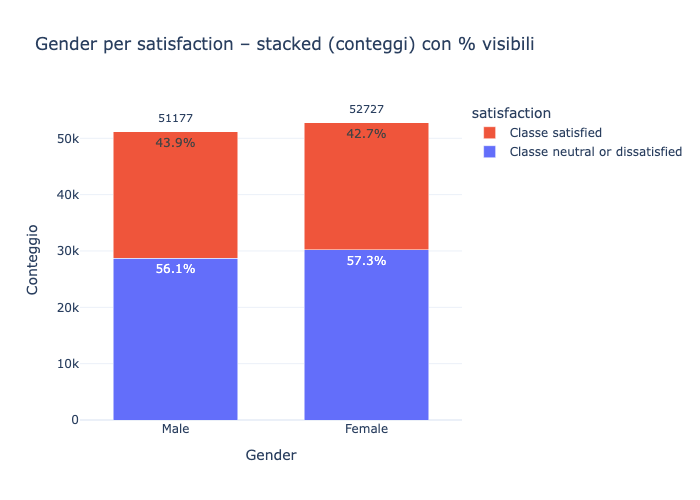

In [16]:
fig = make_feature_by_target_figure(raw_data_train, feature="Gender", target="satisfaction")
fig.show()

Guardando il grafico Gender → satisfaction, noto subito due cose: i volumi dei due gruppi sono quasi identici (≈51,2k Male vs ≈52,7k Female) e i tassi di soddisfazione sono molto vicini: 43,9% per i Male e 42,7% per le Female. Nel complesso il dataset si assesta attorno a una soddisfazione media di ~43,3%.

Interpreto così: il genere da solo mostra un segnale debole. C’è una differenza di circa 1,2 punti percentuali a favore dei Male, ma la distanza è piccola.

La mia ipotesi di lavoro è che eventuali differenze apparenti siano in realtà il riflesso di mix di variabili: classe di viaggio, qualità del servizio a bordo, tempi di check-in, ritardi in partenza/arrivo. Il genere potrebbe agire in interazione con questi fattori (classico rischio di effetto di confondimento o di Simpson).

### 2.4.2 Customer Type

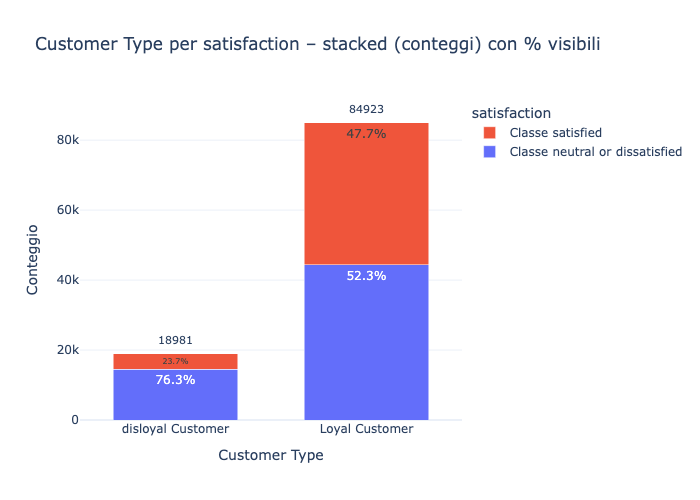

In [17]:
fig = make_feature_by_target_figure(raw_data_train, feature="Customer Type", target="satisfaction")
fig.show()

Osservando Customer Type → satisfaction mi colpisce subito il salto netto tra i due gruppi. 

I disloyal Customer sono pochi (≈19k) e hanno un tasso di soddisfazione molto basso (circa 23,7%); i Loyal Customer sono la maggioranza (≈85k) e risultano soddisfatti nel 47,7% dei casi. In pratica, nel confronto grezzo fra i gruppi, senza controllare le altre variabili, l’essere “loyal” raddoppia il tasso di soddisfazione e triplica circa le odds di essere satisfied rispetto ai disloyal. L’altezza diversa delle barre conferma anche il forte sbilanciamento dei volumi: il campione è dominato dai clienti loyal, quindi il modello tenderà a “vedere” soprattutto quel profilo.

“Customer Type” è una variabile molto informativa per la soddisfazione, ma va maneggiata con giudizio. Potrebbe incorporare effetti a monte (es. frequenza di volo, anzianità, servizi accessori) che a loro volta generano soddisfazione. Non è leakage diretto, però è abbastanza vicina al concetto di fedeltà/relazione da rischiare di “schiacciare” il contributo di altre feature se non regolarizzo bene o se non controllo le interazioni.

### 2.4.3 Age

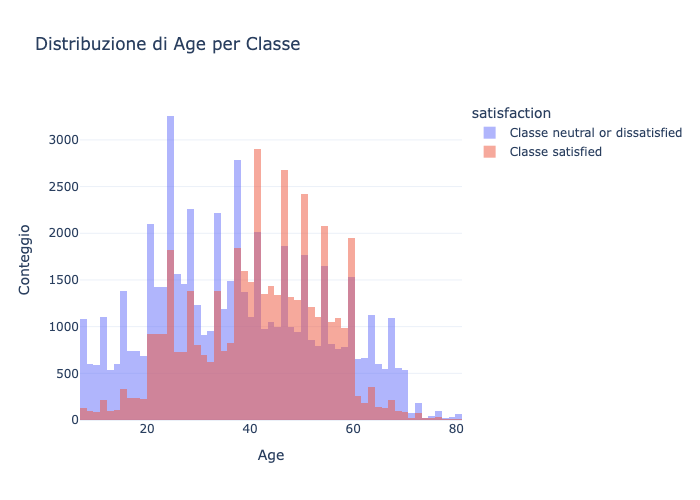

In [18]:
fig = make_feature_by_target_figure(raw_data_train, feature="Age", target="satisfaction", nbins_num=60)
fig.show()

Guardando la distribuzione di Age per classe, vedo che le due curve si sovrappongono quasi completamente: la soddisfazione non sembra dipendere in modo forte dall’età. La massa è concentrata tra i 20 e i 60 anni (normale per un campione di viaggiatori), e a occhio colgo solo scostamenti deboli: nella fascia 35–55 la quota “satisfied” tende a stare leggermente sopra, mentre tra 20–30 e oltre i 65 noto un filo più di “neutral/dissatisfied”. Ma parliamo di differenze sottili che, con istogrammi sovrapposti a conteggio, possono essere influenzate dal volume per fascia.

La mia ipotesi operativa è che Age da sola abbia potere predittivo basso e non lineare (se c’è segnale, è probabilmente a U morbida o con un plateau centrale).

### 2.4.4 Type of Travel

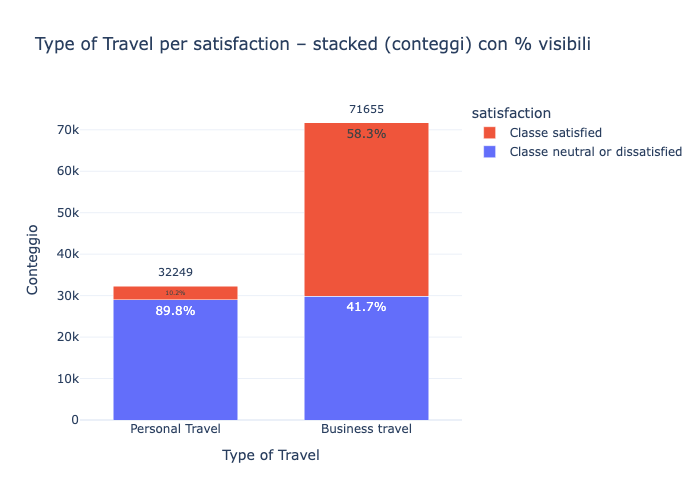

In [19]:
fig = make_feature_by_target_figure(raw_data_train, feature="Type of Travel", target="satisfaction")
fig.show()

Guardando Type of Travel → satisfaction mi viene subito da pensare che qui c’è uno spartiacque vero. I Business travel sono ~71,7k e hanno un tasso di soddisfazione intorno al 58,3%; i Personal travel sono ~32,2k e la soddisfazione scende a circa 10,2%. Tradotto: tra chi viaggia per lavoro la probabilità di essere satisfied è ~5,7× quella dei viaggi personali, e in termini di odds il rapporto è gigantesco (≈ 12:1 a favore del business). Il dato complessivo torna: pesando per i volumi, la soddisfazione media del campione resta attorno al 43%.

**Type of Travel** è una feature molto forte e cattura differenze strutturali del viaggio. I business traveler tendono a interagire con servizi premium o più efficienti (corsie prioritarie, classi superiori, processi più rodati), oppure semplicemente hanno aspettative diverse e valutano l’esperienza in modo più favorevole; al contrario, i personal traveler probabilmente vivono più spesso l’esperienza “economy pura” o subiscono di più l’attrito nei processi. La distanza osservata è ampia, ma questi dati da soli non separano le possibili spiegazioni.

### 2.4.5 Class

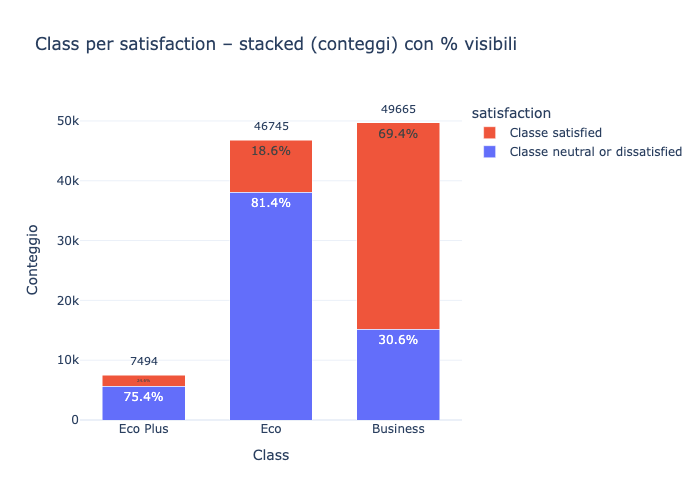

In [20]:
fig = make_feature_by_target_figure(raw_data_train, feature="Class", target="satisfaction")
fig.show()

Osservando Class → satisfaction mi faccio questa idea: la classe di viaggio è uno spartiacque fortissimo. In Business vedo circa 69,4% di satisfied (≈49,7k passeggeri), in Eco il tasso crolla a 18,6% (≈46,7k), mentre Eco Plus sta in mezzo, attorno a ~24–25% (≈7,5k). Le barre hanno altezze comparabili per Business ed Eco (campioni grandi), Eco Plus è molto più piccola.

In termini di associazione osservata, il salto è enorme: le odds di essere satisfied in Business sono ~10× quelle di Eco e ~7× quelle di Eco Plus; tra Eco ed Eco Plus c’è un gradino, ma decisamente più contenuto. Questo per me significa che Class da sola è associata a una differenza importante nella soddisfazione.

Non mi fermo alla storia semplice però: so che Class è intrecciata con almeno due fattori chiave — Type of Travel (il business traveler è spesso in Business) e Customer Type (loyal). È probabile che parte del vantaggio di Business rifletta processi più rapidi, servizi prioritari e, in generale, un mix di servizio diverso.

### 2.4.6 Flight Distance

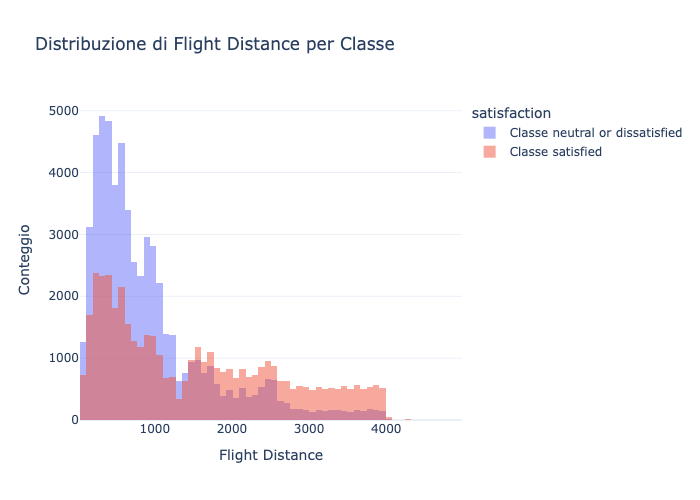

In [21]:
fig = make_feature_by_target_figure(raw_data_train, feature="Flight Distance", target="satisfaction", nbins_num=60)
fig.show()

Guardando la Distribuzione di Flight Distance per classe, mi sembra di leggere una storia abbastanza chiara: sui voli corti (intorno ai 200–800 unità di distanza) la massa è dominata dai neutral/dissatisfied; man mano che la distanza aumenta (da ~1.500 unità di distanza in su) la curva dei satisfied prende il sopravvento. In coda, tra i voli molto lunghi (oltre ~2.500–3.000 unità di distanza), la presenza dei satisfied resta relativamente più alta, pur con volumi totali più bassi (coda lunga).

Come la interpreto: la distribuzione delle distanze differisce fra le classi; da questo grafico a conteggio non stimo direttamente la probabilità di soddisfazione, ma non in modo lineare; sembra una curva che parte bassa sui voli brevi, sale tra ~1.000–2.000 unità di distanza e poi si appiattisce. Quindi “Flight Distance” non è un semplice effetto lineare: mi aspetto non linearità (spline o binning) e interazioni con altre feature. Due ipotesi operative (da verificare, non da prendere per oro colato):

- Sui voli brevi pesa di più l’attrito del processo (code, boarding, tempi morti) rispetto al valore percepito del servizio in volo; un ritardo di 30’ su un volo di 50’ “vale di più” che su un long-haul.
- Sui voli lunghi entrano in gioco comfort, intrattenimento, pasti: c’è più “spazio” perché il servizio faccia la differenza (e spesso cambia anche Class/tariffazione).

### 2.4.7 Inflight wifi service

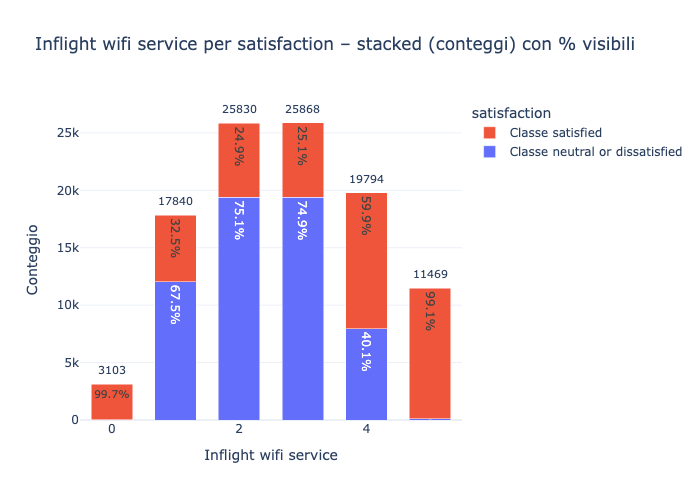

In [22]:
fig = make_feature_by_target_figure(raw_data_train, feature="Inflight wifi service", target="satisfaction")
fig.show()

Vedo un gradiente quasi monotono: a rating 1–3 la quota di satisfied resta bassa e piatta (~ 25–33%), a 4 c’è un salto netto (~ 60% satisfied) e a 5 il rapporto si ribalta quasi del tutto (~ 99% satisfied). Anche i volumi aiutano a contestualizzare: gli scaglioni 2–3 sono i più popolati (~ 25,8k ciascuno), 4 scende (~ 19,8k) e 5 è più piccolo (~ 11,5k). Questo per me racconta un effetto soglia: la percezione del Wi-Fi “buono davvero” scatta dal 4 in su; sotto, gli utenti lo vivono come non risolutivo.

C’è però un’anomalia vistosa su 0 (≈ 3,1k casi) con ~ 99,7% satisfied: la scheda del dataset indica esplicitamente 0 come “Not Applicable” per il Wi-Fi. Se chi non ha usato/valutato il Wi-Fi è soddisfatto per altri motivi (classe, puntualità), il 0 diventa una categoria speciale più che il fondo scala.

Nota bene: essendo una valutazione post-volo, questa feature è quasi “gemella” della target. Va benissimo per spiegare la soddisfazione a posteriori o per scoring su survey, ma potrebbe essere leakage se lo use-case è pre-volo (predire la soddisfazione prima di erogare il servizio). In quel caso restringo il set alle variabili disponibili ex-ante o costruisco due modelli (diagnostico vs predittivo operativo).

### 2.4.8 Departure/Arrival time convenient

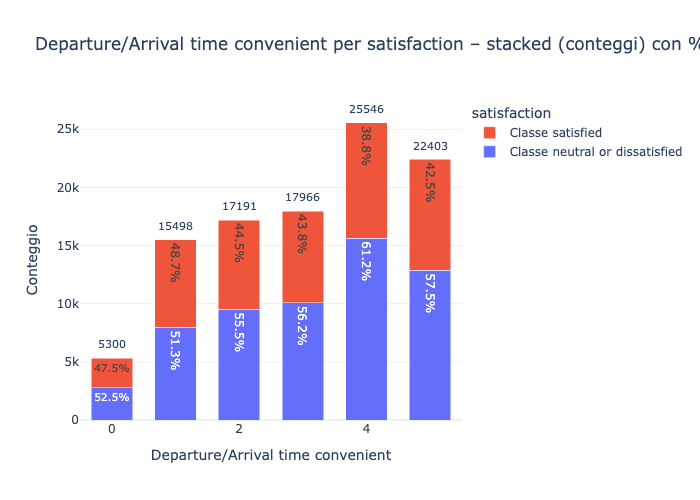

In [23]:
fig = make_feature_by_target_figure(raw_data_train, feature="Departure/Arrival time convenient", target="satisfaction")
fig.show()

Osservando Departure/Arrival time convenient → satisfaction leggo un pattern controintuitivo. Al crescere del rating di “convenienza” la quota di satisfied scende: siamo ~ 48–49% a 1, ~ 44–43% a 2–3, tocchiamo un minimo ~ 38,8% a 4 e risaliamo appena a 42,5% a 5. Anche i volumi contano: 4 e 5 sono le classi più popolose (~ 25,5k e ~ 22,4k), quindi questa dinamica pesa parecchio sul totale. La categoria 0 (≈ 5,3k) sta a metà (~ 47,5% satisfied) e non sembra un “NA mascherato” come avevo visto sul Wi-Fi.

Cosa ipotizzo mentre lo guardo:

- Ipotesi codifica/inversione: la scala potrebbe essere interpretata al contrario (5 = poco conveniente). Prima di tutto verifico il data dictionary o la distribuzione con Spearman tra rating e 1{satisfied}: mi aspetto una correlazione negativa marcata; se il dizionario dice che 5 è “più conveniente”, allora la variabile è effettivamente anti-correlata con la soddisfazione.
- Ipotesi confondenti: i rating alti di “convenienza” potrebbero concentrarsi su fasce orarie di punta (voli affollati, gate congestionati) o su viaggi personali, dove ho visto tassi di soddisfazione molto più bassi. Anche i ritardi potrebbero essere più frequenti proprio negli slot “comodi”.
- Forma dell’effetto: non è lineare; vedo un declino 1→4 e un piccolo rimbalzo a 5. Potrebbe esserci una U rovesciata o un punto di saturazione nella percezione.

### 2.4.9 Ease of Online booking

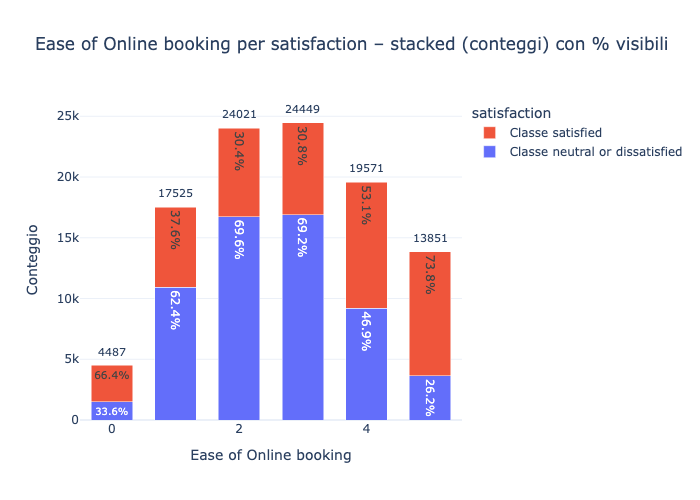

In [24]:
fig = make_feature_by_target_figure(raw_data_train, feature="Ease of Online booking", target="satisfaction")
fig.show()

Vedo un pattern quasi monotono: quando il booking online è valutato 1–3 la soddisfazione resta bassa e piatta (~ 30–38%); al valore 4 c’è un salto (circa 53% satisfied) e a 5 il rapporto si ribalta (~ 74% satisfied). I volumi sono alti proprio dove il giudizio è mediocre (2–3, ~24k ciascuno), quindi quel tratto pesa parecchio sulla media complessiva.

Mi insospettisce la categoria 0 (~ 4.5k casi) con ~ 66% satisfied: più che “pessimo”, qui potrebbe voler dire “non applicabile / non usato / canale diverso” (es. prenotazioni tramite agenzia/corporate). Se molti business non usano l’online e sono più soddisfatti per altri motivi (classe, servizi), il 0 diventa una categoria speciale, non il fondo scala.

### 2.4.10 Gate location

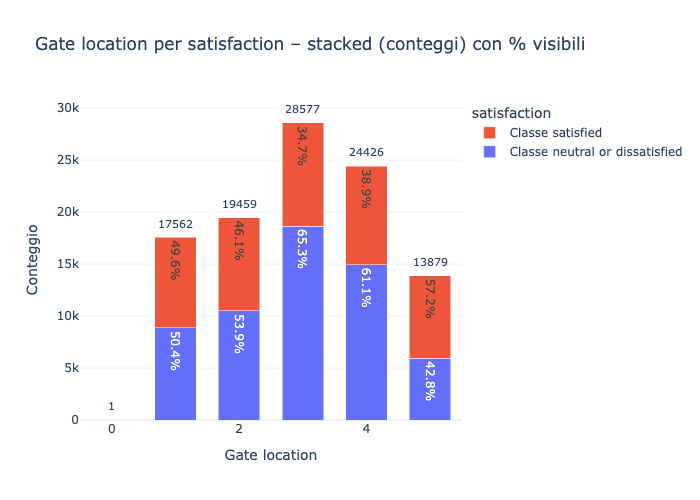

In [25]:
fig = make_feature_by_target_figure(raw_data_train, feature="Gate location", target="satisfaction")
fig.show()

La relazione non è monotona. Ai valori 1–2 la quota di satisfied è intorno al 50% → 46%; su 3 tocca il minimo (≈ 34,7%) e risale leggermente a 4 (≈ 38,9%), per poi impennarsi a 5 (≈ 57,2%). I volumi sono alti proprio su 3–4 (≈28,6k e 24,4k), quindi il “buco” centrale pesa parecchio sulla media complessiva. La categoria 0 ha 1 solo record: la considero rumore/codifica anomala, la tratterei come NA separato.

Come la interpreto: la soddisfazione è peggiore nelle valutazioni intermedie (3–4) e migliore agli estremi, soprattutto a 5. Se 5 significa “gate comodo/ben posizionato”, allora ha senso che migliori la percezione complessiva; il crollo su 3–4 potrebbe riflettere gate scomodi, lontani o congestionati (navette, scale mobili affollate, corridoi lunghi). Potrebbe anche esserci un effetto aeroporto/terminal: alcuni hub assegnano sistematicamente gate “peggiori” a certi voli.

### 2.4.11 Food and drink

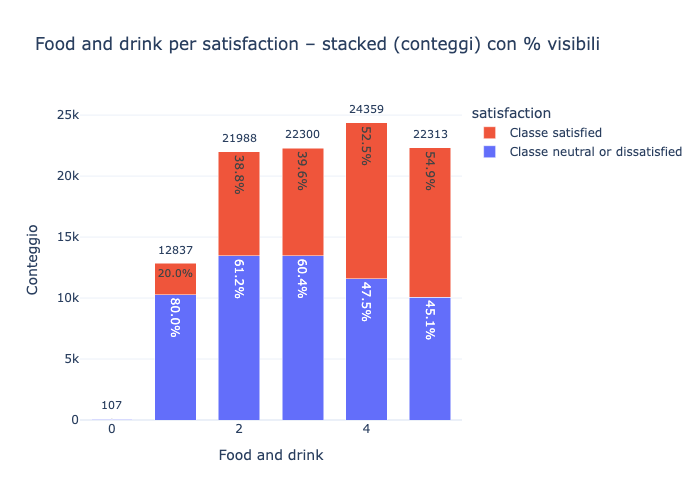

In [26]:
fig = make_feature_by_target_figure(raw_data_train, feature="Food and drink", target="satisfaction")
fig.show()

Guardando Food and drink → satisfaction mi viene naturale leggere un gradiente crescente: ai voti 1–3 la quota di satisfied rimane bassa e stabile (≈ 20% a 1, 39% a 2–3), poi a 4 c’è il cambio di regime (≈ 52,5%) e a 5 si consolida (≈ 54,9%). I volumi sono alti proprio tra 2–5 (≈22–24k ciascuno), quindi questo pattern pesa molto sul totale. La categoria 0 (n=107) è trascurabile: la tratto come rumore o “non applicabile”.

Come la interpreto da analista:
- C’è un effetto soglia chiaro tra 3→4: è lì che la percezione del catering “diventa abbastanza buona da spostare la soddisfazione oltre il 50%”.
- Tra 4→5 vedo rendimenti decrescenti: il miglioramento c’è, ma è più piccolo.
- Sotto il cofano potrebbero agire Class e Type of Travel (es. Business con catering migliore; Business traveler più indulgenti), quindi parte del gradiente potrebbe riflettere il mix di prodotto più che il solo cibo.

### 2.4.12 Online boarding

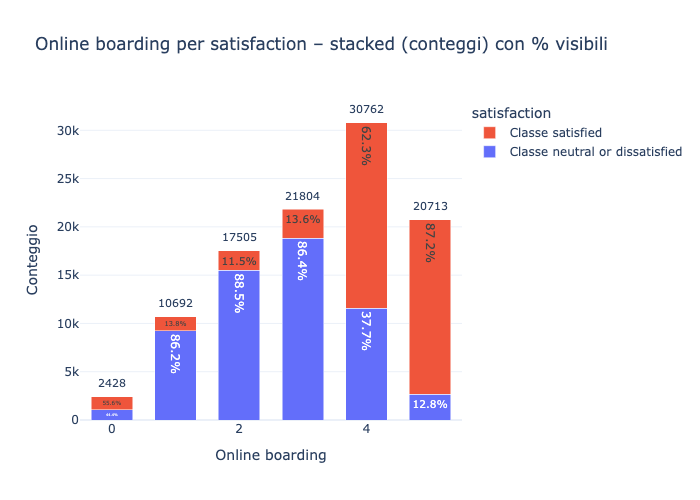

In [27]:
fig = make_feature_by_target_figure(raw_data_train, feature="Online boarding", target="satisfaction")
fig.show()

Guardando Online boarding → satisfaction mi viene fuori un segnale pulitissimo e… rumorosamente monotono.

Vedo che ai voti 0–3 la quota di satisfied è molto bassa (intorno al 10–14%; per 3 leggo ~ 13,6%). Poi, al valore 4 c’è il cambio di fase: si sale a ~ 62,3% satisfied, e a 5 si arriva addirittura a ~ 87,2%. Anche i volumi contano: 4 è lo scaglione più popoloso (~ 30,8k), 5 è grande (~ 20,7k), mentre 0–1–2–3 sono sensibilmente più piccoli. In pratica: quando l’esperienza di online boarding è percepita come “buona” (≥4), la soddisfazione si ribalta.

Interpreto così: c’è un effetto soglia netto tra 3→4. Sotto quella soglia l’esperienza non “sblocca” valore percepito; sopra, sì — e il passaggio a 5 porta un ulteriore salto, coerente con un processo davvero fluido (app che funziona, QR immediato, poche frizioni ai varchi). La categoria 0 (≈2,4k) con soddisfazione bassissima probabilmente non è “peggiore del peggiore”, ma “non applicabile / non usato / impossibilitato a fare l’online boarding”; la tratto come flag separato, non come fondo della scala.

Come ipotesi da verificare, rendere l’online boarding “almeno buono” (4) potrebbe essere un punto di intervento; l’upgrade 4→5 aggiunge ulteriore valore, ma il grosso della curva si vince superando la soglia del 3. Operativamente: ridurre attriti (login, documenti, sincronizzazione PNR, QR stabile offline), chiarezza delle eccezioni e integrazione con il check-in.

### 2.4.13 Seat comfort

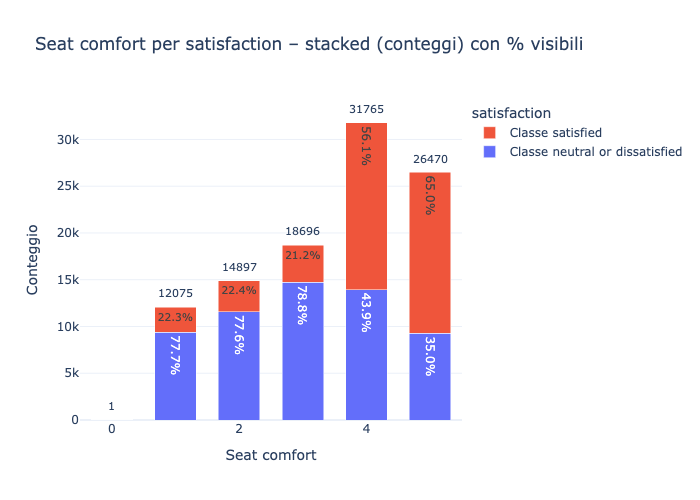

In [28]:
fig = make_feature_by_target_figure(raw_data_train, feature="Seat comfort", target="satisfaction")
fig.show()

Qui c’è un driver forte con un chiaro effetto soglia.

Vedo che ai voti 1–3 la quota di satisfied resta piatta e bassa (≈21–22%: 1→22,3%, 2→22,4%, 3→21,2%) con volumi non trascurabili (≈12k, 15k, 18,7k). Dal 3 al 4 cambia il film: il satisfied balza a 56,1% (≈31,8k record, lo scaglione più popoloso), e a 5 arriva a 65,0% (≈26,5k). La categoria 0 è un singolo caso: la tratto come rumore/NA.

La comodità del sedile sembra essere una leva concreta di soddisfazione. Non vedo una crescita lineare: è più un salto 3→4 (≈+35 punti percentuali) e poi rendimenti decrescenti 4→5 (≈+9 pp). Mi aspetto però confondenti importanti: soprattutto Class (Business ↔ sedili migliori) e Type of Travel. Parte del gradiente potrebbe riflettere il mix di cabina/servizi più che il solo sedile.

Nota bene: essendo un rating post-volo, Seat comfort è ottimo per spiegare la soddisfazione o per scoring su survey; per un uso predittivo pre-erogazione rischio leakage. In quel caso separo chiaramente il modello “diagnostico” (con i rating) da quello “operativo” (solo variabili note ex-ante).

### 2.4.14 Inflight entertainment

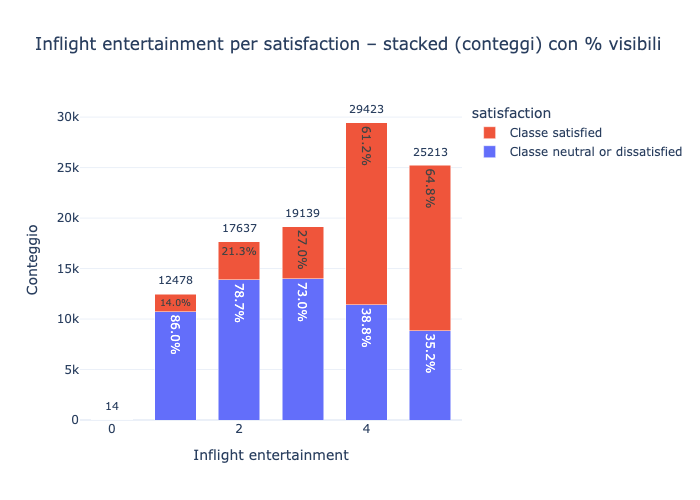

In [29]:
fig = make_feature_by_target_figure(raw_data_train, feature="Inflight entertainment", target="satisfaction")
fig.show()

Guardando Inflight entertainment → satisfaction mi sembra di vedere un pattern pulito e molto “didattico”. Fino a 3 la soddisfazione resta bassa e quasi piatta (≈ 14% a 1, 21% a 2, 27% a 3 con volumi importanti: ~ 12,5k, 17,6k, 19,1k). Dal 3 al 4 cambia marcia: saliamo a ~ 61% satisfied (≈ 29,4k casi, il cluster più popoloso) e a 5 ci attestiamo su ~65% (≈ 25,2k). La categoria 0 ha 14 record—la tratto come rumore/NA.

Cosa ne deduco: l’intrattenimento di bordo è un driver forte con effetto soglia 3→4 e rendimenti decrescenti 4→5. Non mi aspetto linearità; la relazione è chiaramente ordinale e crescente. È anche plausibile un effetto di contesto: su tratte più lunghe (o in Business) l’entertainment pesa e spesso è migliore. Quindi parte del segnale potrebbe riflettere Class e Flight Distance oltre che la qualità intrinseca del servizio.

### 2.4.15 On-board service

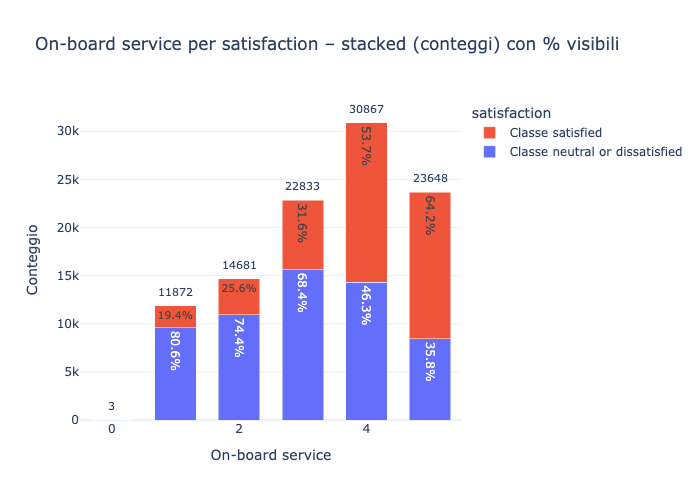

In [30]:
fig = make_feature_by_target_figure(raw_data_train, feature="On-board service", target="satisfaction")
fig.show()

Vedo che ai voti 1–3 la soddisfazione resta bassa e quasi piatta (~ 19% → 26% → 32%), poi dal 3 al 4 c’è il cambio di fase (~ 54% satisfied, ed è anche lo scaglione più popoloso, ~ 30,9k). A 5 si consolida (~ 64%). La categoria 0 ha 3 record: la considero rumore/NA e non la mescolo alla scala.

Come lo interpreto: il servizio a bordo “funziona davvero” solo oltre la soglia 3→4 (salto ~ +22pp), mentre 4→5 aggiunge valore ma con rendimenti decrescenti (~ +10pp). In termini di intensità, il confronto 3 vs 5 aumenta le odds di essere satisfied (ordine di grandezza ~ 4×), quindi non è un segnale cosmetico: pesa.

### 2.4.16 Leg room service

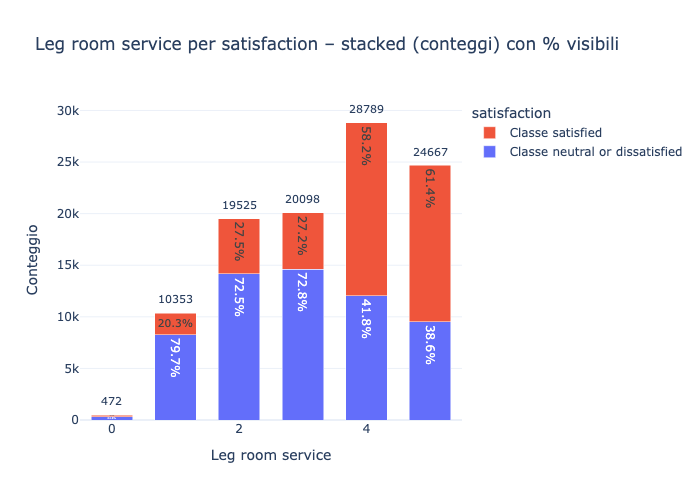

In [31]:
fig = make_feature_by_target_figure(raw_data_train, feature="Leg room service", target="satisfaction")
fig.show()

Ai voti 1–3 la soddisfazione resta bassa e piatta (≈ 20–27%), poi dal 3 al 4 c’è il salto vero: arrivo a ~ 58,2% satisfied, e a 5 si stabilizza su ~ 61,4%. I volumi sono consistenti proprio su 3–5 (≈ 20k, 28,8k, 24,7k), quindi questo gradino pesa parecchio sul totale. La classe 0 è rara (≈ 472 casi): la considero un’anomalia/NA e non la mescolo alla scala.

La spaziosità per le gambe è un driver forte della soddisfazione, ma l’effetto non è lineare. 

Vedo un effetto soglia 3→4 (il “salto di qualità”), poi rendimenti decrescenti 4→5. So però che qui può giocare il mix di cabina: più Business ⇒ più legroom ⇒ più soddisfazione. Quindi parte del gradiente potrebbe riflettere Class (e anche Type of Travel e Flight Distance) oltre al solo servizio “leg room”.

### 2.4.17 Baggage handling

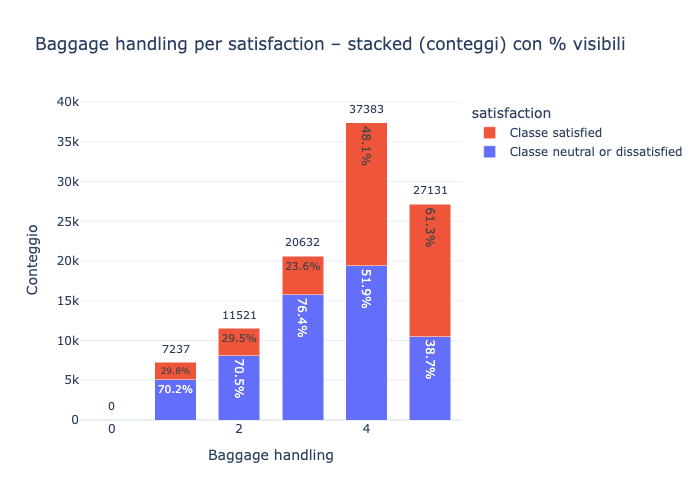

In [32]:
fig = make_feature_by_target_figure(raw_data_train, feature="Baggage handling", target="satisfaction")
fig.show()

Vedo un profilo quasi monotono crescente, con un punto debole a 3. Sui voti 1–2 la quota di satisfied è simile (≈ 30%), scende a 3 (≈ 23,6%), poi salta a 4 (≈ 48,1%) e si rafforza a 5 (≈ 61,3%). In termini di volumi, il grosso sta proprio su 4 (~ 37,4k) e 5 (~ 27,1k), quindi quel salto 3→4 pesa molto sulla media complessiva. La categoria 0 non compare (0 record), nessun problema di codifica qui.

La gestione bagagli è un driver importante della soddisfazione. Il fatto che 3 sia peggiore di 1–2 mi suggerisce che “3 = esperienza mediocre” irrita più di un giudizio apertamente negativo (paradosso del “meh”): attese irregolari al nastro, comunicazioni poco chiare, piccole frizioni che si sommano. La soglia operativa è 3→4 (≈ +24,5 pp), mentre 4→5 porta ancora beneficio (≈ +13,2 pp), ma con rendimenti decrescenti. Nel complesso, tra 3 e 5 il delta è enorme (≈ +37,7 pp).

### 2.4.18 Checkin service

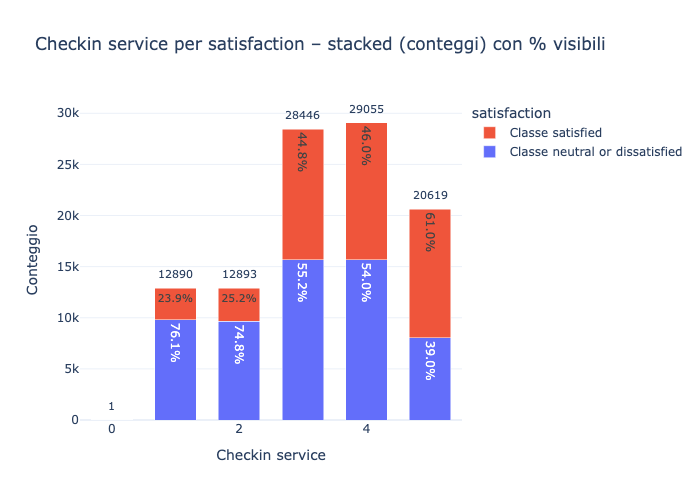

In [33]:
fig = make_feature_by_target_figure(raw_data_train, feature="Checkin service", target="satisfaction")
fig.show()

Vedo una crescita netta con un salto importante tra 2→3: a 1–2 la soddisfazione è bassa (~ 24–25%), a 3 balza a ~ 44,8% e a 4 si assesta ~ 46%; il picco è a 5 con ~ 61%. Anche i volumi contano: gli scaglioni più popolosi sono 3–4 (~ 28,4k e ~ 29,1k), mentre 5 è comunque consistente (~ 20,6k). La categoria 0 è un record singolo: la tratto come anomalia/NA.

Come lo interpreto: il check-in è un driver forte ma con effetto soglia. Finché l’esperienza è insufficiente/mediocre (1–2), la soddisfazione resta depressa; superata la soglia 3, il rapporto si ribalta, con ulteriori guadagni fino a 5 (anche se 3→4 cresce poco, il vero cambio di fase è 2→3). Mi aspetto confondenti: Class e Type of Travel (corsie/business), e soprattutto correlazione con Online boarding; processi digitali fluidi tendono a migliorare entrambi i rating.

### 2.4.19 Inflight service

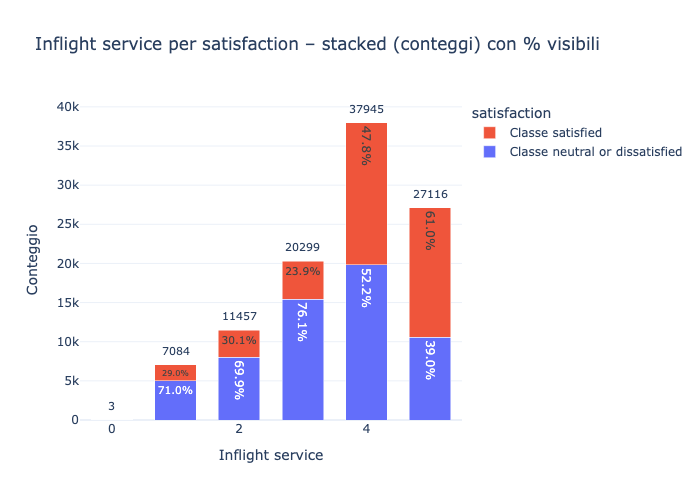

In [34]:
fig = make_feature_by_target_figure(raw_data_train, feature="Inflight service", target="satisfaction")
fig.show()

Nei voti 1–3 la soddisfazione resta bassa (~ 24–30%) e, curiosamente, 3 è il peggiore (~ 23,9%). 

Dal 3 al 4 c’è il vero cambio di fase: salgo a ~ 47,8% (ed è anche lo scaglione più popoloso, ~ 37,9k), poi a 5 arrivo a ~ 61%. La categoria 0 ha 3 casi: la considero rumore/NA.

Come la interpreto: l’inflight service è un driver forte con effetto soglia 3→4, poi rendimenti decrescenti 4→5. Il “buco” a 3 (peggio di 2) mi fa pensare a quell’esperienza mediocre che irrita più di un giudizio apertamente negativo: tempi di risposta, cortesia altalenante, annunci poco chiari. So anche che questo rating si muove insieme ad altri (Seat comfort, Food & drink, Entertainment) e con Class/Type of Travel: parte del gradiente potrebbe riflettere il mix di cabina più che il solo servizio di bordo.

### 2.4.20 Cleanliness

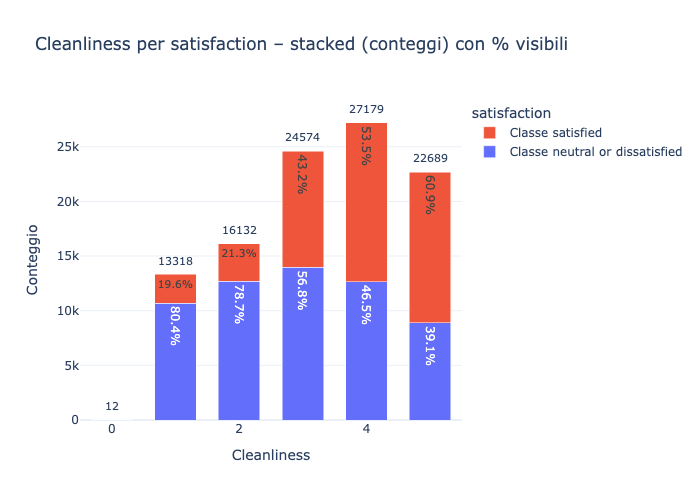

In [35]:
fig = make_feature_by_target_figure(raw_data_train, feature="Cleanliness", target="satisfaction")
fig.show()

Guardando Cleanliness → satisfaction leggo un pattern pulito e crescente. Sui voti 1–2 la soddisfazione è bassa (~ 19,6% e ~ 21,3%), poi a 3 salta al ~ 43,2% (praticamente in linea con la media complessiva che ho visto finora), a 4 sale a ~ 53,5% e a 5 arriva a ~ 60,9%. 

I volumi sono importanti proprio dove il servizio è percepito meglio (3–5: ~ 24,6k, ~ 27,2k, ~ 22,7k), quindi questo gradiente pesa davvero sul totale. La classe 0 ha 12 casi: la tratto come anomalia/NA, non la includo nella scala.

Come la interpreto: la pulizia è un driver chiaro con effetto soglia. Passare da un’esperienza scarsa (1–2) a 3 riporta già la soddisfazione verso la baseline; la vera spinta arriva poi da 3→4 (+10pp) e si consolida 4→5 (+7pp), con rendimenti decrescenti nell’ultimo tratto. Mi aspetto che il segnale si intrecci con Class e con altri rating di servizio (On-board, Food & drink, Seat comfort): ambienti più curati e spaziosi coincidono spesso con cabine migliori e processi più fluidi.

### 2.4.21 Departure Delay in Minutes

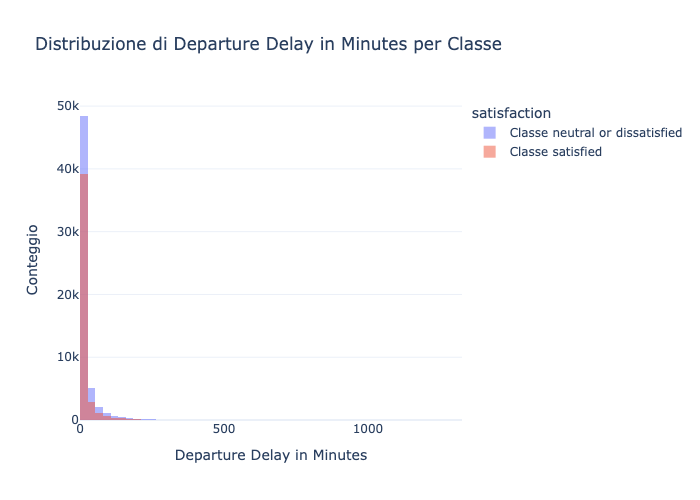

In [36]:
fig = make_feature_by_target_figure(raw_data_train, feature="Departure Delay in Minutes", target="satisfaction", nbins_num=60)
fig.show()

La variabile è estremamente asimmetrica a destra. C’è una grossa massa vicino allo zero (molti voli senza ritardo o con pochi minuti) e una coda lunghissima che arriva a centinaia di minuti. 

Le due curve (satisfied vs non satisfied) si sovrappongono nei micro-ritardi, ma appena mi allontano dallo zero vedo che la quota di non satisfied cresce: gli istogrammi lo suggeriscono, anche se la scala logica lo nasconde un po’ perché il picco iniziale domina.

Le mie deduzioni:
- La variabile ha una chiara zero-inflation (tanti 0) e outlier pesanti. Così com’è, in un modello lineare rischia di comportarsi male.
- L’effetto sulla soddisfazione non è binario “ritardo sì/no”, è più da soglie: attorno ai 15 minuti (soglia operativa classica), poi 30, 60 e oltre. Oltre queste soglie mi aspetto un crollo progressivo della soddisfazione.
- L’istogramma a conteggi non permette di leggere bene i tassi; serve passare a una vista per proporzioni.

### 2.4.22 Arrival Delay in Minutes

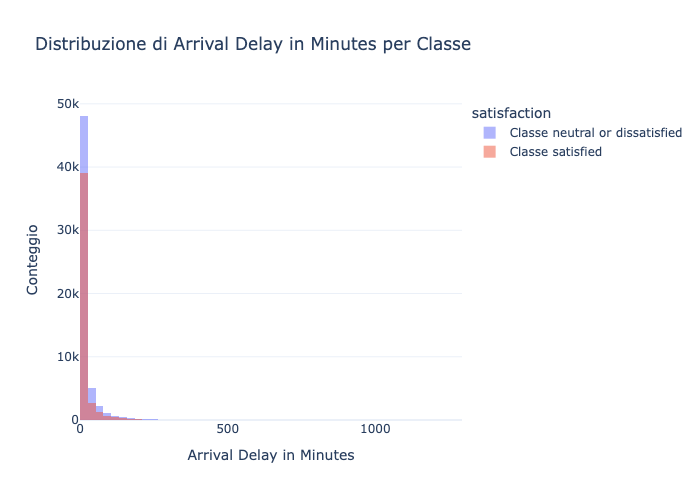

In [37]:
fig = make_feature_by_target_figure(raw_data_train, feature="Arrival Delay in Minutes", target="satisfaction", nbins_num=60)
fig.show()

Guardando la Distribuzione di Arrival Delay in Minutes per classe, mi ritrovo la stessa storia del departure ma più “sensibile” lato cliente: forte asimmetria a destra, tanta massa a 0–5′ e una coda lunghissima che spinge fino a centinaia di minuti. Le due curve si sovrappongono quasi del tutto vicino allo zero; appena i minuti crescono, la porzione di neutral/dissatisfied prende il sopravvento. Non sorprende: ciò che ricordo davvero è quando arrivo, non quando parto.

Come la interpreto:
- Variabile zero-inflated e con outlier pesanti; a conteggi l’effetto si “schiaccia” sul picco iniziale, ma il trend è chiaro: più ritardo all’arrivo ⇒ meno soddisfazione.
- L’impatto è a soglie più che lineare: mi aspetto rotture nette attorno a 15′, 30′, 60′.
- Rispetto al departure, l’arrival delay dovrebbe avere potere predittivo maggiore sulla soddisfazione (è il “dolore” finale).

## 2.5 Outliers

OUTLIER ANALYSIS RESULTS:
                            IQR_count  IQR_%  Z-Score_count  Z-Score_%
Age                                 0  0.000             17      0.020
Flight Distance                  2291  2.200             58      0.060
Departure Delay in Minutes      14529 13.980           2222      2.140
Arrival Delay in Minutes        13954 13.430           2225      2.140


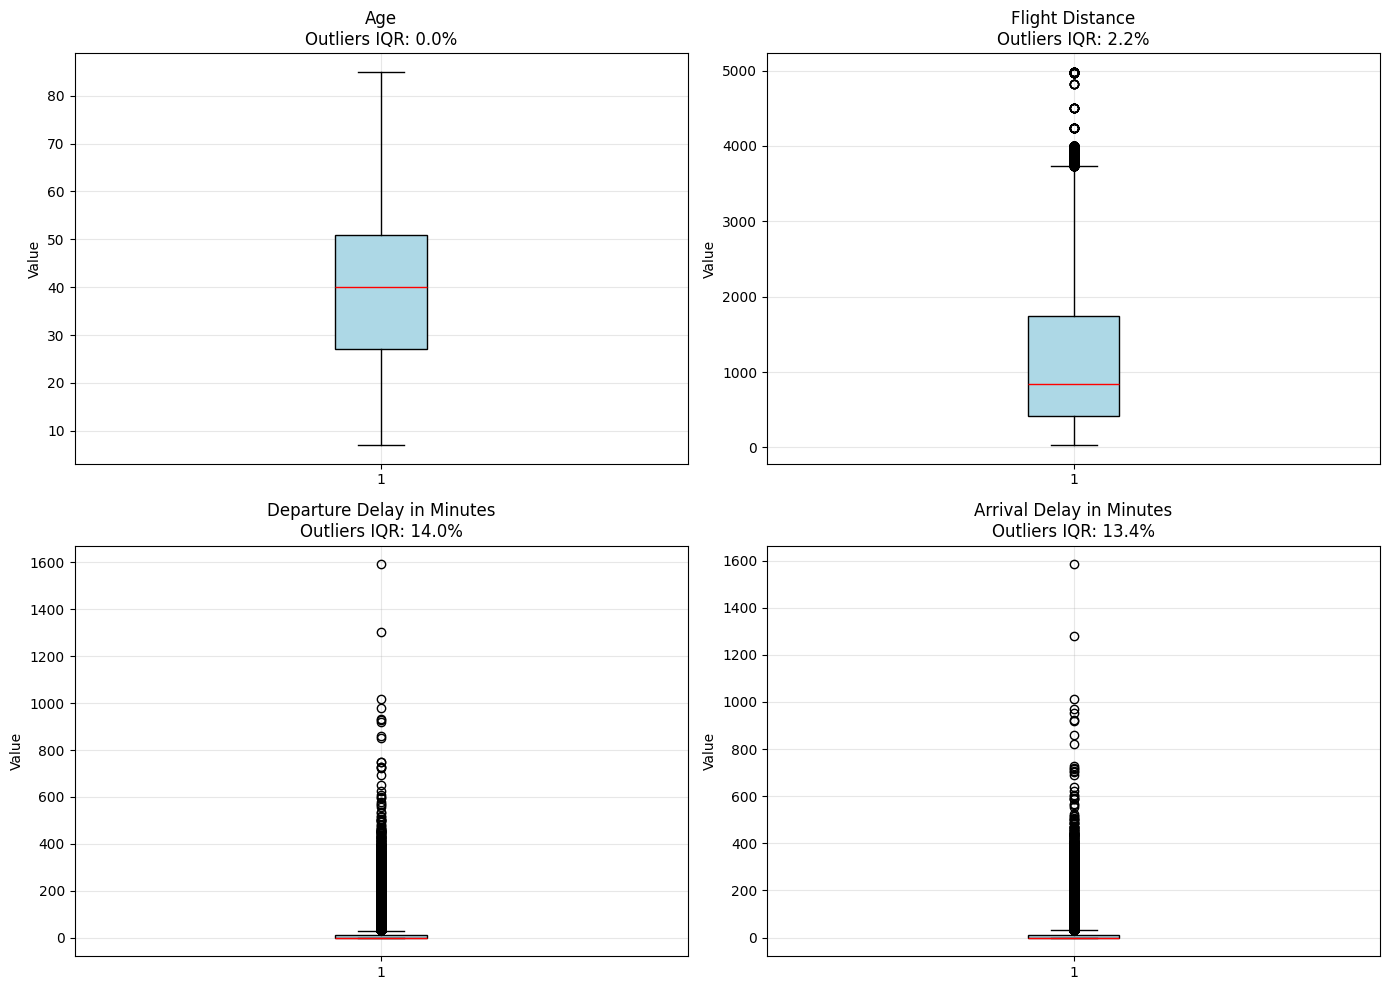


ANALISI DETTAGLIATA OUTLIERS:

Age:
------------------------------
  Min: 7.00
  Q1: 27.00
  Mediana: 40.00
  Q3: 51.00
  Max: 85.00
  IQR Lower Bound: -9.00
  IQR Upper Bound: 87.00
  Outliers (IQR): 0 (0.00%)
  Outliers (Z-score>3): 17 (0.02%)

Flight Distance:
------------------------------
  Min: 31.00
  Q1: 414.00
  Mediana: 843.00
  Q3: 1743.00
  Max: 4983.00
  IQR Lower Bound: -1579.50
  IQR Upper Bound: 3736.50
  Outliers (IQR): 2291 (2.20%)
  Outliers (Z-score>3): 58 (0.06%)

Departure Delay in Minutes:
------------------------------
  Min: 0.00
  Q1: 0.00
  Mediana: 0.00
  Q3: 12.00
  Max: 1592.00
  IQR Lower Bound: -18.00
  IQR Upper Bound: 30.00
  Outliers (IQR): 14529 (13.98%)
  Outliers (Z-score>3): 2222 (2.14%)

Arrival Delay in Minutes:
------------------------------
  Min: 0.00
  Q1: 0.00
  Mediana: 0.00
  Q3: 13.00
  Max: 1584.00
  IQR Lower Bound: -19.50
  IQR Upper Bound: 32.50
  Outliers (IQR): 13954 (13.43%)
  Outliers (Z-score>3): 2225 (2.14%)


In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats  # Import mancante!
import warnings

# Identifica colonne numeriche continue (non rating 0-5)
continuous_cols = ['Age', 'Flight Distance', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']

# Metodo 1: IQR (Interquartile Range)
def detect_outliers_iqr(df, columns):
    outliers_summary = {}
    
    for col in columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
        outliers_mask = (df[col] < lower_bound) | (df[col] > upper_bound)
        outliers_count = outliers_mask.sum()
        outliers_percentage = (outliers_count / len(df)) * 100
        
        outliers_summary[col] = {
            'count': outliers_count,
            'percentage': outliers_percentage,
            'lower_bound': lower_bound,
            'upper_bound': upper_bound
        }
    
    return outliers_summary

# Metodo 2: Z-Score
def detect_outliers_zscore(df, columns, threshold=3):
    outliers_summary = {}
    
    for col in columns:
        # Gestisci eventuali NaN
        col_data = df[col].dropna()
        z_scores = np.abs(stats.zscore(col_data))
        outliers_count = (z_scores > threshold).sum()
        outliers_percentage = (outliers_count / len(df)) * 100
        
        outliers_summary[col] = {
            'count': outliers_count,
            'percentage': outliers_percentage,
            'threshold': threshold
        }
    
    return outliers_summary

# Applica entrambi i metodi su raw_data_train
outliers_iqr = detect_outliers_iqr(raw_data_train, continuous_cols)
outliers_zscore = detect_outliers_zscore(raw_data_train, continuous_cols)

# Crea un DataFrame riassuntivo
outliers_results = pd.DataFrame({
    'IQR_count': [outliers_iqr[col]['count'] for col in continuous_cols],
    'IQR_%': [outliers_iqr[col]['percentage'] for col in continuous_cols],
    'Z-Score_count': [outliers_zscore[col]['count'] for col in continuous_cols],
    'Z-Score_%': [outliers_zscore[col]['percentage'] for col in continuous_cols]
}, index=continuous_cols)

print("OUTLIER ANALYSIS RESULTS:")
print("="*60)
print(outliers_results.round(2))

# Visualizzazione
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for idx, col in enumerate(continuous_cols):
    ax = axes[idx]
    
    # Box plot con outlier evidenziati
    box_data = raw_data_train[col].dropna()
    box = ax.boxplot(box_data, orientation="vertical", patch_artist=True)
    box['boxes'][0].set_facecolor('lightblue')
    box['medians'][0].set_color('red')
    
    ax.set_title(f'{col}\nOutliers IQR: {outliers_iqr[col]["percentage"]:.1f}%')
    ax.set_ylabel('Value')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Analisi aggiuntiva: mostra i valori estremi per ogni variabile
print("\n" + "="*60)
print("ANALISI DETTAGLIATA OUTLIERS:")
print("="*60)

for col in continuous_cols:
    print(f"\n{col}:")
    print("-" * 30)
    
    # Statistiche base
    col_data = raw_data_train[col].dropna()
    print(f"  Min: {col_data.min():.2f}")
    print(f"  Q1: {col_data.quantile(0.25):.2f}")
    print(f"  Mediana: {col_data.median():.2f}")
    print(f"  Q3: {col_data.quantile(0.75):.2f}")
    print(f"  Max: {col_data.max():.2f}")
    
    # Bounds IQR
    print(f"  IQR Lower Bound: {outliers_iqr[col]['lower_bound']:.2f}")
    print(f"  IQR Upper Bound: {outliers_iqr[col]['upper_bound']:.2f}")
    
    # Percentuale outliers
    print(f"  Outliers (IQR): {outliers_iqr[col]['count']} ({outliers_iqr[col]['percentage']:.2f}%)")
    print(f"  Outliers (Z-score>3): {outliers_zscore[col]['count']} ({outliers_zscore[col]['percentage']:.2f}%)")

**Decisione operativa sugli outlier.**

- **Age** e **Flight Distance** hanno pochi valori oltre le soglie IQR/Z-score; età fino a 85 anni e distanze fino a circa 5.000 unità non bastano, da sole, a dimostrare errori. L'unità della distanza non è documentata nella scheda consultata.
- **Departure Delay** e **Arrival Delay** presentano circa il 13–14% di outlier IQR e code molto lunghe. Sono situazioni possibili, che interessa mantenere nell'analisi; gli outlier statistici non coincidono automaticamente con dati errati.

Non elimino righe con questi criteri. Confronto comunque modelli lineari e ad albero. Mantengo **RobustScaler** per i ritardi e **StandardScaler** per le altre numeriche: il primo usa mediana e IQR, meno sensibili alle code. Lo scaling non cancella gli estremi né rende una variabile normale; per gli alberi non è necessario, ma rende la preparazione comune e serve alla regressione logistica.

## 2.6 Analisi delle Variabili Categoriche

CATEGORICAL VARIABLES ANALYSIS:

Gender:
------------------------------
        Count  Percentage
Gender                   
Female  52727      50.750
Male    51177      49.250
Unique values: 2
Missing values: 0

Customer Type:
------------------------------
                   Count  Percentage
Customer Type                       
Loyal Customer     84923      81.730
disloyal Customer  18981      18.270
Unique values: 2
Missing values: 0

Type of Travel:
------------------------------
                 Count  Percentage
Type of Travel                    
Business travel  71655      68.960
Personal Travel  32249      31.040
Unique values: 2
Missing values: 0

Class:
------------------------------
          Count  Percentage
Class                      
Business  49665      47.800
Eco       46745      44.990
Eco Plus   7494       7.210
Unique values: 3
Missing values: 0

STRATEGIA DI ENCODING CONSIGLIATA:
Gender: 2 categorie → Label Encoding (Binary)
Customer Type: 2 categorie → Label Encod

Class: 3 categorie → One-Hot Encoding

IMPLEMENTAZIONE ENCODING:

1. LABEL ENCODING (Variabili Binarie):
------------------------------

Gender:
  'Female' → 0 (n=52727, 50.7%)
  'Male' → 1 (n=51177, 49.3%)

Customer Type:
  'Loyal Customer' → 0 (n=84923, 81.7%)
  'disloyal Customer' → 1 (n=18981, 18.3%)

Type of Travel:
  'Business travel' → 0 (n=71655, 69.0%)
  'Personal Travel' → 1 (n=32249, 31.0%)

2. ONE-HOT ENCODING (Variabili Multi-classe):
------------------------------

Class (3 categorie):
  Nuove colonne create: ['Class_Business', 'Class_Eco', 'Class_Eco Plus']
    Class_Business: 49665 records (47.8%)
    Class_Eco: 46745 records (45.0%)
    Class_Eco Plus: 7494 records (7.2%)

IMPATTO DELL'ENCODING SUL DATASET:
Colonne originali: 24
Colonne dopo encoding: 30
Nuove colonne create: 6

CORRELAZIONE CATEGORICHE CON TARGET:

Gender:
  Chi-square: 15.44
  P-value: 0.0001
  Cramér's V: 0.012 (molto debole)

Customer Type:
  Chi-square: 3657.28
  P-value: 0.0000
  Cramér's V: 0.18

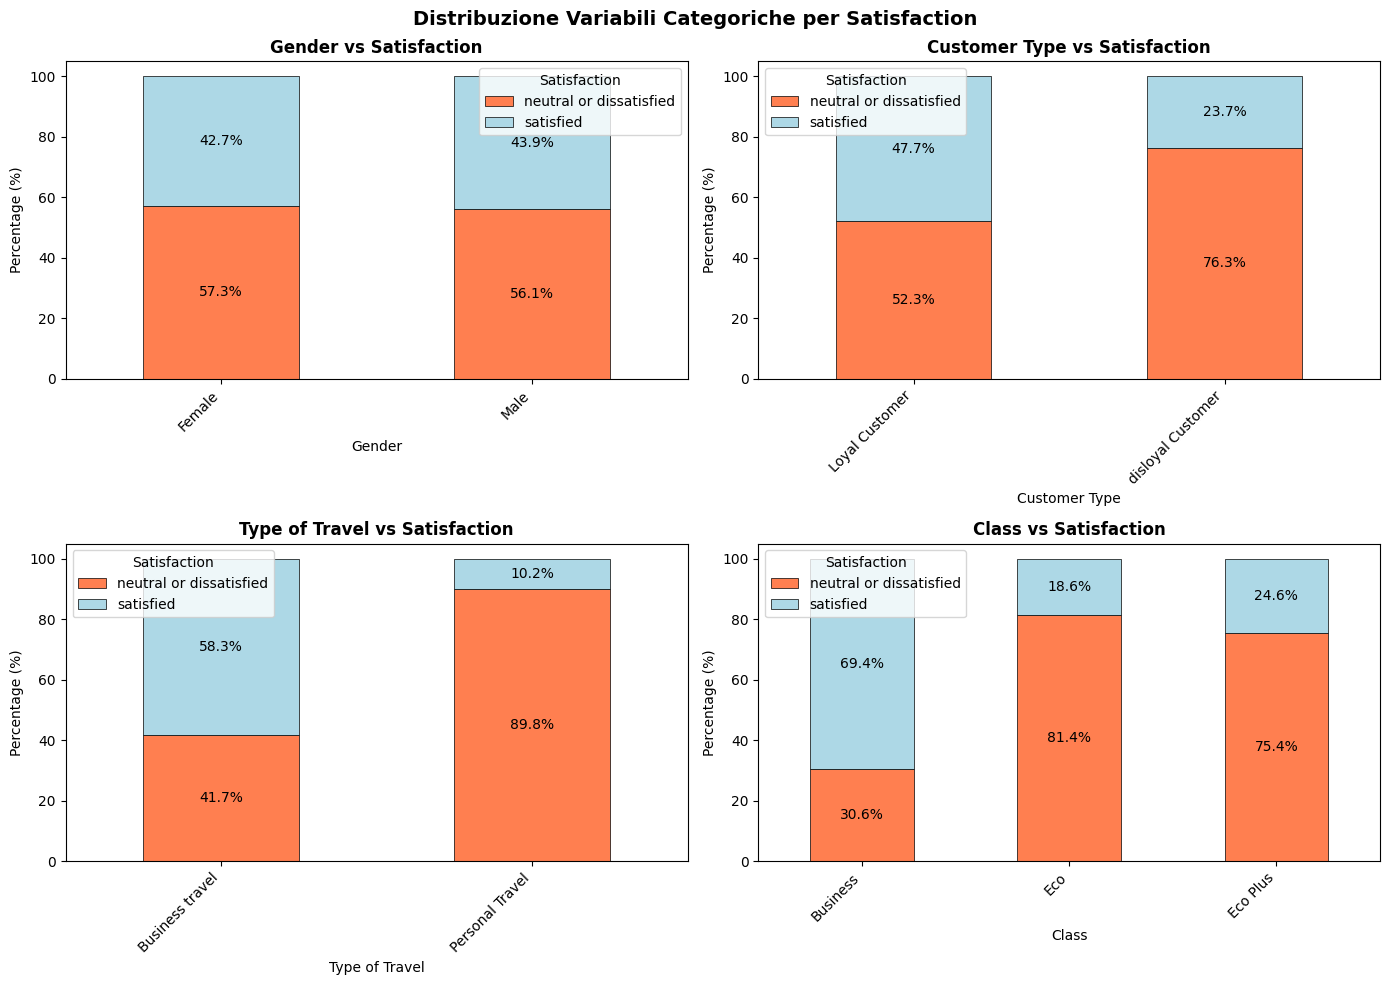


RACCOMANDAZIONI PER IL TRATTAMENTO DELLE CATEGORICHE:

1. ENCODING STRATEGY:
   • Gender: Usa Label Encoding (binaria)
   • Customer Type: Usa Label Encoding (binaria)
   • Type of Travel: Usa Label Encoding (binaria)
   • Class: Usa One-Hot Encoding (3 categorie)

2. FEATURE IMPORTANCE:
   Variabili categoriche significative (p<0.001): ['Gender', 'Customer Type', 'Type of Travel', 'Class']


In [39]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

# Identifica variabili categoriche
categorical_cols = ['Gender', 'Customer Type', 'Type of Travel', 'Class']

print("CATEGORICAL VARIABLES ANALYSIS:")
print("="*60)

# Analisi dettagliata per ogni variabile categorica
for col in categorical_cols:
    print(f"\n{col}:")
    print("-" * 30)
    
    # Conteggi e percentuali
    value_counts = raw_data_train[col].value_counts()
    value_percentages = raw_data_train[col].value_counts(normalize=True) * 100
    
    cat_summary = pd.DataFrame({
        'Count': value_counts,
        'Percentage': value_percentages.round(2)
    })
    
    print(cat_summary)
    print(f"Unique values: {raw_data_train[col].nunique()}")
    print(f"Missing values: {raw_data_train[col].isnull().sum()}")

print("\n" + "="*60)
print("STRATEGIA DI ENCODING CONSIGLIATA:")
print("="*60)

# Determina strategia di encoding basata sul numero di categorie
encoding_strategy = {}
for col in categorical_cols:
    n_unique = raw_data_train[col].nunique()
    if n_unique == 2:
        encoding_strategy[col] = "Label Encoding (Binary)"
    elif n_unique <= 5:
        encoding_strategy[col] = "One-Hot Encoding"
    else:
        encoding_strategy[col] = "Target Encoding or Embedding"
    
    print(f"{col}: {n_unique} categorie → {encoding_strategy[col]}")

print("\n" + "="*60)
print("IMPLEMENTAZIONE ENCODING:")
print("="*60)

# Crea una copia per preservare i dati originali
raw_data_encoded = raw_data_train.copy()

# 1. LABEL ENCODING per variabili binarie
binary_cols = [col for col in categorical_cols if raw_data_train[col].nunique() == 2]
le_dict = {}  # Dizionario per salvare i LabelEncoder per uso futuro

print("\n1. LABEL ENCODING (Variabili Binarie):")
print("-" * 30)

for col in binary_cols:
    le = LabelEncoder()
    raw_data_encoded[f'{col}_encoded'] = le.fit_transform(raw_data_train[col])
    le_dict[col] = le  # Salva l'encoder
    
    # Mostra il mapping
    mapping = dict(zip(le.classes_, le.transform(le.classes_)))
    print(f"\n{col}:")
    for original, encoded in mapping.items():
        count = (raw_data_train[col] == original).sum()
        pct = (count / len(raw_data_train)) * 100
        print(f"  '{original}' → {encoded} (n={count}, {pct:.1f}%)")

# 2. ONE-HOT ENCODING per variabili multi-classe
multi_class_cols = [col for col in categorical_cols if raw_data_train[col].nunique() > 2]

print("\n2. ONE-HOT ENCODING (Variabili Multi-classe):")
print("-" * 30)

for col in multi_class_cols:
    print(f"\n{col} ({raw_data_train[col].nunique()} categorie):")
    
    # Crea dummies
    dummies = pd.get_dummies(raw_data_train[col], prefix=col, drop_first=False)
    
    # Mostra le nuove colonne create
    print(f"  Nuove colonne create: {list(dummies.columns)}")
    
    # Statistiche per ogni dummy
    for dummy_col in dummies.columns:
        count = dummies[dummy_col].sum()
        pct = (count / len(raw_data_train)) * 100
        print(f"    {dummy_col}: {count} records ({pct:.1f}%)")
    
    # Aggiungi al dataframe encoded (opzionale, per dimostrazione)
    raw_data_encoded = pd.concat([raw_data_encoded, dummies], axis=1)

# 3. ANALISI DELL'IMPATTO SULL'ESPANSIONE DELLE FEATURES
print("\n" + "="*60)
print("IMPATTO DELL'ENCODING SUL DATASET:")
print("="*60)

original_cols = len(raw_data_train.columns)
after_encoding_cols = len(raw_data_encoded.columns)
new_cols = after_encoding_cols - original_cols

print(f"Colonne originali: {original_cols}")
print(f"Colonne dopo encoding: {after_encoding_cols}")
print(f"Nuove colonne create: {new_cols}")

# 4. VERIFICA CORRELAZIONE TRA CATEGORICHE E TARGET
print("\n" + "="*60)
print("CORRELAZIONE CATEGORICHE CON TARGET:")
print("="*60)

from scipy.stats import chi2_contingency

for col in categorical_cols:
    # Crea tabella di contingenza
    contingency_table = pd.crosstab(raw_data_train[col], raw_data_train['satisfaction'])
    
    # Test Chi-quadrato
    chi2, p_value, dof, expected = chi2_contingency(contingency_table)
    
    # Calcola Cramér's V per misurare la forza dell'associazione
    n = contingency_table.sum().sum()
    min_dim = min(contingency_table.shape) - 1
    cramers_v = np.sqrt(chi2 / (n * min_dim))
    
    print(f"\n{col}:")
    print(f"  Chi-square: {chi2:.2f}")
    print(f"  P-value: {p_value:.4f}")
    print(f"  Cramér's V: {cramers_v:.3f}", end=" ")
    
    # Interpretazione della forza dell'associazione
    if cramers_v < 0.1:
        strength = "(molto debole)"
    elif cramers_v < 0.3:
        strength = "(debole)"
    elif cramers_v < 0.5:
        strength = "(moderata)"
    else:
        strength = "(forte)"
    print(strength)

# 5. VISUALIZZAZIONE DISTRIBUZIONE CATEGORICHE PER TARGET
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for idx, col in enumerate(categorical_cols):
    ax = axes[idx]
    
    # Crea DataFrame per plotting
    plot_data = raw_data_train.groupby([col, 'satisfaction']).size().unstack()
    
    # Calcola percentuali per riga
    plot_data_pct = plot_data.div(plot_data.sum(axis=1), axis=0) * 100
    
    # Crea stacked bar plot
    plot_data_pct.plot(kind='bar', stacked=True, ax=ax, 
                       color=['coral', 'lightblue'],
                       edgecolor='black', linewidth=0.5)
    
    ax.set_title(f'{col} vs Satisfaction', fontsize=12, fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Percentage (%)')
    ax.legend(title='Satisfaction', loc='best')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
    
    # Aggiungi percentuali sulle barre
    for container in ax.containers:
        ax.bar_label(container, fmt='%.1f%%', label_type='center')

plt.suptitle('Distribuzione Variabili Categoriche per Satisfaction', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 6. RACCOMANDAZIONI FINALI
print("\n" + "="*60)
print("RACCOMANDAZIONI PER IL TRATTAMENTO DELLE CATEGORICHE:")
print("="*60)

print("\n1. ENCODING STRATEGY:")
for col in categorical_cols:
    if col in binary_cols:
        print(f"   • {col}: Usa Label Encoding (binaria)")
    else:
        print(f"   • {col}: Usa One-Hot Encoding ({raw_data_train[col].nunique()} categorie)")

print("\n2. FEATURE IMPORTANCE:")
important_cats = []
for col in categorical_cols:
    contingency_table = pd.crosstab(raw_data_train[col], raw_data_train['satisfaction'])
    chi2, p_value, _, _ = chi2_contingency(contingency_table)
    if p_value < 0.001:
        important_cats.append(col)

print(f"   Variabili categoriche significative (p<0.001): {important_cats}")

In [40]:
raw_data_encoded

,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction,Gender_encoded,Customer Type_encoded,Type of Travel_encoded,Class_Business,Class_Eco,Class_Eco Plus
0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,5,3,5,5,4,3,4,4,5,5,25,18.000,neutral or dissatisfied,1,0,1,False,False,True
1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,1,3,1,1,1,5,3,1,4,1,1,6.000,neutral or dissatisfied,1,1,0,True,False,False
2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,5,5,5,5,4,3,4,4,4,5,0,0.000,satisfied,0,0,0,True,False,False
3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,2,2,2,2,2,5,3,1,4,2,11,9.000,neutral or dissatisfied,0,0,0,True,False,False
4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,4,5,5,3,3,4,4,3,3,3,0,0.000,satisfied,1,0,0,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103899,94171,Female,disloyal Customer,23,Business travel,Eco,192,2,1,2,3,2,2,2,2,3,1,4,2,3,2,3,0.000,neutral or dissatisfied,0,1,0,False,True,False
103900,73097,Male,Loyal Customer,49,Business travel,Business,2347,4,4,4,4,2,4,5,5,5,5,5,5,5,4,0,0.000,satisfied,1,0,0,True,False,False
103901,68825,Male,disloyal Customer,30,Business travel,Business,1995,1,1,1,3,4,1,5,4,3,2,4,5,5,4,7,14.000,neutral or dissatisfied,1,1,0,True,False,False
103902,54173,Female,disloyal Customer,22,Business travel,Eco,1000,1,1,1,5,1,1,1,1,4,5,1,5,4,1,0,0.000,neutral or dissatisfied,0,1,0,False,True,False


## 2.7 Gestione dello zero nei rating

Il caso del Wi-Fi è documentato nella [scheda del dataset](https://www.kaggle.com/datasets/teejmahal20/airline-passenger-satisfaction): `0 = Not Applicable`. Nel train osservo anche un tasso di soddisfazione elevato fra questi record; quel tasso non è, da solo, una prova del significato del codice.

Per gli altri rating dichiaro un'**ipotesi di trattamento comune**, da confermare con un dizionario più completo: interpreto lo zero separatamente dalla scala 1–5. Nella Strada 1:

1. creo una flag per i rating che contengono zeri nel campione di addestramento;
2. sostituisco gli zeri con mancanti e imputo la mediana dei valori osservati 1–5;
3. mantengo le flag separatamente, senza scalarle.

Qui mostro il procedimento sull'intero train per comprenderlo. Nella CV viene riappreso solo sul training del fold. Nella Strada 2 mantengo esattamente quattro colonne numeriche: applico l'imputazione ma non aggiungo flag. Questa scelta rispetta il vincolo della traccia e rinuncia esplicitamente all'informazione separata sullo zero.

In [41]:
# ============================================================
# 2.7 - GESTIONE DEI RATING == 0 COME "NON APPLICABILE"
# ============================================================
print("GESTIONE RATING == 0")
print("=" * 60)

# Lista dei rating su scala 0-5 (tutti quelli che ho ispezionato nell'EDA)
rating_features_all = [
    'Inflight wifi service', 'Departure/Arrival time convenient',
    'Ease of Online booking', 'Gate location', 'Food and drink',
    'Online boarding', 'Seat comfort', 'Inflight entertainment',
    'On-board service', 'Leg room service', 'Baggage handling',
    'Checkin service', 'Inflight service', 'Cleanliness'
]

# Identifico solo le feature per cui lo zero è plausibilmente "non applicabile":
# tengo quelle che hanno almeno un record con valore == 0
zero_features = [c for c in rating_features_all if (raw_data_train[c] == 0).any()]

print(f"Feature con almeno un rating == 0: {len(zero_features)}")
for c in zero_features:
    n_zero = int((raw_data_train[c] == 0).sum())
    pct = n_zero / len(raw_data_train) * 100
    print(f"  {c:40s} -> {n_zero:>5d} zeri ({pct:.2f}%)")

# Creo una versione "pulita" del training set:
#   1) flag binarie *_zeroflag
#   2) 0 -> NaN -> imputazione con mediana dei rating 1-5
raw_data_train_clean = raw_data_train.copy()
zero_flag_cols = []
median_imputation_map = {}

for c in zero_features:
    flag_name = f"{c}_zeroflag"
    raw_data_train_clean[flag_name] = (raw_data_train_clean[c] == 0).astype(int)
    zero_flag_cols.append(flag_name)

    # mediana calcolata SOLO sui valori 1-5 del training set
    median_val = raw_data_train_clean.loc[raw_data_train_clean[c] > 0, c].median()
    median_imputation_map[c] = median_val

    raw_data_train_clean[c] = raw_data_train_clean[c].replace(0, np.nan)
    raw_data_train_clean[c] = raw_data_train_clean[c].fillna(median_val)

print("\nNuove flag create:")
print(zero_flag_cols)

print("\nMappa di imputazione (mediana 1-5 del train):")
for c, v in median_imputation_map.items():
    print(f"  {c:40s} -> {v}")

# Verifica: nessun rating dovrebbe valere 0 nel dataset pulito
remaining_zeros = sum((raw_data_train_clean[c] == 0).sum() for c in zero_features)
print(f"\nRating con valore 0 dopo la pulizia: {remaining_zeros}")


GESTIONE RATING == 0
Feature con almeno un rating == 0: 13
  Inflight wifi service                    ->  3103 zeri (2.99%)
  Departure/Arrival time convenient        ->  5300 zeri (5.10%)
  Ease of Online booking                   ->  4487 zeri (4.32%)
  Gate location                            ->     1 zeri (0.00%)
  Food and drink                           ->   107 zeri (0.10%)
  Online boarding                          ->  2428 zeri (2.34%)
  Seat comfort                             ->     1 zeri (0.00%)
  Inflight entertainment                   ->    14 zeri (0.01%)
  On-board service                         ->     3 zeri (0.00%)
  Leg room service                         ->   472 zeri (0.45%)
  Checkin service                          ->     1 zeri (0.00%)
  Inflight service                         ->     3 zeri (0.00%)
  Cleanliness                              ->    12 zeri (0.01%)

Nuove flag create:
['Inflight wifi service_zeroflag', 'Departure/Arrival time convenient_zerofl

## 2.8 Standardizzazione delle Features

STANDARDIZZAZIONE DELLE FEATURES

1. IDENTIFICAZIONE FEATURES:
------------------------------
Features continue: 4
  → ['Age', 'Flight Distance', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']

Features rating (0-5): 14
  → ['Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Inflight service', 'Cleanliness']

Features categoriche (NON scalare): 4
  → ['Gender', 'Customer Type', 'Type of Travel', 'Class']

Totale features da scalare: 18

2. ANALISI DISTRIBUZIONE PRE-SCALING:
------------------------------



Statistiche principali (subset di features):
                                       Mean     Std    Min       Max     Range
Age                                  39.380  15.110  7.000    85.000    78.000
Flight Distance                   1,189.450 997.150 31.000 4,983.000 4,952.000
Departure Delay in Minutes           14.820  38.230  0.000 1,592.000 1,592.000
Arrival Delay in Minutes             15.180  38.700  0.000 1,584.000 1,584.000
Inflight wifi service                 2.730   1.330  0.000     5.000     5.000
Departure/Arrival time convenient     3.060   1.530  0.000     5.000     5.000

3. PROBLEMI DI SCALA IDENTIFICATI:
------------------------------
Range massimo: 4952.00 (feature: Flight Distance)
Range minimo: 4.00 (feature: Baggage handling)
Rapporto max/min range: 1238.0x
⚠️ FORTE DIFFERENZA DI SCALA - Scaling utile per i modelli sensibili alla scala (es. Logistic Regression).

4. CONFRONTO METODI DI SCALING:
------------------------------

Gestione valori mancanti prima de


5. RISULTATI SCALING:
------------------------------

Confronto metodi (prime 5 features):
                            Original_Mean  Original_Std  Standard_Mean  Standard_Std  MinMax_Min  MinMax_Max  \
Age                                39.380        15.115          0.000         1.000       0.000       1.000   
Flight Distance                 1,189.448       997.147          0.000         1.000       0.000       1.000   
Departure Delay in Minutes         14.816        38.231         -0.000         1.000       0.000       1.000   
Arrival Delay in Minutes           15.179        38.699          0.000         1.000       0.000       1.000   
Inflight wifi service               2.730         1.328          0.000         1.000       0.000       1.000   

                            Robust_Median  
Age                                 0.000  
Flight Distance                     0.000  
Departure Delay in Minutes          0.000  
Arrival Delay in Minutes            0.000  
Inflight wifi s

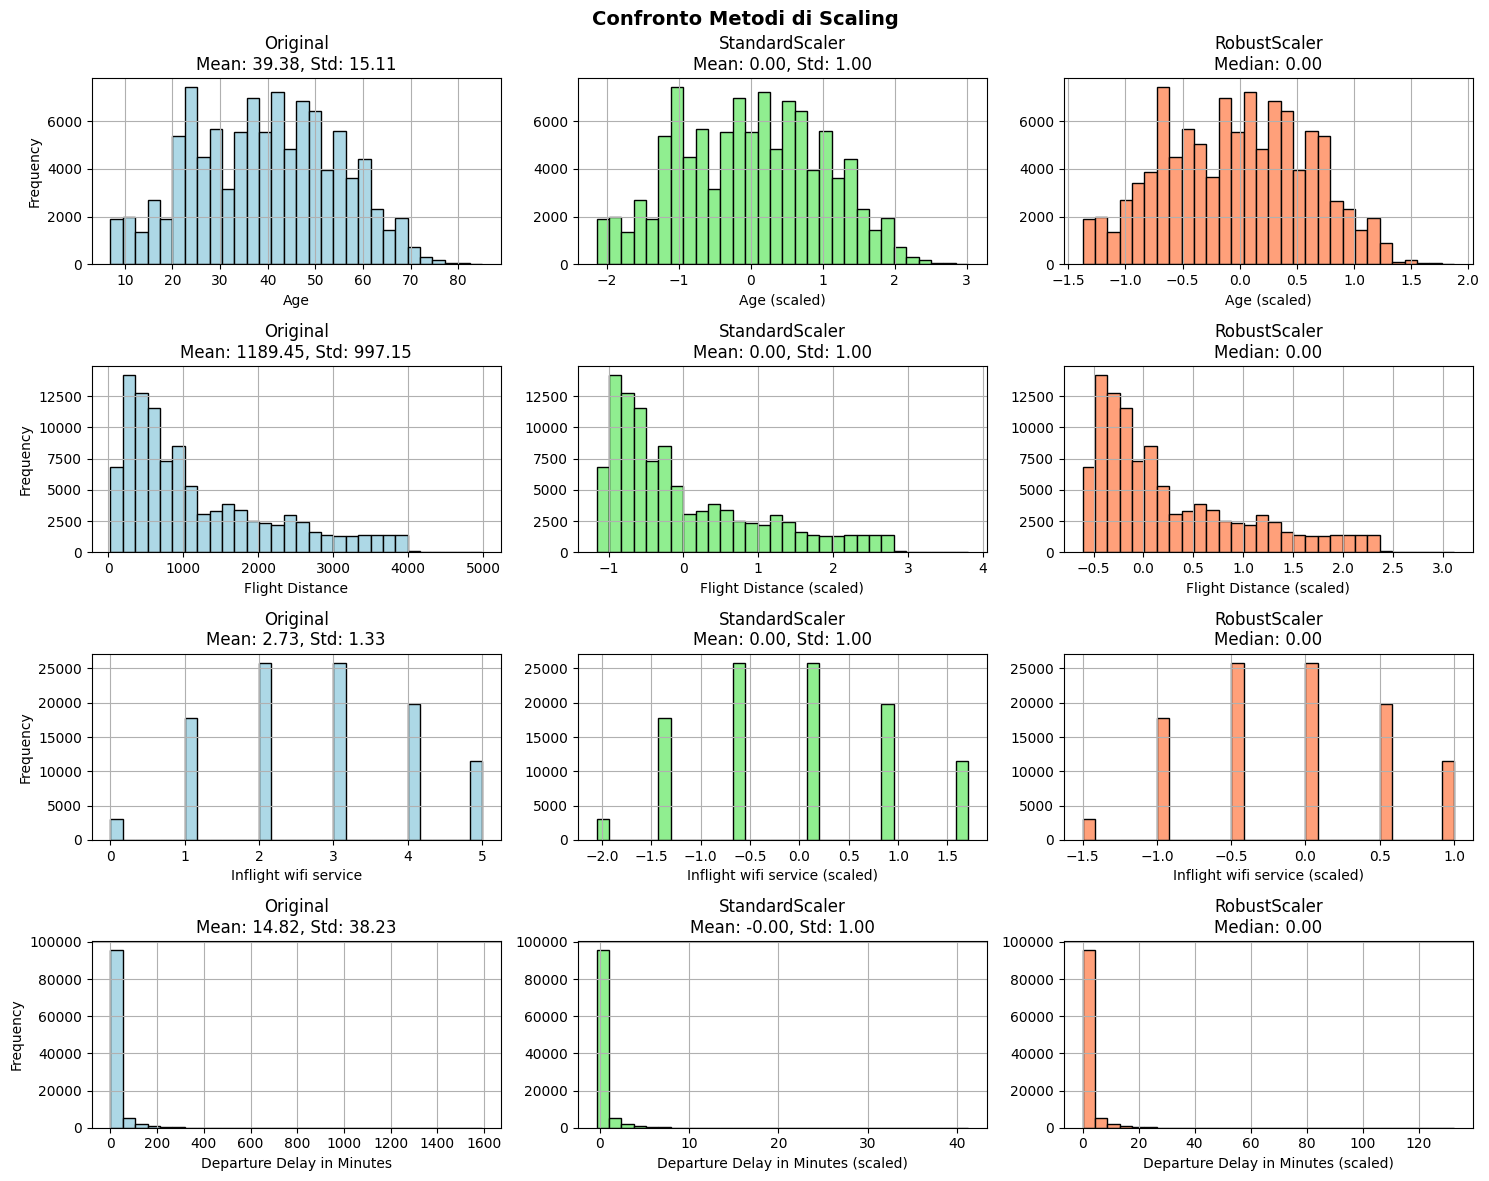


8. IMPATTO OUTLIER SULLO SCALING:
------------------------------

Departure Delay in Minutes:
  Outlier: 14.0%
  StandardScaler range: [-0.39, 41.25]
  RobustScaler range: [0.00, 132.67]
  → Raccomandazione: RobustScaler (resistente a outlier)

Arrival Delay in Minutes:
  Outlier: 13.5%
  StandardScaler range: [-0.39, 40.59]
  RobustScaler range: [0.00, 121.85]
  → Raccomandazione: RobustScaler (resistente a outlier)

APPLICAZIONE FINALE:
------------------------------
✓ Dataset scalato creato: raw_data_train_scaled
  Features scalate: 18
  Features non scalate: 6


In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
import warnings

print("STANDARDIZZAZIONE DELLE FEATURES")
print("="*60)

# 1. IDENTIFICAZIONE DELLE FEATURES DA SCALARE
print("\n1. IDENTIFICAZIONE FEATURES:")
print("-" * 30)

# Identifica diversi tipi di features
# a) Features numeriche continue
continuous_features = ['Age', 'Flight Distance', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']

# b) Features di rating (0-5)
rating_features = [col for col in raw_data_train.columns 
                  if any(keyword in col.lower() for keyword in 
                  ['service', 'comfort', 'boarding', 'handling', 
                   'cleanliness', 'entertainment', 'wifi', 'convenient', 
                   'booking', 'location', 'food'])]

# c) Features categoriche (da NON scalare)
categorical_features = ['Gender', 'Customer Type', 'Type of Travel', 'Class']

# d) Features da escludere
exclude_features = ['id', 'satisfaction']

# Features totali da scalare
features_to_scale = continuous_features + rating_features

print(f"Features continue: {len(continuous_features)}")
print(f"  → {continuous_features}")
print(f"\nFeatures rating (0-5): {len(rating_features)}")
print(f"  → {rating_features}")
print(f"\nFeatures categoriche (NON scalare): {len(categorical_features)}")
print(f"  → {categorical_features}")
print(f"\nTotale features da scalare: {len(features_to_scale)}")

# 2. ANALISI PRE-SCALING
print("\n" + "="*60)
print("2. ANALISI DISTRIBUZIONE PRE-SCALING:")
print("-" * 30)

# Statistiche descrittive prima dello scaling
pre_scaling_stats = raw_data_train[features_to_scale].describe()

print("\nStatistiche principali (subset di features):")
sample_features = continuous_features + rating_features[:2]  # Mostra solo alcune per leggibilità

stats_summary = pd.DataFrame({
    'Mean': raw_data_train[sample_features].mean(),
    'Std': raw_data_train[sample_features].std(),
    'Min': raw_data_train[sample_features].min(),
    'Max': raw_data_train[sample_features].max(),
    'Range': raw_data_train[sample_features].max() - raw_data_train[sample_features].min()
})

print(stats_summary.round(2))

# Identificazione problemi di scala
print("\n" + "="*60)
print("3. PROBLEMI DI SCALA IDENTIFICATI:")
print("-" * 30)

# Calcola il rapporto tra i range
ranges = raw_data_train[features_to_scale].max() - raw_data_train[features_to_scale].min()
max_range = ranges.max()
min_range = ranges.min()

print(f"Range massimo: {max_range:.2f} (feature: {ranges.idxmax()})")
print(f"Range minimo: {min_range:.2f} (feature: {ranges.idxmin()})")
print(f"Rapporto max/min range: {max_range/min_range:.1f}x")

if max_range/min_range > 10:
    print("⚠️ FORTE DIFFERENZA DI SCALA - Scaling utile per i modelli sensibili alla scala (es. Logistic Regression).")
else:
    print("✓ Differenze di scala moderate")

# 3. CONFRONTO TRA METODI DI SCALING
print("\n" + "="*60)
print("4. CONFRONTO METODI DI SCALING:")
print("-" * 30)

# Crea copie del dataset per diversi metodi
data_standard = raw_data_train.copy()
data_minmax = raw_data_train.copy()
data_robust = raw_data_train.copy()

# Gestisci valori mancanti prima dello scaling
print("\nGestione valori mancanti prima dello scaling:")
missing_in_scale = raw_data_train[features_to_scale].isnull().sum()
if missing_in_scale.sum() > 0:
    print(f"  Trovati {missing_in_scale.sum()} valori mancanti")
    print("  → Imputazione con mediana per robustezza")
    for feature in features_to_scale:
        median_val = raw_data_train[feature].median()
        data_standard[feature] = data_standard[feature].fillna(median_val)
        data_minmax[feature] = data_minmax[feature].fillna(median_val)
        data_robust[feature] = data_robust[feature].fillna(median_val)
else:
    print("  ✓ Nessun valore mancante nelle features da scalare")

# Applica diversi scaler
scaler_standard = StandardScaler()
scaler_minmax = MinMaxScaler()
scaler_robust = RobustScaler()

data_standard[features_to_scale] = scaler_standard.fit_transform(data_standard[features_to_scale])
data_minmax[features_to_scale] = scaler_minmax.fit_transform(data_minmax[features_to_scale])
data_robust[features_to_scale] = scaler_robust.fit_transform(data_robust[features_to_scale])

# Confronto risultati
print("\n" + "="*60)
print("5. RISULTATI SCALING:")
print("-" * 30)

scaling_comparison = pd.DataFrame({
    'Original_Mean': raw_data_train[features_to_scale].mean(),
    'Original_Std': raw_data_train[features_to_scale].std(),
    'Standard_Mean': data_standard[features_to_scale].mean(),
    'Standard_Std': data_standard[features_to_scale].std(),
    'MinMax_Min': data_minmax[features_to_scale].min(),
    'MinMax_Max': data_minmax[features_to_scale].max(),
    'Robust_Median': data_robust[features_to_scale].median()
})

print("\nConfronto metodi (prime 5 features):")
print(scaling_comparison.head().round(3))

# Verifica qualità dello StandardScaler
print("\n" + "="*60)
print("6. VERIFICA STANDARD SCALER:")
print("-" * 30)

mean_after = data_standard[features_to_scale].mean().mean()
std_after = data_standard[features_to_scale].std().mean()

print(f"Media globale dopo StandardScaler: {mean_after:.6f} (atteso: ~0)")
print(f"Deviazione standard media dopo StandardScaler: {std_after:.6f} (atteso: ~1)")

if abs(mean_after) < 0.001 and abs(std_after - 1) < 0.01:
    print("✓ StandardScaler applicato correttamente!")
else:
    print("⚠️ Verificare l'applicazione dello StandardScaler")

# 4. VISUALIZZAZIONE DISTRIBUZIONE PRE E POST SCALING
print("\n" + "="*60)
print("7. VISUALIZZAZIONE IMPATTO SCALING:")
print("-" * 30)

# Seleziona features rappresentative per la visualizzazione
viz_features = ['Age', 'Flight Distance', 'Inflight wifi service', 'Departure Delay in Minutes']

fig, axes = plt.subplots(len(viz_features), 3, figsize=(15, len(viz_features)*3))

for idx, feature in enumerate(viz_features):
    # Original
    ax1 = axes[idx, 0]
    raw_data_train[feature].dropna().hist(bins=30, ax=ax1, color='lightblue', edgecolor='black')
    ax1.set_title(f'Original\nMean: {raw_data_train[feature].mean():.2f}, Std: {raw_data_train[feature].std():.2f}')
    ax1.set_xlabel(feature)
    ax1.set_ylabel('Frequency')
    
    # StandardScaler
    ax2 = axes[idx, 1]
    data_standard[feature].hist(bins=30, ax=ax2, color='lightgreen', edgecolor='black')
    ax2.set_title(f'StandardScaler\nMean: {data_standard[feature].mean():.2f}, Std: {data_standard[feature].std():.2f}')
    ax2.set_xlabel(f'{feature} (scaled)')
    
    # RobustScaler
    ax3 = axes[idx, 2]
    data_robust[feature].hist(bins=30, ax=ax3, color='lightsalmon', edgecolor='black')
    ax3.set_title(f'RobustScaler\nMedian: {data_robust[feature].median():.2f}')
    ax3.set_xlabel(f'{feature} (scaled)')

plt.suptitle('Confronto Metodi di Scaling', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 5. ANALISI IMPATTO OUTLIER SULLO SCALING
print("\n" + "="*60)
print("8. IMPATTO OUTLIER SULLO SCALING:")
print("-" * 30)

# Confronta scaling su features con molti outlier (Delay features)
outlier_features = ['Departure Delay in Minutes', 'Arrival Delay in Minutes']

for feature in outlier_features:
    if feature in features_to_scale:
        original_data = raw_data_train[feature].dropna()
        
        # Calcola percentuale di outlier (IQR method)
        Q1 = original_data.quantile(0.25)
        Q3 = original_data.quantile(0.75)
        IQR = Q3 - Q1
        outliers = ((original_data < Q1 - 1.5*IQR) | (original_data > Q3 + 1.5*IQR)).sum()
        outlier_pct = (outliers / len(original_data)) * 100
        
        print(f"\n{feature}:")
        print(f"  Outlier: {outlier_pct:.1f}%")
        print(f"  StandardScaler range: [{data_standard[feature].min():.2f}, {data_standard[feature].max():.2f}]")
        print(f"  RobustScaler range: [{data_robust[feature].min():.2f}, {data_robust[feature].max():.2f}]")
        
        if outlier_pct > 5:
            print(f"  → Raccomandazione: RobustScaler (resistente a outlier)")
        else:
            print(f"  → Raccomandazione: StandardScaler (distribuzione normale)")



# Applica effettivamente lo StandardScaler al dataset
print("\n" + "="*60)
print("APPLICAZIONE FINALE:")
print("-" * 30)

# Crea il dataset finale scalato
raw_data_train_scaled = raw_data_train.copy()

# Imputa valori mancanti con mediana
for feature in features_to_scale:
    if raw_data_train_scaled[feature].isnull().sum() > 0:
        median_val = raw_data_train_scaled[feature].median()
        raw_data_train_scaled[feature] = raw_data_train_scaled[feature].fillna(median_val)

# Applica StandardScaler
final_scaler = StandardScaler()
raw_data_train_scaled[features_to_scale] = final_scaler.fit_transform(raw_data_train_scaled[features_to_scale])

print(f"✓ Dataset scalato creato: raw_data_train_scaled")
print(f"  Features scalate: {len(features_to_scale)}")
print(f"  Features non scalate: {len(raw_data_train.columns) - len(features_to_scale)}")

# Dimostrazione EDA: lo scaler isolato non viene esportato.
# L'artefatto finale conterrà la pipeline completa, imputazione compresa.


### Scaling finale: strategia mista

Mantengo **RobustScaler** per i due ritardi e **StandardScaler** per le altre 16 numeriche: Age, Flight Distance e 14 rating. Le flag restano 0/1; target e identificativi non sono scalati né usati come feature.

La cella seguente è una dimostrazione sull'intero train. Nella sezione di modellazione ricostruisco questa logica in una Pipeline: ogni fold apprende i propri parametri, poi li applica alla propria validazione. Il modello finale li apprende sul train completo e li applica al test senza rifit.

In [43]:
# ============================================================
# SCALING FINALE - STRATEGIA MISTA (Robust + Standard)
# ============================================================
print("SCALING FINALE - STRATEGIA MISTA")
print("=" * 60)

# Feature suddivise per scaler
robust_features = ['Departure Delay in Minutes', 'Arrival Delay in Minutes']
standard_features = [
    'Age', 'Flight Distance',
    'Inflight wifi service', 'Departure/Arrival time convenient',
    'Ease of Online booking', 'Gate location', 'Food and drink',
    'Online boarding', 'Seat comfort', 'Inflight entertainment',
    'On-board service', 'Leg room service', 'Baggage handling',
    'Checkin service', 'Inflight service', 'Cleanliness'
]

# Parto da raw_data_train_clean (con i 0->NaN->mediana e le _zeroflag gia' create)
# Imputo eventuali NaN residui (Arrival Delay in Minutes) con la mediana di train
raw_data_train_scaled = raw_data_train_clean.copy()
for col in robust_features + standard_features:
    if raw_data_train_scaled[col].isnull().sum() > 0:
        med = raw_data_train_scaled[col].median()
        raw_data_train_scaled[col] = raw_data_train_scaled[col].fillna(med)

# Fitting separato dei due scaler (solo su training)
robust_scaler  = RobustScaler()
standard_scaler = StandardScaler()

raw_data_train_scaled[robust_features]   = robust_scaler.fit_transform(raw_data_train_scaled[robust_features])
raw_data_train_scaled[standard_features] = standard_scaler.fit_transform(raw_data_train_scaled[standard_features])

# Sostituisco il vecchio final_scaler con un contenitore dei due scaler
final_scaler = {
    "robust": robust_scaler,
    "standard": standard_scaler,
    "robust_features": robust_features,
    "standard_features": standard_features,
    "zero_flag_cols": zero_flag_cols,
    "median_imputation_map": median_imputation_map,
}

# Aggiorno la lista features_to_scale per coerenza con il resto del notebook
features_to_scale = robust_features + standard_features

print(f"RobustScaler applicato a:  {robust_features}")
print(f"StandardScaler applicato a {len(standard_features)} feature numeriche.")
print(f"Zero-flag aggiunte come passthrough: {len(zero_flag_cols)} colonne.")

# Verifica numerica
check = pd.DataFrame({
    "feature": features_to_scale,
    "mean_after":   raw_data_train_scaled[features_to_scale].mean().round(4).values,
    "std_after":    raw_data_train_scaled[features_to_scale].std().round(4).values,
    "median_after": raw_data_train_scaled[features_to_scale].median().round(4).values,
})
print("\nVerifica statistiche dopo scaling (RobustScaler -> mediana 0; StandardScaler -> media 0, std 1):")
print(check.to_string(index=False))


SCALING FINALE - STRATEGIA MISTA
RobustScaler applicato a:  ['Departure Delay in Minutes', 'Arrival Delay in Minutes']
StandardScaler applicato a 16 feature numeriche.
Zero-flag aggiunte come passthrough: 13 colonne.

Verifica statistiche dopo scaling (RobustScaler -> mediana 0; StandardScaler -> media 0, std 1):
                          feature  mean_after  std_after  median_after
       Departure Delay in Minutes       1.235      3.186         0.000
         Arrival Delay in Minutes       1.164      2.973         0.000
                              Age       0.000      1.000         0.041
                  Flight Distance       0.000      1.000        -0.347
            Inflight wifi service       0.000      1.000         0.146
Departure/Arrival time convenient      -0.000      1.000        -0.158
           Ease of Online booking       0.000      1.000         0.089
                    Gate location       0.000      1.000         0.018
                   Food and drink      -0.000 

## 2.9 Bilanciamento del Dataset

ANALISI BILANCIAMENTO TARGET

Distribuzione del target:
  neutral or dissatisfied: 58879 (56.7%)
  satisfied: 45025 (43.3%)

Rapporto maggioranza/minoranza: 1.31


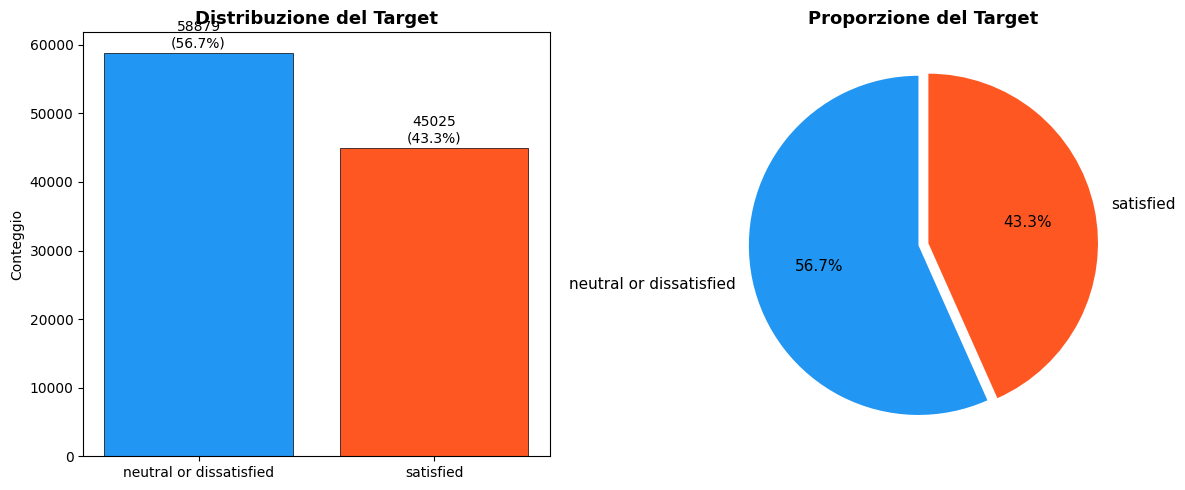


CONCLUSIONE:
Il dataset e' moderatamente sbilanciato (~43% satisfied vs ~57% dissatisfied).
Con un rapporto di ~1.3:1, non e' necessario applicare tecniche di ricampionamento
(SMOTE, undersampling, ecc.). L'accuracy resta una metrica affidabile.


In [44]:
# Analisi del bilanciamento del target
print("ANALISI BILANCIAMENTO TARGET")
print("=" * 60)

target_counts = raw_data_train["satisfaction"].value_counts()
target_pct = raw_data_train["satisfaction"].value_counts(normalize=True) * 100

print(f"\nDistribuzione del target:")
for label, count in target_counts.items():
    print(f"  {label}: {count} ({target_pct[label]:.1f}%)")

ratio = target_pct.max() / target_pct.min()
print(f"\nRapporto maggioranza/minoranza: {ratio:.2f}")

# Visualizzazione
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bar plot
colors = ['#2196F3', '#FF5722']
bars = axes[0].bar(target_counts.index, target_counts.values, color=colors, edgecolor='black', linewidth=0.5)
axes[0].set_title("Distribuzione del Target", fontsize=13, fontweight='bold')
axes[0].set_ylabel("Conteggio")
for bar, count, pct in zip(bars, target_counts.values, target_pct.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 300,
                 f'{count}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=10)

# Pie chart
axes[1].pie(target_counts.values, labels=target_counts.index, autopct='%1.1f%%',
            colors=colors, startangle=90, explode=[0.03, 0.03],
            textprops={'fontsize': 11})
axes[1].set_title("Proporzione del Target", fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

print("\nCONCLUSIONE:")
print("Il dataset e' moderatamente sbilanciato (~43% satisfied vs ~57% dissatisfied).")
print("Con un rapporto di ~1.3:1, non e' necessario applicare tecniche di ricampionamento")
print("(SMOTE, undersampling, ecc.). L'accuracy resta una metrica affidabile.")

Il dataset presenta uno sbilanciamento moderato tra le due classi target: circa il 43% dei passeggeri risulta `satisfied` e il 57% `neutral or dissatisfied`. Con un rapporto maggioranza/minoranza di circa 1.3:1, non si rende necessario l'uso di tecniche di ricampionamento (SMOTE, undersampling). L'accuracy può essere usata come metrica principale, affiancata da precision, recall e F1-score per completezza.

## 2.10 Correlazione tra Features

ANALISI CORRELAZIONE TRA FEATURES


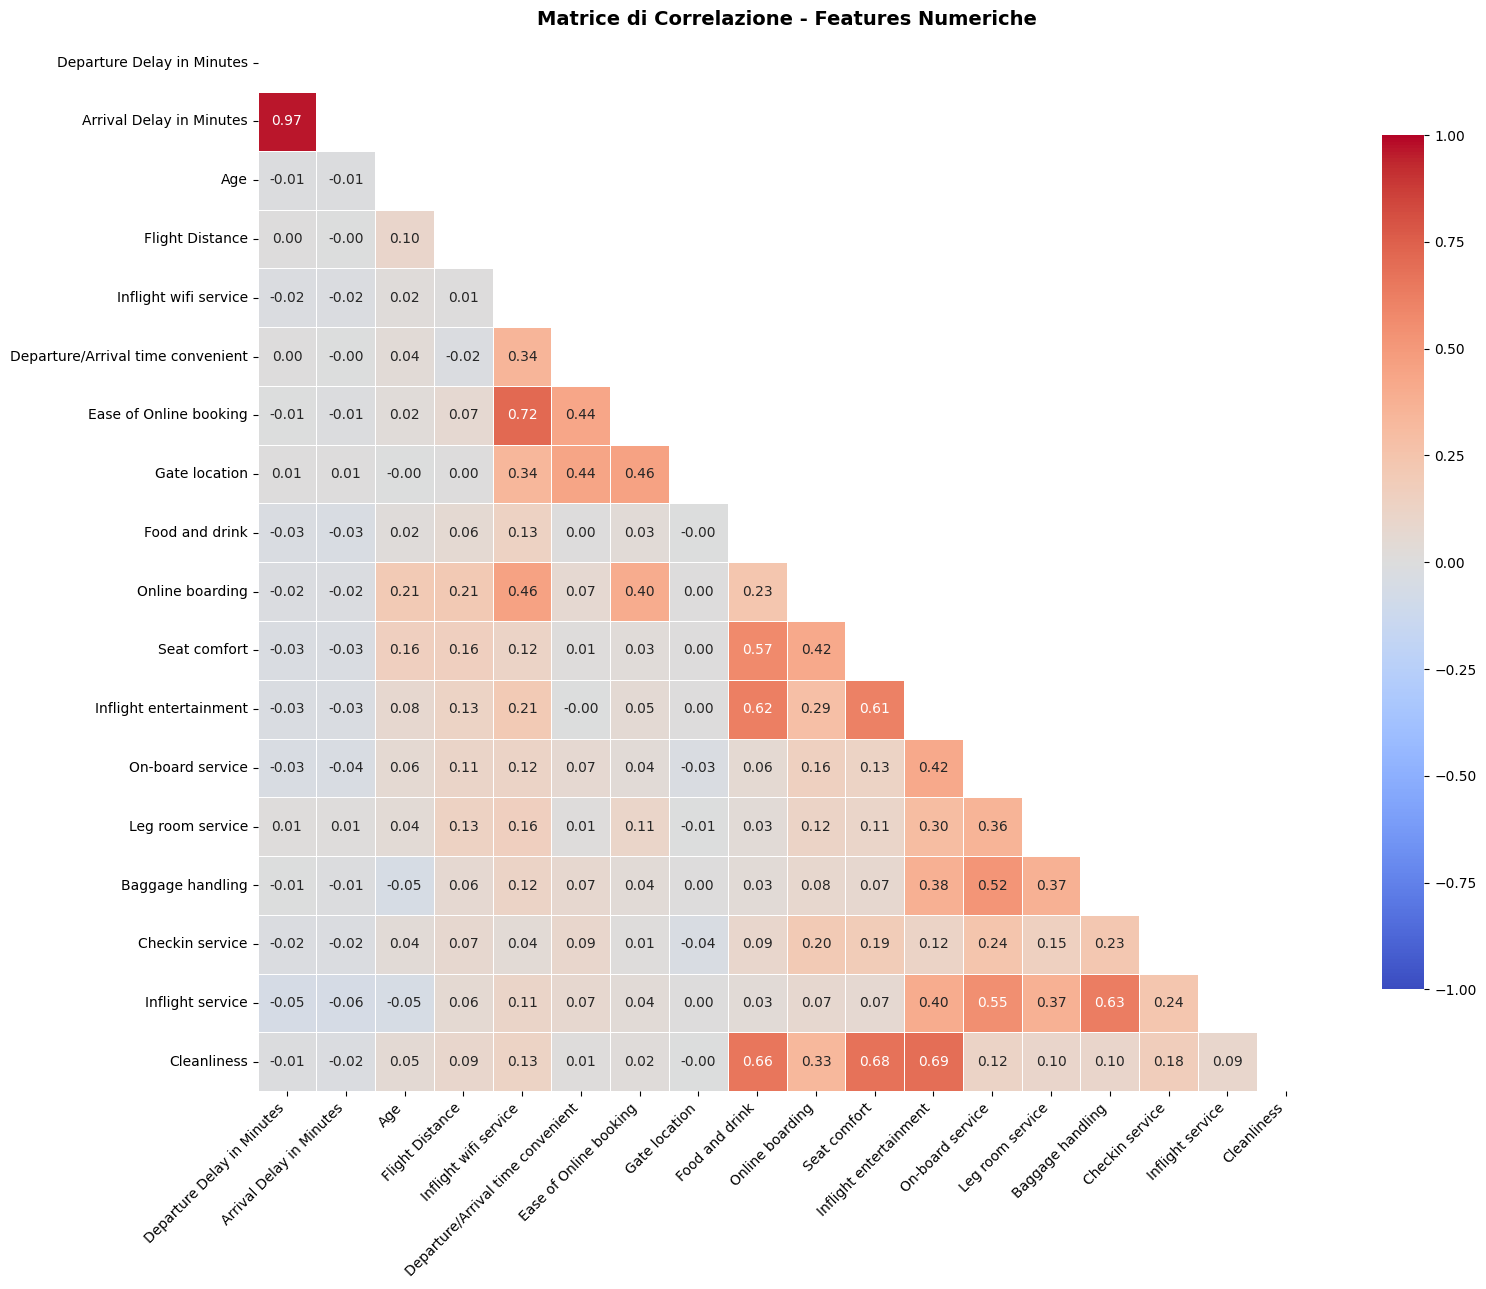


COPPIE CON ALTA CORRELAZIONE (|r| > 0.7):
--------------------------------------------------
  Departure Delay in Minutes <-> Arrival Delay in Minutes: r = 0.9655
  Inflight wifi service <-> Ease of Online booking: r = 0.7159


CORRELAZIONE FEATURES vs TARGET:
--------------------------------------------------
  Online boarding                          +0.504  ++++++++++++++++++++
  Inflight entertainment                   +0.398  +++++++++++++++
  Seat comfort                             +0.349  +++++++++++++
  On-board service                         +0.322  ++++++++++++
  Leg room service                         +0.313  ++++++++++++
  Cleanliness                              +0.305  ++++++++++++
  Flight Distance                          +0.299  +++++++++++
  Inflight wifi service                    +0.284  +++++++++++
  Baggage handling                         +0.248  +++++++++
  Inflight service                         +0.245  +++++++++
  Checkin service                          

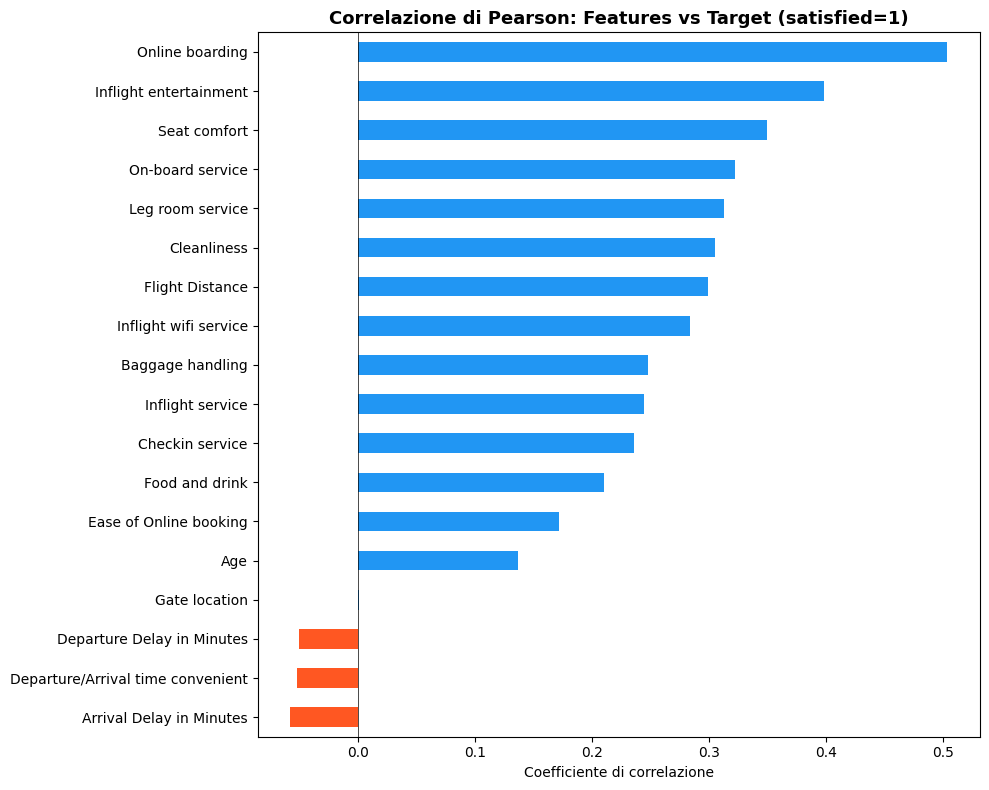


COMMENTO SULLA MULTICOLLINEARITA':
Departure Delay e Arrival Delay sono fortemente correlati (r ~ 0.97).
I due ritardi tendono a presentarsi insieme; la correlazione non quantifica un effetto causale.
Per i modelli lineari, potrebbe essere utile rimuoverne uno; per i modelli ad albero,
la predizione può restare buona, ma l'importanza può distribuirsi fra variabili correlate.


In [45]:
# Matrice di correlazione tra features numeriche
print("ANALISI CORRELAZIONE TRA FEATURES")
print("=" * 60)

# Seleziona solo le colonne numeriche (escluso id e target encoded)
numeric_cols = features_to_scale  # 18 features (4 continue + 14 rating)

corr_matrix = raw_data_train[numeric_cols].corr()

# Heatmap
plt.figure(figsize=(16, 13))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1, linewidths=0.5,
            square=True, cbar_kws={"shrink": 0.8})
plt.title("Matrice di Correlazione - Features Numeriche", fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Identifica coppie con alta correlazione (|r| > 0.7)
print("\nCOPPIE CON ALTA CORRELAZIONE (|r| > 0.7):")
print("-" * 50)

high_corr_pairs = []
for i in range(len(numeric_cols)):
    for j in range(i+1, len(numeric_cols)):
        r = corr_matrix.iloc[i, j]
        if abs(r) > 0.7:
            high_corr_pairs.append((numeric_cols[i], numeric_cols[j], r))
            print(f"  {numeric_cols[i]} <-> {numeric_cols[j]}: r = {r:.4f}")

if not high_corr_pairs:
    print("  Nessuna coppia con |r| > 0.7")

# Correlazione di ciascuna feature con il target (encoded)
print("\n\nCORRELAZIONE FEATURES vs TARGET:")
print("-" * 50)

target_binary = (raw_data_train["satisfaction"] == "satisfied").astype(int)
corr_with_target = raw_data_train[numeric_cols].corrwith(target_binary).sort_values(ascending=False)

for feat, r in corr_with_target.items():
    bar = "+" * int(abs(r) * 40)
    sign = "+" if r > 0 else "-"
    print(f"  {feat:40s} {sign}{abs(r):.3f}  {bar}")

# Visualizzazione
plt.figure(figsize=(10, 8))
corr_with_target.sort_values().plot(kind='barh', color=['#FF5722' if v < 0 else '#2196F3' for v in corr_with_target.sort_values()])
plt.title("Correlazione di Pearson: Features vs Target (satisfied=1)", fontsize=13, fontweight='bold')
plt.xlabel("Coefficiente di correlazione")
plt.axvline(x=0, color='black', linewidth=0.5)
plt.tight_layout()
plt.show()

print("\nCOMMENTO SULLA MULTICOLLINEARITA':")
print("Departure Delay e Arrival Delay sono fortemente correlati (r ~ 0.97).")
print("I due ritardi tendono a presentarsi insieme; la correlazione non quantifica un effetto causale.")
print("Per i modelli lineari, potrebbe essere utile rimuoverne uno; per i modelli ad albero,")
print("la predizione può restare buona, ma l'importanza può distribuirsi fra variabili correlate.")

La heatmap evidenzia che le 18 features numeriche sono in gran parte poco correlate tra loro, ad eccezione della coppia Departure Delay / Arrival Delay (r ≈ 0.97), il che è logico. La correlazione con il target mostra che le features legate ai servizi a bordo (Online boarding, Inflight entertainment, Seat comfort) hanno la correlazione positiva più forte con la soddisfazione, mentre i ritardi hanno correlazione negativa debole.

La correlazione di Pearson non esaurisce le dipendenze: alcune variabili di servizio si muovono insieme e possono avere relazioni non lineari. Non interpreto quindi coefficienti piccoli come assenza di informazione. Conservo entrambe le variabili di ritardo nella Strada 1 e segnalo il limite nell'interpretazione delle importanze.

## 2.11 Feature Selection

FEATURE SELECTION

1. T-TEST (Features Numeriche vs Target Binario)
--------------------------------------------------
                                   t_stat  p_value  rank
feature                                                 
Online boarding                   221.882    0.000     1
Inflight entertainment            143.648    0.000     2
Inflight wifi service             126.804    0.000     3
Seat comfort                      122.340    0.000     4
On-board service                  111.695    0.000     5
Leg room service                  108.917    0.000     6
Cleanliness                       105.303    0.000     7
Flight Distance                    96.424    0.000     8
Baggage handling                   83.178    0.000     9
Inflight service                   82.153    0.000    10
Checkin service                    79.391    0.000    11
Ease of Online booking             75.852    0.000    12
Food and drink                     70.307    0.000    13
Age                       

                          feature  MI_score  rank
                  Online boarding     0.211     1
            Inflight wifi service     0.162     2
                   Class_Business     0.133     3
           Type of Travel_encoded     0.114     4
                        Class_Eco     0.107     5
           Inflight entertainment     0.094     6
                     Seat comfort     0.079     7
                  Flight Distance     0.064     8
                 Leg room service     0.061     9
                 On-board service     0.057    10
                      Cleanliness     0.052    11
           Ease of Online booking     0.051    12
                              Age     0.046    13
                 Baggage handling     0.043    14
                 Inflight service     0.041    15
                  Checkin service     0.032    16
                   Food and drink     0.026    17
            Customer Type_encoded     0.019    18
                    Gate location     0.012    19


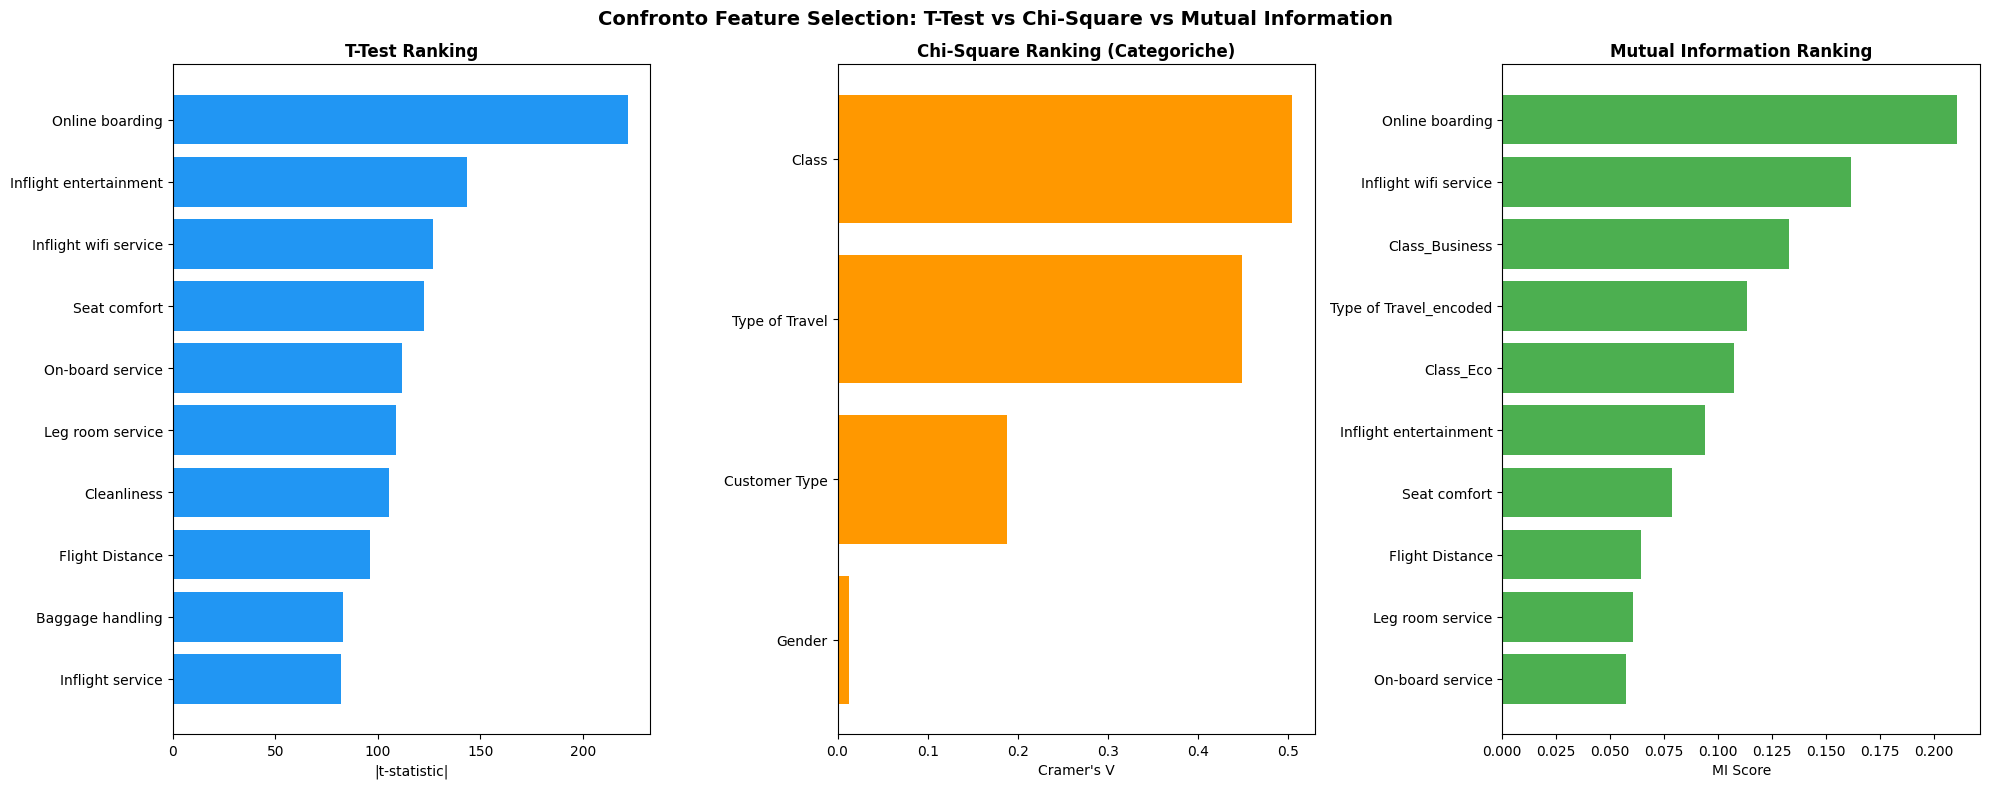

Strada 2, ranking descrittivo sull’intero train: ['Online boarding', 'Inflight entertainment', 'Inflight wifi service', 'Seat comfort']
Criterio: p < 0.05, ordine decrescente di |t|. In CV la selezione viene rifatta per fold.
Un p-value numericamente pari a zero indica underflow, non probabilità matematica nulla.
                        t_stat  p_value     n0     n1  rank
feature                                                    
Online boarding        221.882        0  57802  43674     1
Inflight entertainment 143.648        0  58865  45025     2
Inflight wifi service  126.804        0  58871  41930     3
Seat comfort            122.34        0  58878  45025     4


In [46]:
from scipy.stats import ttest_ind, chi2_contingency
from sklearn.feature_selection import mutual_info_classif
import warnings

print("FEATURE SELECTION")
print("=" * 60)

# Target binario
target_binary = (raw_data_train["satisfaction"] == "satisfied").astype(int)
group_0 = target_binary == 0
group_1 = target_binary == 1

# -------------------------------------------------------
# 1. T-TEST per features numeriche
# -------------------------------------------------------
print("\n1. T-TEST (Features Numeriche vs Target Binario)")
print("-" * 50)

from airline_pipeline import welch_ranking
ttest_df = welch_ranking(raw_data_train, target_binary)
ttest_df["rank"] = range(1, len(ttest_df) + 1)
print(ttest_df[["t_stat", "p_value", "rank"]].to_string())

# -------------------------------------------------------
# 2. CHI-SQUARE + CRAMER'S V per features categoriche
# -------------------------------------------------------
print("\n\n2. CHI-SQUARE + CRAMER'S V (Features Categoriche)")
print("-" * 50)

chi2_results = {}
for col in categorical_cols:
    ct = pd.crosstab(raw_data_train[col], raw_data_train["satisfaction"])
    chi2, p_val, dof, _ = chi2_contingency(ct)
    n = ct.sum().sum()
    min_dim = min(ct.shape) - 1
    cramers_v = np.sqrt(chi2 / (n * min_dim))
    chi2_results[col] = {"chi2": chi2, "p_value": p_val, "cramers_v": cramers_v}

chi2_df = pd.DataFrame(chi2_results).T.sort_values("cramers_v", ascending=False)
print(chi2_df.to_string())

# -------------------------------------------------------
# 3. MUTUAL INFORMATION
# -------------------------------------------------------
print("\n\n3. MUTUAL INFORMATION (Tutte le Features)")
print("-" * 50)

# Prepara dataset completo per MI: numeriche + encoded
mi_features = features_to_scale.copy()

# Aggiungi encoded categoriche
for col in binary_cols:
    col_enc = f"{col}_encoded"
    if col_enc in raw_data_encoded.columns:
        mi_features.append(col_enc)

# Aggiungi one-hot di Class
class_dummies = [c for c in raw_data_encoded.columns if c.startswith("Class_")]
mi_features.extend(class_dummies)

X_mi = raw_data_encoded[mi_features].copy()
X_mi = X_mi.fillna(X_mi.median())

discrete_mask = [c in rating_features_all or c.endswith('_encoded') or c.startswith('Class_') for c in mi_features]
mi_scores = mutual_info_classif(X_mi, target_binary, discrete_features=discrete_mask, random_state=SEED, n_neighbors=5)
mi_df = pd.DataFrame({"feature": mi_features, "MI_score": mi_scores}).sort_values("MI_score", ascending=False)
mi_df["rank"] = range(1, len(mi_df) + 1)
print(mi_df.to_string(index=False))

# -------------------------------------------------------
# 4. CONFRONTO RANKING E VISUALIZZAZIONE
# -------------------------------------------------------
print("\n\n4. CONFRONTO RANKING")
print("-" * 50)

# Ranking dal T-test (top 10)
print("\nTop 10 features per T-test (|t-statistic|):")
for i, (feat, row) in enumerate(ttest_df.head(10).iterrows(), 1):
    print(f"  {i}. {feat} (|t| = {row['t_stat']:.2f})")

print("\nTop 10 features per Mutual Information:")
for i, row in mi_df.head(10).iterrows():
    print(f"  {int(row['rank'])}. {row['feature']} (MI = {row['MI_score']:.4f})")

# Visualizzazione comparativa
fig, axes = plt.subplots(1, 3, figsize=(20, 8))

# T-test
ttest_top = ttest_df.head(10)
axes[0].barh(range(len(ttest_top)), ttest_top["t_stat"].values, color='#2196F3')
axes[0].set_yticks(range(len(ttest_top)))
axes[0].set_yticklabels(ttest_top.index)
axes[0].set_xlabel("|t-statistic|")
axes[0].set_title("T-Test Ranking", fontweight='bold')
axes[0].invert_yaxis()

# Chi-square (Cramer's V)
axes[1].barh(range(len(chi2_df)), chi2_df["cramers_v"].values, color='#FF9800')
axes[1].set_yticks(range(len(chi2_df)))
axes[1].set_yticklabels(chi2_df.index)
axes[1].set_xlabel("Cramer's V")
axes[1].set_title("Chi-Square Ranking (Categoriche)", fontweight='bold')
axes[1].invert_yaxis()

# MI
mi_top = mi_df.head(10)
axes[2].barh(range(len(mi_top)), mi_top["MI_score"].values, color='#4CAF50')
axes[2].set_yticks(range(len(mi_top)))
axes[2].set_yticklabels(mi_top["feature"].values)
axes[2].set_xlabel("MI Score")
axes[2].set_title("Mutual Information Ranking", fontweight='bold')
axes[2].invert_yaxis()

plt.suptitle("Confronto Feature Selection: T-Test vs Chi-Square vs Mutual Information",
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# -------------------------------------------------------
# -------------------------------------------------------
# 5. Quattro numeriche significative: vincolo della Strada 2
ALPHA = 0.05
top4_features = ttest_df.loc[ttest_df['p_value'] < ALPHA].head(4).index.tolist()
assert len(top4_features) == 4
print('Strada 2, ranking descrittivo sull’intero train:', top4_features)
print('Criterio: p < 0.05, ordine decrescente di |t|. In CV la selezione viene rifatta per fold.')
print('Un p-value numericamente pari a zero indica underflow, non probabilità matematica nulla.')
print(ttest_df.loc[top4_features].to_string(float_format=lambda value: f'{value:.6g}'))

I tre metodi rispondono a domande diverse:

- **Welch T-test** confronta le medie delle numeriche fra le due classi, senza assumere varianze uguali. Escludo mancanti e zeri dei rating secondo la policy dichiarata; non li riempio prima del test statistico. Uso `p < 0,05` e ordino le candidate per `|t|`, anche quando i p-value vanno in underflow. Con tanti record, significatività non significa automaticamente grande utilità predittiva. I rating sono ordinali: confrontarne le medie è un'approssimazione coerente con la traccia, non una prova causale.
- **Chi-square e Cramér's V** mostrano l'associazione delle categoriche con il target. Class e Type of Travel emergono nel loro gruppo; non confronto numericamente Cramér's V con t-statistiche per dichiarare una variabile superiore a tutte le altre.
- **Mutual Information** cattura anche dipendenze non lineari. Dichiaro rating e colonne codificate come discreti; Age, distanza e ritardi restano continui nell'estimatore. Qui conservo lo zero come categoria per confrontare anche l'informazione della codifica originale.

La **Strada 2** usa le quattro numeriche significative indicate dal T-test. Il ranking completo sopra è descrittivo: la selezione utilizzata da ciascun modello viene rifatta nella Pipeline, dentro ogni fold. Mantengo inoltre la mia **selezione ibrida** come esperimento distinto: due numeriche dal T-test e due categoriche dal Chi-square/Cramér's V. Quando seleziono Class, mantengo il contrasto Business contro le altre classi, come nel progetto originale: questo perde la distinzione Eco/Eco Plus ed è un limite esplicito.

## 2.12 Pipeline unificata, dai dati grezzi alla previsione

Riparto dai dati originali, senza riutilizzare gli scaler o gli encoder dimostrativi dell'EDA. La Pipeline contiene selezione, imputazione, encoding, scaling e classificatore. Durante la CV, `fit` vede soltanto il training del fold. Le categorie sconosciute sono gestite da OneHotEncoder con `handle_unknown='ignore'`: producono zeri nel relativo blocco, senza inventare una categoria appresa. Con categorie binarie questo coincide con la categoria di riferimento, quindi in un servizio reale monitorerei questi casi.

In [47]:
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from airline_pipeline import SurveySelector, SurveyPreprocessor, NUMERIC, CATEGORICAL, PRE_FLIGHT, DELAYS

FEATURE_COLUMNS = [c for c in raw_data_train if c not in ['id', 'satisfaction', 'Unnamed: 0']]
X_train = raw_data_train[FEATURE_COLUMNS].copy()
y_train = raw_data_train['satisfaction'].map({'neutral or dissatisfied': 0, 'satisfied': 1})
assert y_train.notna().all()
assert len(FEATURE_COLUMNS) == 22
assert set(FEATURE_COLUMNS) == set(NUMERIC + CATEGORICAL)
print('Input grezzo:', X_train.shape, '| target:', y_train.value_counts().to_dict())

def make_pipeline(route, classifier):
    if route == 'S1':
        selector, indicators = 'passthrough', True
    elif route == 'S2':
        selector, indicators = SurveySelector(method='ttest', k=4, alpha=0.05), False
    elif route == 'Ibrida':
        selector, indicators = SurveySelector(method='hybrid', alpha=0.05), False
    elif route == 'Senza rating':
        selector, indicators = SurveySelector(method='fixed', columns=PRE_FLIGHT + DELAYS), False
    elif route == 'Pre-volo':
        selector, indicators = SurveySelector(method='fixed', columns=PRE_FLIGHT), False
    else:
        raise ValueError(route)
    return Pipeline([('select', selector), ('prepare', SurveyPreprocessor(add_zero_flags=indicators)),
                     ('model', clone(classifier))])

# Solo anteprima: questa istanza non viene passata a CV o GridSearch.
preview = SurveyPreprocessor().fit_transform(X_train)
assert np.isfinite(preview.to_numpy()).all()
print('Esempio trasformato S1:', preview.shape)
display(preview.head())
del preview

Input grezzo: (103904, 22) | target: {0: 58879, 1: 45025}


Esempio trasformato S1: (103904, 37)


,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Inflight wifi service_zeroflag,Departure/Arrival time convenient_zeroflag,Ease of Online booking_zeroflag,Gate location_zeroflag,Food and drink_zeroflag,Online boarding_zeroflag,Seat comfort_zeroflag,Inflight entertainment_zeroflag,On-board service_zeroflag,Leg room service_zeroflag,Checkin service_zeroflag,Inflight service_zeroflag,Cleanliness_zeroflag,Gender_Male,Customer Type_disloyal Customer,Type of Travel_Personal Travel,Class_Business,Class_Eco,Class_Eco Plus
0,-1.745,-0.732,0.146,0.582,0.089,-1.547,1.354,-0.274,1.183,1.232,0.479,-0.285,0.312,0.550,1.156,1.306,2.083,1.385,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,1.000,0.000,0.000,1.000
1,-0.951,-0.957,0.146,-0.898,0.089,0.018,-1.664,-0.274,-1.849,-1.770,-1.849,1.258,-0.535,-1.821,0.306,-1.743,0.083,0.462,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,1.000,0.000,1.000,0.000,0.000
2,-0.885,-0.048,-0.661,-0.898,-0.698,-0.765,1.354,1.318,1.183,1.232,0.479,-0.285,0.312,0.550,0.306,1.306,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000
3,-0.951,-0.629,-0.661,1.323,1.663,1.584,-0.909,-1.070,-1.091,-1.020,-1.073,1.258,-0.535,-1.821,0.306,-0.981,0.917,0.692,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000
4,1.430,-0.978,0.146,-0.158,0.089,0.018,0.600,1.318,1.183,-0.269,-0.297,0.486,0.312,-0.241,-0.545,-0.219,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000


# 3.0 Scelta della Metrica di Valutazione

Per valutare i modelli di classificazione utilizzo le seguenti metriche:

- **Accuracy**: percentuale di predizioni corrette sul totale. È la metrica principale perché il dataset è sufficientemente bilanciato (~43/57).
- **Precision**: tra le predizioni positive, quante sono effettivamente positive. Importante per minimizzare i falsi positivi.
- **Recall (Sensitivity)**: tra i campioni effettivamente positivi, quanti sono stati correttamente identificati. Importante per minimizzare i falsi negativi.
- **F1-Score**: media armonica di Precision e Recall. Utile quando si cerca un equilibrio tra le due.
- **AUC-ROC**: area sotto la curva ROC (Receiver Operating Characteristic). Misura la capacità discriminativa del modello indipendentemente dalla soglia di classificazione.

**Perché l'Accuracy come metrica principale?**
Con uno sbilanciamento moderato (rapporto ~1.3:1), l'accuracy non è distorta come lo sarebbe in dataset fortemente sbilanciati (es. 95/5). Riporto comunque sempre anche Precision, Recall, F1 e AUC-ROC per una valutazione completa.

La classe positiva è **satisfied = 1**. Un falso positivo indica una persona prevista soddisfatta che nel target è neutrale o insoddisfatta; potrebbe nascondere una necessità di assistenza. Mantengo la soglia predefinita del classificatore e mostro il report di entrambe le classi, senza ottimizzare soglie sul test. L'accuracy è anche la metrica di confronto richiesta dalla traccia. Aggiungo la baseline che predice sempre la classe maggioritaria appresa sul train.

Uso gli stessi cinque fold stratificati per confrontare gli algoritmi. Il miglior punteggio di GridSearch è una misura di selezione interna, potenzialmente ottimista dopo molti tentativi; non lo presento come una nested CV o come una garanzia per dati futuri.

In [48]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             confusion_matrix, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier

print("Librerie per modellazione e metriche importate con successo.")
print(f"\nModelli che verranno confrontati:")
print("  1. Logistic Regression")
print("  2. Random Forest")
print("  3. AdaBoost")
print("  4. Gradient Boosting")
print(f"\nMetriche: Accuracy (principale), Precision, Recall, F1-Score, AUC-ROC")

Librerie per modellazione e metriche importate con successo.

Modelli che verranno confrontati:
  1. Logistic Regression
  2. Random Forest
  3. AdaBoost
  4. Gradient Boosting

Metriche: Accuracy (principale), Precision, Recall, F1-Score, AUC-ROC


# 4.0 Modelli, Training e Ottimizzazione

## 4.1 Strada 1: tutte le feature

Uso le 22 variabili originali, escludendo indice, ID e target. Sul train completo ottengo 37 colonne: 18 numeriche, 13 flag degli zeri e 6 colonne di encoding. Nei fold il numero di flag può cambiare se un caso rarissimo non è presente nel relativo training: è una conseguenza corretta dell'apprendimento locale. Conservo Logistic Regression, Random Forest, AdaBoost e Gradient Boosting e le griglie originali.

S1 | spot check | Logistic Regression


  Fold: [0.90501 0.90159 0.90376 0.90333 0.90255] | media 0.90325 ± 0.00115


S1 | spot check | Random Forest


  Fold: [0.96078 0.96198 0.96165 0.9616  0.96059] | media 0.96132 ± 0.00054


S1 | spot check | AdaBoost


  Fold: [0.92546 0.92219 0.92517 0.92253 0.92194] | media 0.92346 ± 0.00153


S1 | spot check | Gradient Boosting


  Fold: [0.94149 0.9397  0.94307 0.94105 0.93908] | media 0.94088 ± 0.00140


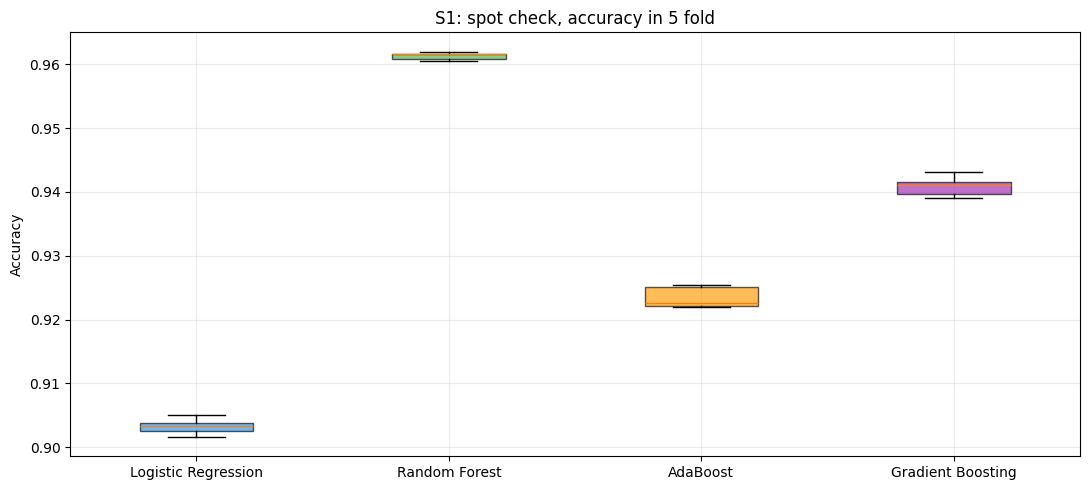

Ranking: ['Random Forest', 'Gradient Boosting', 'AdaBoost', 'Logistic Regression']


In [49]:
from sklearn.model_selection import cross_validate, ParameterGrid
from joblib import parallel_backend
import joblib
import time

models_dict = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1),
    'AdaBoost': AdaBoostClassifier(n_estimators=100, random_state=SEED),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=SEED),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
spot_results, tuned, cv_audit = {}, {}, []

def spot_check(route):
    scores_by_model = {}
    for name, model in models_dict.items():
        print(f'{route} | spot check | {name}', flush=True)
        with parallel_backend('loky', inner_max_num_threads=1):
            result = cross_validate(make_pipeline(route, model), X_train, y_train, cv=cv,
                                    scoring='accuracy', n_jobs=N_JOBS, return_estimator=True,
                                    error_score='raise')
        scores = result['test_score']
        scores_by_model[name] = scores
        print(f'  Fold: {np.round(scores, 5)} | media {scores.mean():.5f} ± {scores.std():.5f}', flush=True)
        for fold, ((train_idx, validation_idx), estimator) in enumerate(zip(cv.split(X_train, y_train), result['estimator']), 1):
            prep = estimator.named_steps['prepare']
            assert prep.n_fit_rows_ == len(train_idx) < len(X_train)
            row = {'route': route, 'model': name, 'fold': fold,
                   'training_rows': len(train_idx), 'validation_rows': len(validation_idx),
                   'preprocessing_fit_rows': prep.n_fit_rows_,
                   'features': prep.get_feature_names_out().tolist()}
            selector = estimator.named_steps['select']
            if selector != 'passthrough':
                assert selector.n_fit_rows_ == len(train_idx)
                row['selected_raw'] = selector.selected_features_
            cv_audit.append(row)
        del result
        (RESULTS_DIR / 'audit_fold.json').write_text(json.dumps(cv_audit, indent=2))
    spot_results[route] = scores_by_model
    ranking = sorted(scores_by_model, key=lambda name: (-scores_by_model[name].mean(), name))
    fig, ax = plt.subplots(figsize=(11, 5))
    box = ax.boxplot([scores_by_model[name] for name in models_dict], tick_labels=list(models_dict), patch_artist=True)
    for patch, color in zip(box['boxes'], ['#2196F3', '#4CAF50', '#FF9800', '#9C27B0']):
        patch.set_facecolor(color); patch.set_alpha(0.65)
    ax.set_title(f'{route}: spot check, accuracy in 5 fold')
    ax.set_ylabel('Accuracy'); ax.grid(alpha=0.25)
    plt.tight_layout(); plt.show()
    print('Ranking:', ranking)
    pd.DataFrame(scores_by_model).to_csv(RESULTS_DIR / f'spot_{route}.csv', index_label='fold_0based')
    return ranking

ranking_s1 = spot_check('S1')
top2_names_s1 = ranking_s1[:2]

In [50]:
param_grids = {
    "Logistic Regression": {
        "C": [0.01, 0.1, 1, 10],
        "solver": ["lbfgs", "liblinear"]
    },
    "Random Forest": {
        "n_estimators": [100, 200, 300],
        "max_depth": [10, 20, None],
        "min_samples_split": [2, 5]
    },
    "AdaBoost": {
        "n_estimators": [50, 100, 200],
        "learning_rate": [0.01, 0.1, 0.5, 1.0]
    },
    "Gradient Boosting": {
        "n_estimators": [100, 200, 300],
        "max_depth": [3, 5, 7],
        "learning_rate": [0.01, 0.1, 0.2]
    }
}


def tune(route, names):
    tuned[route] = {}
    for name in names:
        grid = {'model__' + key: values for key, values in param_grids[name].items()}
        print(f'{route} | GridSearch | {name}: {len(ParameterGrid(grid))} combinazioni × 5 fold', flush=True)
        start = time.perf_counter()
        search = GridSearchCV(make_pipeline(route, models_dict[name]), grid, cv=cv, scoring='accuracy',
                              n_jobs=N_JOBS, refit=True, error_score='raise', verbose=1,
                              return_train_score=False)
        with parallel_backend('loky', inner_max_num_threads=1):
            search.fit(X_train, y_train)
        tuned[route][name] = {'pipeline': search.best_estimator_, 'cv_accuracy': float(search.best_score_),
                              'params': search.best_params_, 'seconds': time.perf_counter() - start}
        print(f'  CV {search.best_score_:.6f} | {search.best_params_}', flush=True)
        pd.DataFrame(search.cv_results_).to_csv(RESULTS_DIR / f'grid_{route}_{name}.csv', index=False)
        joblib.dump(tuned, RESULTS_DIR / 'checkpoint_modelli.joblib', compress=3)
    return {name: item['pipeline'] for name, item in tuned[route].items()}

best_models_s1 = tune('S1', top2_names_s1)

S1 | GridSearch | Random Forest: 18 combinazioni × 5 fold


Fitting 5 folds for each of 18 candidates, totalling 90 fits


  CV 0.961744 | {'model__max_depth': None, 'model__min_samples_split': 2, 'model__n_estimators': 300}


S1 | GridSearch | Gradient Boosting: 27 combinazioni × 5 fold


Fitting 5 folds for each of 27 candidates, totalling 135 fits


  CV 0.963707 | {'model__learning_rate': 0.1, 'model__max_depth': 7, 'model__n_estimators': 300}


In [51]:
print('Strada 1: selezione completata usando soltanto la CV sul train.')
display(pd.DataFrame({name: {'Accuracy CV': item['cv_accuracy'], 'Parametri': item['params']}
                      for name, item in tuned['S1'].items()}).T)
print('Il test di entrambe le strade è raccolto nella sezione 5, dopo aver fissato tutti i modelli.')

Strada 1: selezione completata usando soltanto la CV sul train.


,Accuracy CV,Parametri
Random Forest,0.962,"{'model__max_depth': None, 'model__min_samples..."
Gradient Boosting,0.964,"{'model__learning_rate': 0.1, 'model__max_dept..."


Il test di entrambe le strade è raccolto nella sezione 5, dopo aver fissato tutti i modelli.


## 4.2 Strada 2: quattro feature significative al T-test

La Pipeline seleziona quattro variabili numeriche con `p < 0,05`, ordinate per `|t|`, usando esclusivamente le righe e le etichette del training del fold. Imputazione e scaling avvengono dopo la selezione. Non aggiungo categoriche né flag: al classificatore arrivano **esattamente quattro colonne**. Confronto gli stessi quattro algoritmi e ottimizzo i migliori due con le stesse griglie della Strada 1.

S2 | spot check | Logistic Regression


  Fold: [0.79385 0.79553 0.79654 0.79751 0.78999] | media 0.79469 ± 0.00264


S2 | spot check | Random Forest


  Fold: [0.85689 0.85439 0.85453 0.85694 0.84846] | media 0.85424 ± 0.00309


S2 | spot check | AdaBoost


  Fold: [0.84082 0.83966 0.83855 0.84289 0.83513] | media 0.83941 ± 0.00258


S2 | spot check | Gradient Boosting


  Fold: [0.85025 0.84827 0.84803 0.85015 0.84312] | media 0.84797 ± 0.00259


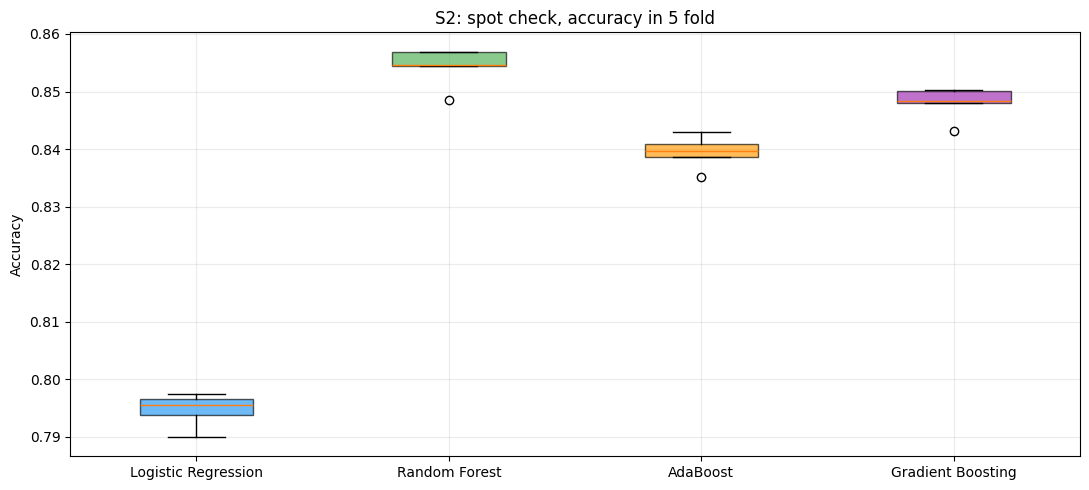

Ranking: ['Random Forest', 'Gradient Boosting', 'AdaBoost', 'Logistic Regression']


In [52]:
ranking_s2 = spot_check('S2')
top2_names_s2 = ranking_s2[:2]

In [53]:
best_models_s2 = tune('S2', top2_names_s2)
for name, model in best_models_s2.items():
    columns = model.named_steps['prepare'].get_feature_names_out().tolist()
    assert len(columns) == 4
    print(name, '| quattro feature finali:', columns)
    print(model.named_steps['select'].ranking_.loc[columns].to_string(float_format=lambda value: f'{value:.6g}'))

S2 | GridSearch | Random Forest: 18 combinazioni × 5 fold


Fitting 5 folds for each of 18 candidates, totalling 90 fits


  CV 0.854539 | {'model__max_depth': 10, 'model__min_samples_split': 5, 'model__n_estimators': 200}


S2 | GridSearch | Gradient Boosting: 27 combinazioni × 5 fold


Fitting 5 folds for each of 27 candidates, totalling 135 fits


  CV 0.854577 | {'model__learning_rate': 0.2, 'model__max_depth': 5, 'model__n_estimators': 200}


Random Forest | quattro feature finali: ['Online boarding', 'Inflight entertainment', 'Inflight wifi service', 'Seat comfort']
                        t_stat  p_value     n0     n1
feature                                              
Online boarding        221.882        0  57802  43674
Inflight entertainment 143.648        0  58865  45025
Inflight wifi service  126.804        0  58871  41930
Seat comfort            122.34        0  58878  45025
Gradient Boosting | quattro feature finali: ['Online boarding', 'Inflight entertainment', 'Inflight wifi service', 'Seat comfort']
                        t_stat  p_value     n0     n1
feature                                              
Online boarding        221.882        0  57802  43674
Inflight entertainment 143.648        0  58865  45025
Inflight wifi service  126.804        0  58871  41930
Seat comfort            122.34        0  58878  45025


In [54]:
display(pd.DataFrame({name: {'Accuracy CV': item['cv_accuracy'], 'Parametri': item['params']}
                      for name, item in tuned['S2'].items()}).T)
print('Selezione nel train completo conclusa; il test non è usato per scegliere parametri o colonne.')

,Accuracy CV,Parametri
Random Forest,0.855,"{'model__max_depth': 10, 'model__min_samples_s..."
Gradient Boosting,0.855,"{'model__learning_rate': 0.2, 'model__max_dept..."


Selezione nel train completo conclusa; il test non è usato per scegliere parametri o colonne.


## 4.3 Approfondimenti conservati: selezione ibrida e scenari temporali

L'ibrida conserva la mia idea originale: due numeriche dal T-test e due categoriche dal Chi-square. Ripeto spot check dei quattro algoritmi e tuning dei migliori due. Per **Senza rating** e **Pre-volo** confronto gli stessi quattro algoritmi e ottimizzo il primo classificato, come nel controllo aggiuntivo originale. Non sostituiscono le due strade della traccia.

Le scelte sono fissate sul train prima della nuova valutazione sul test. Le griglie e i cinque fold restano gli stessi: non riduco la ricerca per questi approfondimenti.

Ibrida | spot check | Logistic Regression


  Fold: [0.86031 0.84284 0.84303 0.84563 0.83821] | media 0.84600 ± 0.00754


Ibrida | spot check | Random Forest


  Fold: [0.86897 0.86906 0.86488 0.86863 0.864  ] | media 0.86711 ± 0.00220


Ibrida | spot check | AdaBoost


  Fold: [0.85775 0.85506 0.85419 0.85732 0.85168] | media 0.85520 ± 0.00221


Ibrida | spot check | Gradient Boosting


  Fold: [0.86911 0.86757 0.86396 0.8681  0.86323] | media 0.86640 ± 0.00235


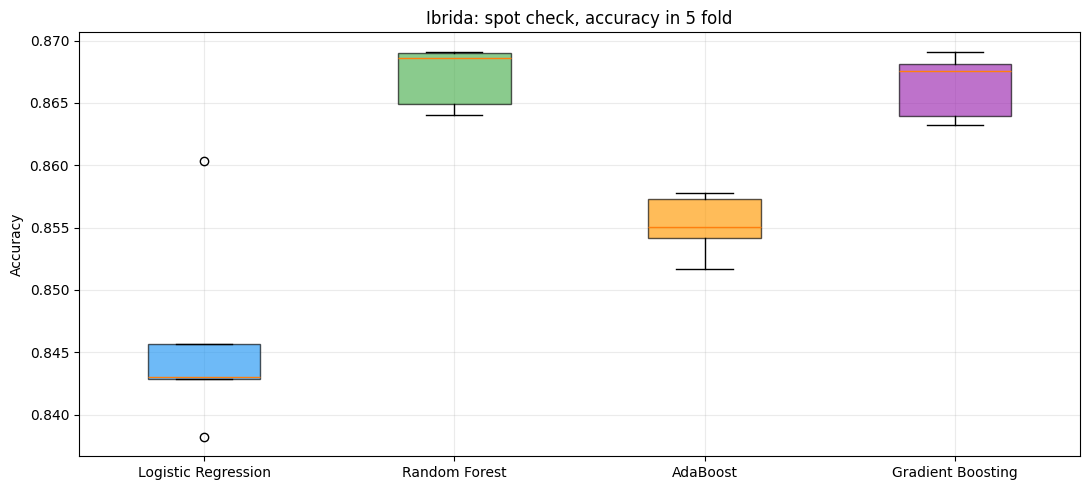

Ranking: ['Random Forest', 'Gradient Boosting', 'AdaBoost', 'Logistic Regression']
Ibrida | GridSearch | Random Forest: 18 combinazioni × 5 fold


Fitting 5 folds for each of 18 candidates, totalling 90 fits


  CV 0.867108 | {'model__max_depth': 10, 'model__min_samples_split': 2, 'model__n_estimators': 100}


Ibrida | GridSearch | Gradient Boosting: 27 combinazioni × 5 fold


Fitting 5 folds for each of 27 candidates, totalling 135 fits


...

  Fold: [0.77061 0.77022 0.76969 0.76695 0.77002] | media 0.76950 ± 0.00131


Senza rating | spot check | AdaBoost


  Fold: [0.79294 0.79101 0.7939  0.78894 0.78908] | media 0.79117 ± 0.00200


Senza rating | spot check | Gradient Boosting


  Fold: [0.80492 0.80261 0.80631 0.80294 0.80144] | media 0.80365 ± 0.00174


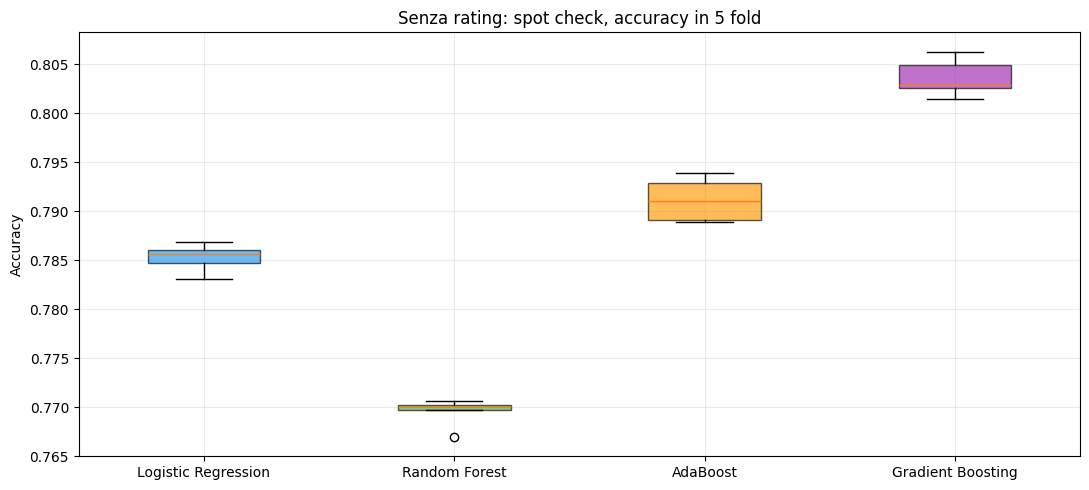

Ranking: ['Gradient Boosting', 'AdaBoost', 'Logistic Regression', 'Random Forest']
Senza rating | GridSearch | Gradient Boosting: 27 combinazioni × 5 fold


Fitting 5 folds for each of 27 candidates, totalling 135 fits


  CV 0.806042 | {'model__learning_rate': 0.01, 'model__max_depth': 7, 'model__n_estimators': 300}


Pre-volo | spot check | Logistic Regression


  Fold: [0.78278 0.78418 0.78187 0.78322 0.78152] | media 0.78271 ± 0.00095


...

  Fold: [0.73971 0.73846 0.73562 0.73505 0.7398 ] | media 0.73773 ± 0.00202


Pre-volo | spot check | AdaBoost


  Fold: [0.7849  0.77985 0.78187 0.77956 0.77998] | media 0.78123 ± 0.00201


Pre-volo | spot check | Gradient Boosting


  Fold: [0.79943 0.79924 0.80174 0.79731 0.79658] | media 0.79886 ± 0.00181


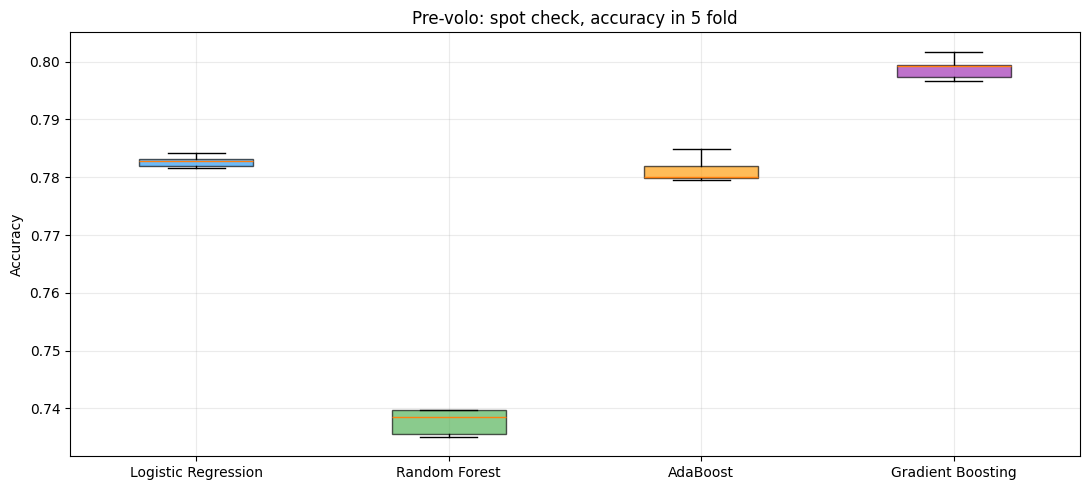

Ranking: ['Gradient Boosting', 'Logistic Regression', 'AdaBoost', 'Random Forest']
Pre-volo | GridSearch | Gradient Boosting: 27 combinazioni × 5 fold


Fitting 5 folds for each of 27 candidates, totalling 135 fits


  CV 0.801538 | {'model__learning_rate': 0.01, 'model__max_depth': 7, 'model__n_estimators': 300}


Tutti i modelli sono fissati: passo al test finale.


In [55]:
ranking_hybrid = spot_check('Ibrida')
best_models_hybrid = tune('Ibrida', ranking_hybrid[:2])
for name, pipeline in best_models_hybrid.items():
    assert len(pipeline.named_steps['prepare'].get_feature_names_out()) == 4
    print('Ibrida:', name, pipeline.named_steps['prepare'].get_feature_names_out().tolist())

ranking_without_ratings = spot_check('Senza rating')
best_models_without_ratings = tune('Senza rating', ranking_without_ratings[:1])
ranking_preflight = spot_check('Pre-volo')
best_models_preflight = tune('Pre-volo', ranking_preflight[:1])
for pipeline in best_models_preflight.values():
    assert set(pipeline.named_steps['select'].selected_features_) == set(PRE_FLIGHT)
    assert set(PRE_FLIGHT).isdisjoint(DELAYS)
print('Tutti i modelli sono fissati: passo al test finale.')

# 5.0 Valutazione finale e confronto

Tutti gli esperimenti ora hanno modelli e parametri fissati. Scelgo il modello principale fra S1 e S2 dalla migliore accuracy media in GridSearch; a parità esatta uso l'ordine del nome come criterio deterministico. Gli approfondimenti restano separati. Calcolo sul test il confronto richiesto, includendo baseline, report per classe, matrici di confusione e curve ROC. Il vincitore descrittivo sul test può essere diverso dalla scelta basata sulla CV: non riottimizzo in base a quel risultato.

Modello principale scelto da CV: S1 - Gradient Boosting
Baseline maggioritaria: 56.1018%


S1 - Random Forest {'Accuracy': 0.96262, 'Precision': 0.97238, 'Recall': 0.94159, 'F1-Score': 0.95674, 'AUC-ROC': 0.99405}
                         precision    recall  f1-score   support

neutral or dissatisfied       0.96      0.98      0.97     14573
              satisfied       0.97      0.94      0.96     11403

               accuracy                           0.96     25976
              macro avg       0.96      0.96      0.96     25976
           weighted avg       0.96      0.96      0.96     25976



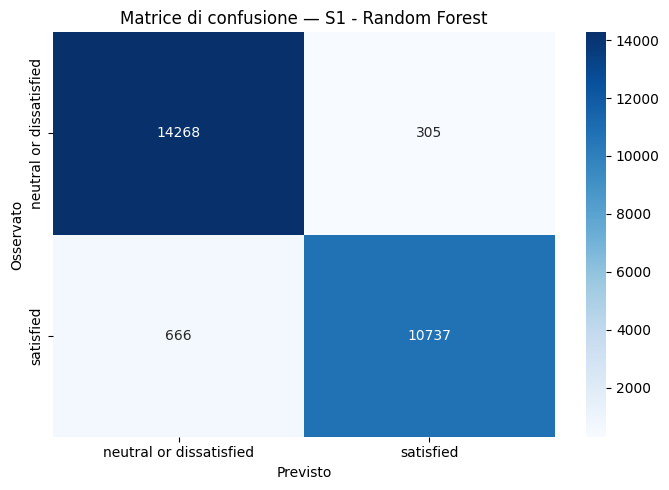

S1 - Gradient Boosting {'Accuracy': 0.96427, 'Precision': 0.97206, 'Recall': 0.9458, 'F1-Score': 0.95875, 'AUC-ROC': 0.99537}
                         precision    recall  f1-score   support

neutral or dissatisfied       0.96      0.98      0.97     14573
              satisfied       0.97      0.95      0.96     11403

               accuracy                           0.96     25976
              macro avg       0.97      0.96      0.96     25976
           weighted avg       0.96      0.96      0.96     25976



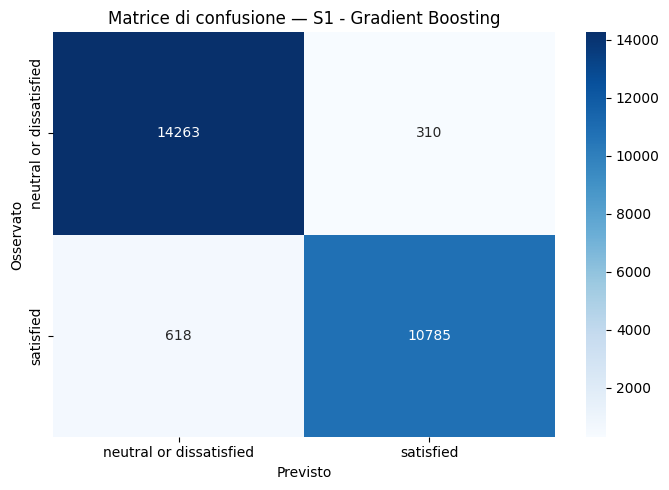

S2 - Random Forest {'Accuracy': 0.85367, 'Precision': 0.82604, 'Recall': 0.84451, 'F1-Score': 0.83518, 'AUC-ROC': 0.93209}
                         precision    recall  f1-score   support

neutral or dissatisfied       0.88      0.86      0.87     14573
              satisfied       0.83      0.84      0.84     11403

               accuracy                           0.85     25976
              macro avg       0.85      0.85      0.85     25976
           weighted avg       0.85      0.85      0.85     25976



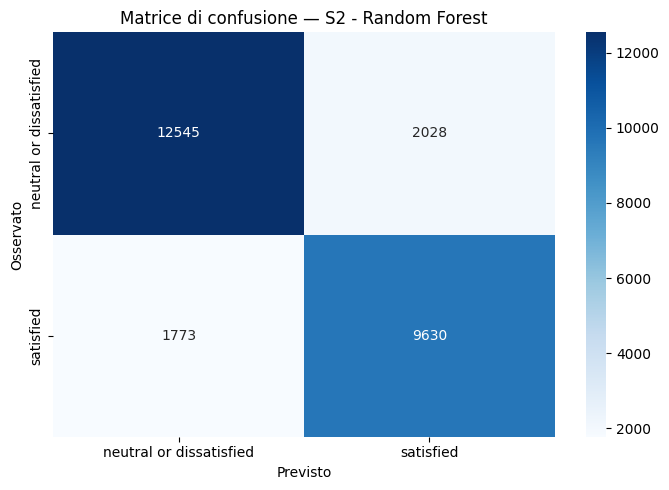

S2 - Gradient Boosting {'Accuracy': 0.85333, 'Precision': 0.82407, 'Recall': 0.84662, 'F1-Score': 0.83519, 'AUC-ROC': 0.93228}
                         precision    recall  f1-score   support

neutral or dissatisfied       0.88      0.86      0.87     14573
              satisfied       0.82      0.85      0.84     11403

               accuracy                           0.85     25976
              macro avg       0.85      0.85      0.85     25976
           weighted avg       0.85      0.85      0.85     25976



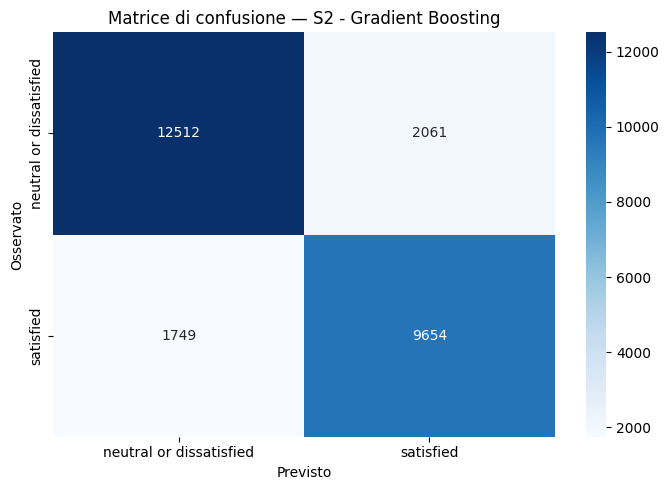

Ibrida - Random Forest {'Accuracy': 0.86584, 'Precision': 0.87505, 'Recall': 0.81005, 'F1-Score': 0.8413, 'AUC-ROC': 0.93624}
                         precision    recall  f1-score   support

neutral or dissatisfied       0.86      0.91      0.88     14573
              satisfied       0.88      0.81      0.84     11403

               accuracy                           0.87     25976
              macro avg       0.87      0.86      0.86     25976
           weighted avg       0.87      0.87      0.87     25976



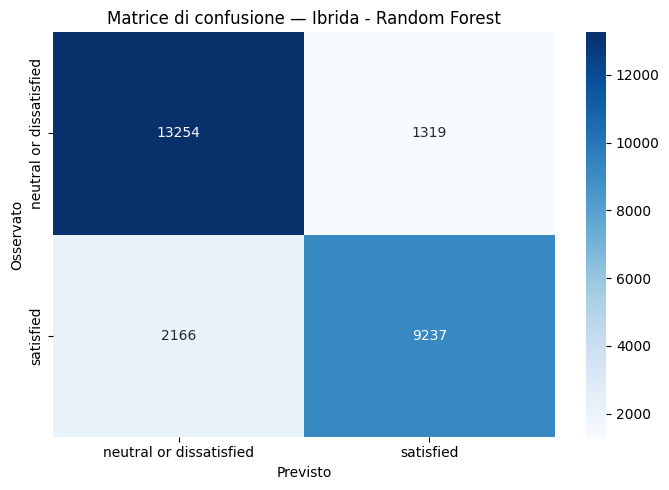

Ibrida - Gradient Boosting {'Accuracy': 0.86584, 'Precision': 0.87505, 'Recall': 0.81005, 'F1-Score': 0.8413, 'AUC-ROC': 0.9361}
                         precision    recall  f1-score   support

neutral or dissatisfied       0.86      0.91      0.88     14573
              satisfied       0.88      0.81      0.84     11403

               accuracy                           0.87     25976
              macro avg       0.87      0.86      0.86     25976
           weighted avg       0.87      0.87      0.87     25976



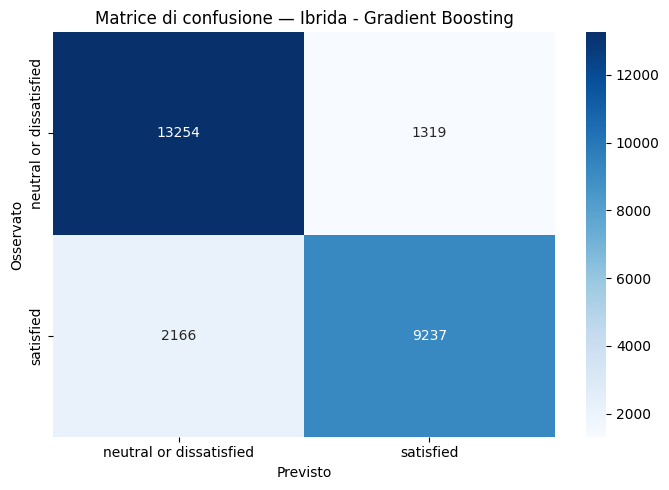

Senza rating - Gradient Boosting {'Accuracy': 0.80251, 'Precision': 0.77083, 'Recall': 0.78286, 'F1-Score': 0.7768, 'AUC-ROC': 0.8688}
                         precision    recall  f1-score   support

neutral or dissatisfied       0.83      0.82      0.82     14573
              satisfied       0.77      0.78      0.78     11403

               accuracy                           0.80     25976
              macro avg       0.80      0.80      0.80     25976
           weighted avg       0.80      0.80      0.80     25976



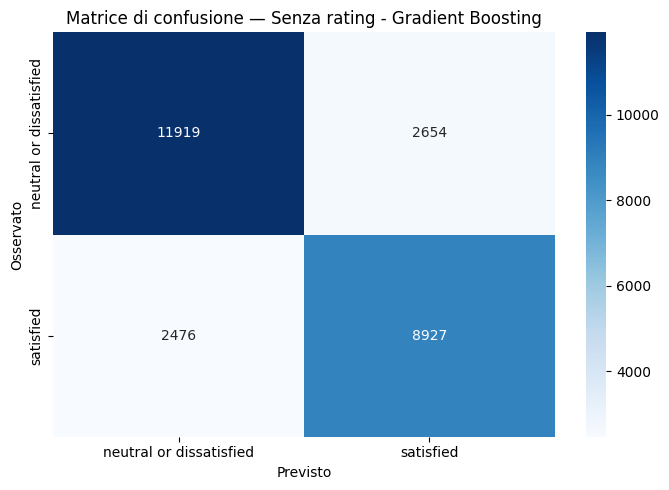

Pre-volo - Gradient Boosting {'Accuracy': 0.79477, 'Precision': 0.77425, 'Recall': 0.75164, 'F1-Score': 0.76278, 'AUC-ROC': 0.85865}
                         precision    recall  f1-score   support

neutral or dissatisfied       0.81      0.83      0.82     14573
              satisfied       0.77      0.75      0.76     11403

               accuracy                           0.79     25976
              macro avg       0.79      0.79      0.79     25976
           weighted avg       0.79      0.79      0.79     25976



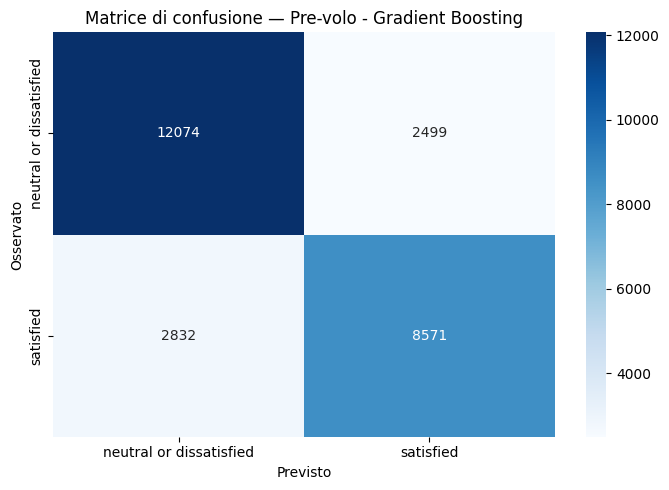

,Accuracy,Precision,Recall,F1-Score,AUC-ROC,Accuracy CV (selezione)
S1 - Gradient Boosting,0.96427,0.97206,0.94580,0.95875,0.99537,0.96371
S1 - Random Forest,0.96262,0.97238,0.94159,0.95674,0.99405,0.96174
S2 - Random Forest,0.85367,0.82604,0.84451,0.83518,0.93209,0.85454
S2 - Gradient Boosting,0.85333,0.82407,0.84662,0.83519,0.93228,0.85458


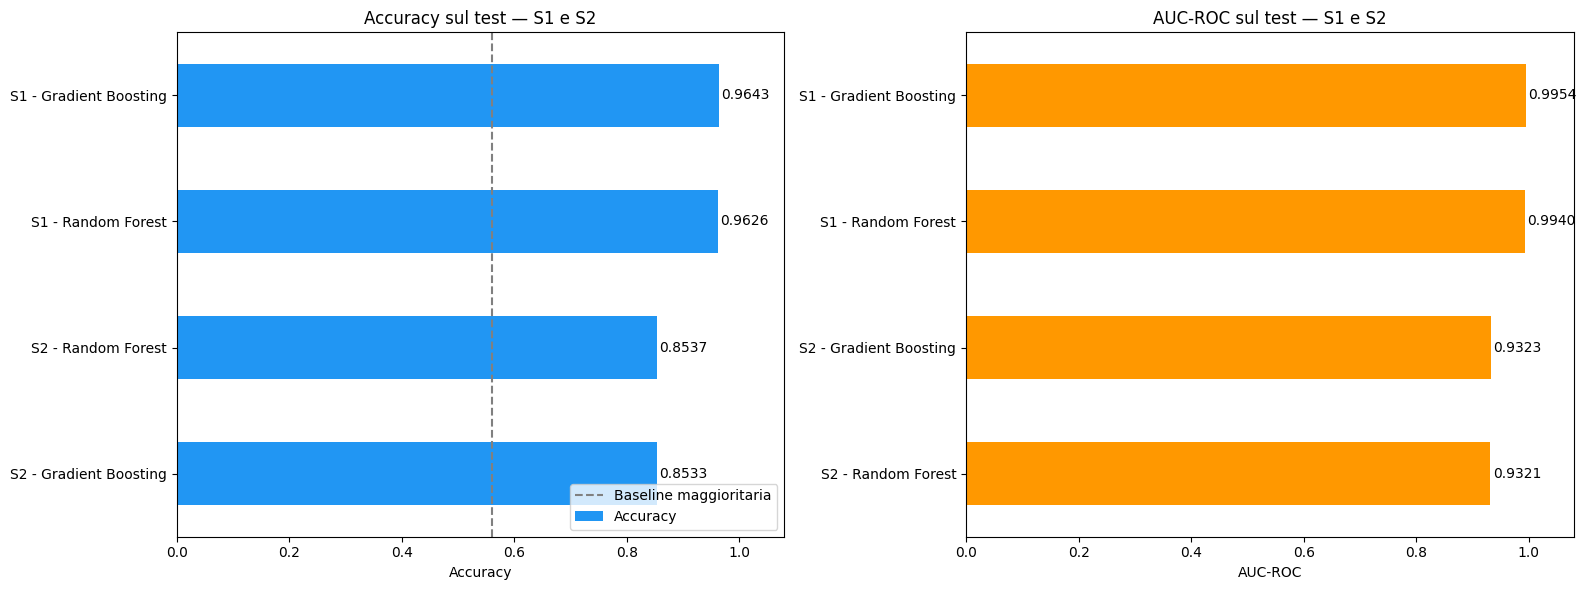

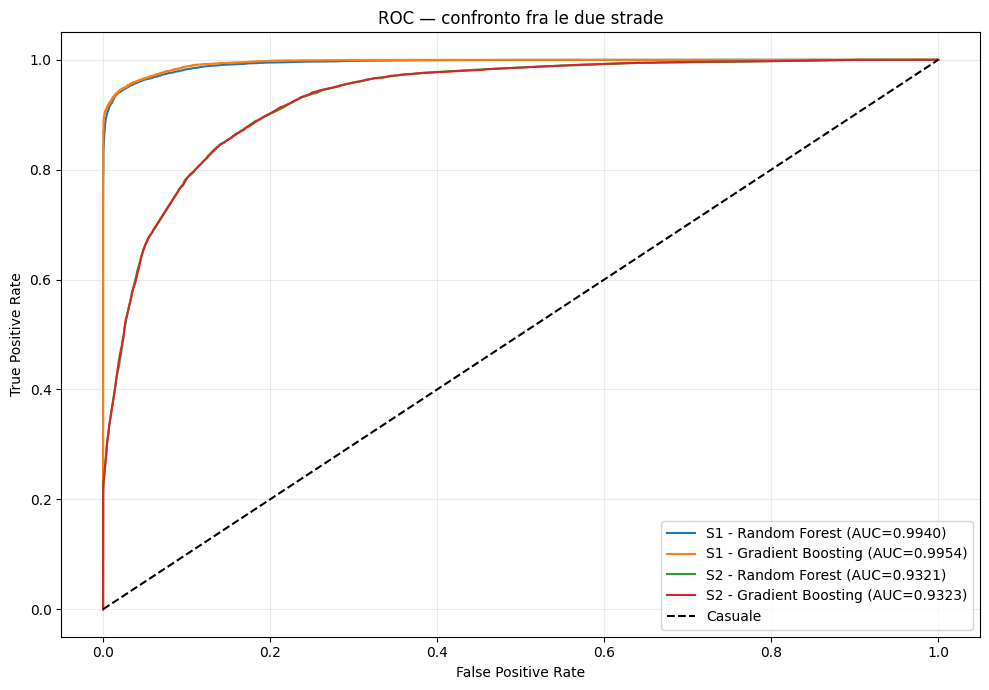

Prima posizione sul test (confronto descrittivo): S1 - Gradient Boosting
Modello conservato per analisi ed export, scelto via CV: S1 - Gradient Boosting


In [56]:
principal_candidates = {f'{route} - {name}': item for route in ['S1', 'S2'] for name, item in tuned[route].items()}
best_model_name = sorted(principal_candidates, key=lambda label: (-principal_candidates[label]['cv_accuracy'], label))[0]
best_overall = principal_candidates[best_model_name]['pipeline']
print('Modello principale scelto da CV:', best_model_name)

raw_data_test = pd.read_csv(DATA_DIR / 'test.csv').drop(columns=['Unnamed: 0'], errors='ignore')
X_test = raw_data_test[FEATURE_COLUMNS].copy()
y_test = raw_data_test['satisfaction'].map({'neutral or dissatisfied': 0, 'satisfied': 1})
assert y_test.notna().all()
assert raw_data_test['id'].is_unique
assert set(raw_data_train['id']).isdisjoint(raw_data_test['id'])
comparison_columns = FEATURE_COLUMNS + ['satisfaction']
train_hashes = pd.util.hash_pandas_object(raw_data_train[comparison_columns], index=False)
test_hashes = pd.util.hash_pandas_object(raw_data_test[comparison_columns], index=False)
assert set(train_hashes).isdisjoint(test_hashes)
assert not raw_data_test[comparison_columns].duplicated().any()

from sklearn.dummy import DummyClassifier
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
baseline_accuracy = accuracy_score(y_test, baseline.predict(X_test))
print(f'Baseline maggioritaria: {baseline_accuracy:.4%}')

def evaluate(label, pipeline, show_report=True):
    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]
    metrics = {'Accuracy': accuracy_score(y_test, predictions),
               'Precision': precision_score(y_test, predictions, zero_division=0),
               'Recall': recall_score(y_test, predictions, zero_division=0),
               'F1-Score': f1_score(y_test, predictions, zero_division=0),
               'AUC-ROC': roc_auc_score(y_test, probabilities)}
    print(label, {key: round(value, 5) for key, value in metrics.items()})
    if show_report:
        print(classification_report(y_test, predictions, target_names=['neutral or dissatisfied', 'satisfied'], zero_division=0))
        fig, ax = plt.subplots(figsize=(7, 5))
        sns.heatmap(confusion_matrix(y_test, predictions), annot=True, fmt='d', cmap='Blues', ax=ax,
                    xticklabels=['neutral or dissatisfied', 'satisfied'], yticklabels=['neutral or dissatisfied', 'satisfied'])
        ax.set_title(f'Matrice di confusione — {label}')
        ax.set_xlabel('Previsto'); ax.set_ylabel('Osservato')
        plt.tight_layout(); plt.show()
    return {**metrics, 'y_pred': predictions, 'y_proba': probabilities}

test_results = {}
for route, models in tuned.items():
    for name, item in models.items():
        test_results[f'{route} - {name}'] = evaluate(f'{route} - {name}', item['pipeline'])
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']
comparison_df = pd.DataFrame({label: {key: test_results[label][key] for key in metric_names}
                             for label in principal_candidates}).T.sort_values('Accuracy', ascending=False)
comparison_df['Accuracy CV (selezione)'] = [principal_candidates[label]['cv_accuracy'] for label in comparison_df.index]
display(comparison_df.style.format('{:.5f}'))
comparison_df.to_csv(RESULTS_DIR / 'confronto_strade.csv')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, metric, color in zip(axes, ['Accuracy', 'AUC-ROC'], ['#2196F3', '#FF9800']):
    values = comparison_df[metric].sort_values()
    values.plot.barh(ax=ax, color=color)
    for index, value in enumerate(values): ax.text(value + .004, index, f'{value:.4f}', va='center')
    ax.set_xlim(0, 1.08); ax.set_xlabel(metric); ax.set_title(f'{metric} sul test — S1 e S2')
axes[0].axvline(baseline_accuracy, linestyle='--', color='gray', label='Baseline maggioritaria')
axes[0].legend(loc='lower right')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 7))
for label in principal_candidates:
    result = test_results[label]
    fpr, tpr, _ = roc_curve(y_test, result['y_proba'])
    ax.plot(fpr, tpr, label=f"{label} (AUC={result['AUC-ROC']:.4f})")
ax.plot([0, 1], [0, 1], 'k--', label='Casuale')
ax.set(xlabel='False Positive Rate', ylabel='True Positive Rate', title='ROC — confronto fra le due strade')
ax.legend(loc='lower right'); ax.grid(alpha=.25)
plt.tight_layout(); plt.show()
print('Prima posizione sul test (confronto descrittivo):', comparison_df.index[0])
print('Modello conservato per analisi ed export, scelto via CV:', best_model_name)

## 5.1 Importanza delle feature del modello principale

L'analisi segue automaticamente il modello scelto dalla CV. Per gli alberi mostro la riduzione di impurità, non un effetto causale: le importanze possono favorire variabili con molte suddivisioni e distribuirsi fra feature correlate. In caso di modello lineare userei il valore assoluto dei coefficienti, da leggere sulle scale trasformate. Confronto i ranking senza trattarli come misure direttamente equivalenti.

,feature,importance
7,Online boarding,0.416
33,Type of Travel_Personal Travel,0.163
2,Inflight wifi service,0.132
18,Inflight wifi service_zeroflag,0.048
32,Customer Type_disloyal Customer,0.043
9,Inflight entertainment,0.035
34,Class_Business,0.023
13,Checkin service,0.022
14,Inflight service,0.014
12,Baggage handling,0.014


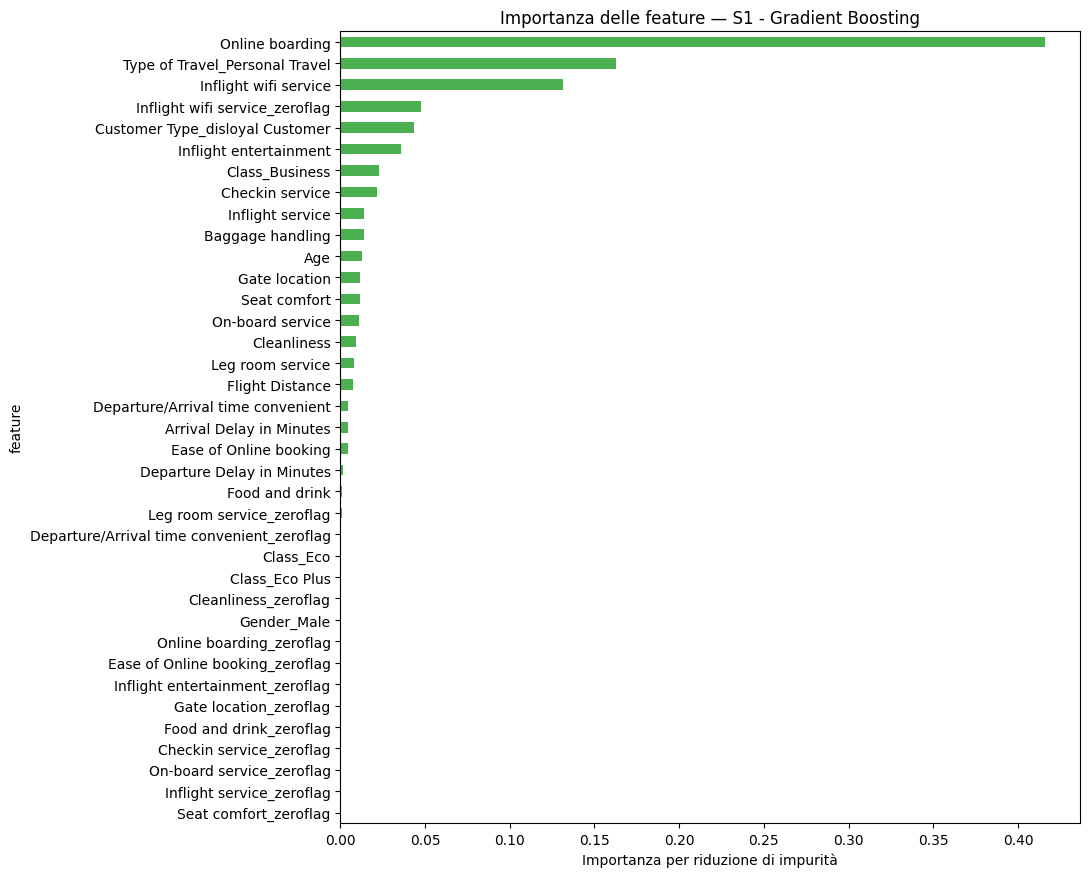

Top 5 modello: ['Online boarding', 'Type of Travel_Personal Travel', 'Inflight wifi service', 'Inflight wifi service_zeroflag', 'Customer Type_disloyal Customer']
Top 5 T-test: ['Online boarding', 'Inflight entertainment', 'Inflight wifi service', 'Seat comfort', 'On-board service']
Ranking categoriche: ['Class', 'Type of Travel', 'Customer Type', 'Gender']


In [57]:
classifier = best_overall.named_steps['model']
feature_names = best_overall.named_steps['prepare'].get_feature_names_out()
if hasattr(classifier, 'feature_importances_'):
    importance = classifier.feature_importances_
    importance_label = 'Importanza per riduzione di impurità'
else:
    importance = np.abs(classifier.coef_[0])
    importance_label = 'Valore assoluto del coefficiente'
fi = pd.DataFrame({'feature': feature_names, 'importance': importance}).sort_values('importance', ascending=False)
display(fi)
fig, ax = plt.subplots(figsize=(11, max(6, len(fi) * .24)))
fi.sort_values('importance').plot.barh(x='feature', y='importance', ax=ax, legend=False, color='#4CAF50')
ax.set_title(f'Importanza delle feature — {best_model_name}')
ax.set_xlabel(importance_label)
plt.tight_layout(); plt.show()
print('Top 5 modello:', fi.head(5)['feature'].tolist())
print('Top 5 T-test:', ttest_df.head(5).index.tolist())
print('Ranking categoriche:', chi2_df.index.tolist())
fi.to_csv(RESULTS_DIR / 'feature_importance.csv', index=False)

## 5.2 Approfondimenti: selezione ibrida e disponibilità delle informazioni

Conservo la **selezione ibrida** come confronto aggiuntivo rispetto alla Strada 2 richiesta. La scelta delle quattro colonne è ricalcolata nei fold; Class diventa il contrasto Business/resto, senza conservare la distinzione Eco/Eco Plus.

Per il controllo temporale distinguo due esperimenti, entrambi già addestrati e ottimizzati nella sezione 4.3:

- **Senza rating**: Age, Flight Distance, Gender, Customer Type, Type of Travel, Class e i due ritardi effettivi. Mantengo così l'esperimento originale, ma lo descrivo correttamente come post-volo senza survey di servizio.
- **Pre-volo**: soltanto le sei variabili precedenti ai ritardi. I ritardi effettivi alla partenza e all'arrivo non sono stime da schedule e vengono esclusi. Anche per queste sei variabili andrebbe verificata la disponibilità reale al momento della decisione: il dataset non contiene timestamp di raccolta o una validazione temporale.

La differenza di accuracy confronta modelli e quantità di informazione disponibili. Non misura l'effetto causale dei servizi né una prestazione già garantita in produzione.

,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Ibrida - Random Forest,0.86584,0.87505,0.81005,0.84130,0.93624
Ibrida - Gradient Boosting,0.86584,0.87505,0.81005,0.84130,0.93610
Senza rating - Gradient Boosting,0.80251,0.77083,0.78286,0.77680,0.86880
Pre-volo - Gradient Boosting,0.79477,0.77425,0.75164,0.76278,0.85865


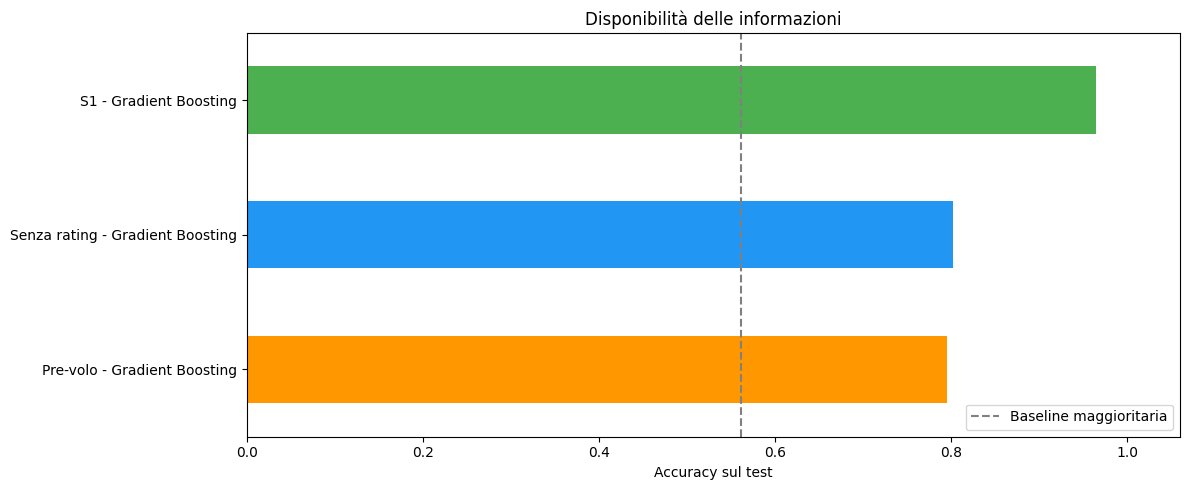

Differenza rispetto al modello principale — Senza rating - Gradient Boosting: 16.18 punti percentuali
Differenza rispetto al modello principale — Pre-volo - Gradient Boosting: 16.95 punti percentuali
Le differenze sono descrittive; modelli e informazioni cambiano insieme.


In [58]:
extra_labels = [label for label in test_results if label not in principal_candidates]
extra_df = pd.DataFrame({label: {metric: test_results[label][metric] for metric in metric_names}
                        for label in extra_labels}).T
display(extra_df.style.format('{:.5f}'))
extra_df.to_csv(RESULTS_DIR / 'confronto_approfondimenti.csv')
scenario_labels = [best_model_name] + [label for label in extra_labels if label.startswith(('Senza rating -', 'Pre-volo -'))]
scenario_accuracy = pd.Series({label: test_results[label]['Accuracy'] for label in scenario_labels})
fig, ax = plt.subplots(figsize=(12, 5))
scenario_accuracy.sort_values().plot.barh(ax=ax, color=['#FF9800', '#2196F3', '#4CAF50'])
ax.axvline(baseline_accuracy, color='gray', linestyle='--', label='Baseline maggioritaria')
ax.set_xlim(0, 1.06); ax.set_xlabel('Accuracy sul test'); ax.set_title('Disponibilità delle informazioni')
ax.legend(loc='lower right')
plt.tight_layout(); plt.show()
for label in scenario_labels[1:]:
    delta = test_results[best_model_name]['Accuracy'] - test_results[label]['Accuracy']
    print(f'Differenza rispetto al modello principale — {label}: {delta * 100:.2f} punti percentuali')
print('Le differenze sono descrittive; modelli e informazioni cambiano insieme.')

# 6.0 Conclusione

Il progetto mantiene il percorso completo: EDA di ogni variabile, confronto del preprocessing, tre metodi di feature selection, quattro algoritmi, ottimizzazione delle due strade e approfondimenti. La correzione centrale è metodologica: tutte le operazioni apprese dai dati ora stanno dentro la cross-validation; la Strada 2 segue il T-test richiesto, mentre conservo l'idea ibrida come analisi distinta.

### Come interpreto i risultati

La tabella seguente è generata dai modelli realmente eseguiti, per evitare che il testo conservi numeri di una versione precedente. La scelta principale deriva dalla CV; il confronto sul test pubblico è riportato separatamente. In particolare, una percentuale di accuracy indica classificazioni corrette, non “varianza spiegata”.

Il modello completo e quello con quattro rating servono soprattutto a leggere le survey dopo il viaggio. Il confronto pre-volo risponde a una domanda diversa, perché elimina sia i rating sia i ritardi effettivi. Il campione è moderatamente sbilanciato: confronto sempre con la baseline e considero anche precision, recall, F1, AUC e report di entrambe le classi.

### Ipotesi operative per la compagnia

1. **Online boarding.** Il forte cambiamento nella quota di soddisfatti fra i rating 3 e 4 suggerisce di approfondire l'esperienza digitale. Proporrei di misurare errori dell'app, tempi e richieste di assistenza, quindi provare un miglioramento su un gruppo controllato. Il grafico non dimostra che aumentare il voto causi lo stesso aumento di soddisfazione.
2. **Esperienza Eco.** Nel train la quota di soddisfatti è circa 18,6% in Eco e 69,4% in Business. Vorrei confrontare gruppi omogenei per tipo di viaggio, tratta e cliente prima di attribuire il divario a un singolo servizio. Le differenze osservate possono guidare interviste e prove pilota, non stimano il ritorno economico di un intervento.
3. **Gestione dei ritardi.** Separerei durata del ritardo, comunicazione e assistenza ricevuta. Questo dataset contiene la durata, ma non misura tutti gli interventi della compagnia: l'idea di migliorare notifiche e supporto è da verificare con nuovi dati.

### Collegamento con l'impatto ambientale

Il brief invita a considerare anche la sostenibilità. Qui non ho carburante, emissioni, occupazione dei voli o alternative di trasporto: non posso calcolare un risparmio di CO₂ né concludere che cambiare frequenze migliori insieme soddisfazione e ambiente. Integrerei questi dati per confrontare scenari di servizio e impatto per passeggero, tenendo distinti risultati osservati e ipotesi. Anche l'unità di Flight Distance andrebbe confermata prima di usarla in indicatori fisici.

### Limiti e passi successivi

- Il test è quello pubblico già osservato; servono nuovi dati, possibilmente separati nel tempo e per contesto operativo, per stimare la generalizzazione reale.
- La selezione e il tuning usano gli stessi cinque fold: i migliori score CV sono misure interne alla ricerca, non una valutazione indipendente. Non ho eseguito una nested CV.
- Il T-test su rating ordinali è un'approssimazione richiesta dall'esercizio; la soglia 0,05 è esplorativa e non applico una correzione per test multipli. Il criterio `|t|` ordina le candidate significative ma non massimizza necessariamente la previsione multivariata.
- Per il Wi-Fi lo zero come N/A è documentato; per gli altri rating rimane una policy da confermare. L'importanza di una flag non ne dimostra il significato. I casi molto rari possono non comparire nel training di un fold.
- I due ritardi sono fortemente correlati. Mantenerli aiuta a conservare l'informazione disponibile, ma le importanze dei modelli non vanno lette come contributi causali isolati.
- L'artefatto esportato accetta dati grezzi, ma questo controllo tecnico non equivale a un sistema pronto per l'uso aziendale. Restano da verificare disponibilità dei dati, categorie nuove, stabilità nel tempo e qualità delle previsioni sui diversi gruppi.

In [59]:
summary_rows = []
for route, models in tuned.items():
    name = sorted(models, key=lambda key: (-models[key]['cv_accuracy'], key))[0]
    label = f'{route} - {name}'
    result = test_results[label]
    summary_rows.append({'Esperimento': route, 'Modello scelto via CV': name,
                         'Accuracy CV': models[name]['cv_accuracy'], 'Accuracy test': result['Accuracy'],
                         'AUC test': result['AUC-ROC']})
summary_table = pd.DataFrame(summary_rows).set_index('Esperimento')
display(summary_table.style.format({'Accuracy CV': '{:.2%}', 'Accuracy test': '{:.2%}', 'AUC test': '{:.5f}'}))
summary_table.to_csv(RESULTS_DIR / 'sintesi_finale.csv')
s1_row, s2_row = summary_table.loc['S1'], summary_table.loc['S2']
display(Markdown(f"Con i modelli scelti tramite CV, S1 ottiene **{s1_row['Accuracy test']:.2%}** di accuracy sul test e S2 **{s2_row['Accuracy test']:.2%}**. "
                 f"La differenza è di **{(s1_row['Accuracy test'] - s2_row['Accuracy test']) * 100:.2f} punti percentuali**. "
                 f"Il confronto pre-volo ottiene **{summary_table.loc['Pre-volo', 'Accuracy test']:.2%}**, rispetto alla baseline maggioritaria **{baseline_accuracy:.2%}**. "
                 "Sono risultati del benchmark, non effetti causali né garanzie operative."))

,Modello scelto via CV,Accuracy CV,Accuracy test,AUC test
Esperimento,,,,
S1,Gradient Boosting,96.37%,96.43%,0.99537
S2,Gradient Boosting,85.46%,85.33%,0.93228
Ibrida,Gradient Boosting,86.71%,86.58%,0.93610
Senza rating,Gradient Boosting,80.60%,80.25%,0.86880
Pre-volo,Gradient Boosting,80.15%,79.48%,0.85865


Con i modelli scelti tramite CV, S1 ottiene **96.43%** di accuracy sul test e S2 **85.33%**. La differenza è di **11.09 punti percentuali**. Il confronto pre-volo ottiene **79.48%**, rispetto alla baseline maggioritaria **56.10%**. Sono risultati del benchmark, non effetti causali né garanzie operative.

# 7.0 Persistenza della pipeline e prova di inferenza

Salvo lo stesso modello principale scelto dalla CV, insieme a selezione, mediane, encoder e scaler. Per usarlo in un altro processo servono il modulo `airline_pipeline.py` scritto da questo notebook e le versioni riportate. Carico soltanto l'artefatto appena creato: file pickle/joblib di provenienza sconosciuta non vanno eseguiti. La prova parte da righe grezze e controlla anche mancanti e una categoria non osservata.

In [60]:
import subprocess
import sys
import warnings

artifact_path = Path('airline_satisfaction_model.joblib')
joblib.dump(best_overall, artifact_path, compress=3)
loaded = joblib.load(artifact_path)
sample = X_test.head(5).copy()
assert np.array_equal(loaded.predict(sample), best_overall.predict(sample))
assert np.allclose(loaded.predict_proba(sample), best_overall.predict_proba(sample))
display(pd.DataFrame({'Target': y_test.head(5).values, 'Previsione': loaded.predict(sample),
                      'P(satisfied)': loaded.predict_proba(sample)[:, 1]}))

edge_sample = sample.copy()
edge_sample.loc[edge_sample.index[0], 'Arrival Delay in Minutes'] = np.nan
edge_sample.loc[edge_sample.index[1], 'Online boarding'] = 0
edge_sample.loc[edge_sample.index[2], 'Class'] = 'Categoria nuova'
with warnings.catch_warnings(record=True) as caught:
    edge_probabilities = loaded.predict_proba(edge_sample)
assert np.isfinite(edge_probabilities).all()
print('Mancanti, rating zero e categoria nuova: previsione finita; avvisi encoder:', len(caught))

sample.to_csv(RESULTS_DIR / 'campione_inferenza.csv', index=False)
fresh_code = '''import joblib, pandas as pd, numpy as np
model = joblib.load('airline_satisfaction_model.joblib')
sample = pd.read_csv('risultati/campione_inferenza.csv')
np.save('risultati/predizioni_processo_nuovo.npy', model.predict_proba(sample))
print('Ricaricamento in un processo nuovo: OK')
'''
check = subprocess.run([sys.executable, '-c', fresh_code], text=True, capture_output=True, check=True)
print(check.stdout.strip())
assert np.allclose(np.load(RESULTS_DIR / 'predizioni_processo_nuovo.npy'), loaded.predict_proba(sample))

report = {
    'selected_by_cv': best_model_name,
    'test_ranking_leader': comparison_df.index[0],
    'baseline_accuracy': baseline_accuracy,
    'versions': versions,
    'data_sha256': {name: hashlib.sha256((DATA_DIR / name).read_bytes()).hexdigest() for name in ['train.csv', 'test.csv']},
    'metrics': {label: {key: result[key] for key in metric_names} for label, result in test_results.items()},
    'cv': {route: {name: {key: value for key, value in item.items() if key != 'pipeline'}
                   for name, item in models.items()} for route, models in tuned.items()},
    's2_features': next(iter(best_models_s2.values())).named_steps['prepare'].get_feature_names_out().tolist(),
    'raw_input_features': FEATURE_COLUMNS,
    'export_feature_count': len(feature_names),
    'inference_checks': {'raw_roundtrip': True, 'missing_zero_unknown': True, 'fresh_process': True},
}
(RESULTS_DIR / 'riepilogo.json').write_text(json.dumps(report, indent=2, ensure_ascii=False))
print(f'Pipeline salvata: {artifact_path} ({artifact_path.stat().st_size / 1e6:.2f} MB)')
print('Riepilogo, griglie complete e controlli dei fold disponibili nella cartella risultati.')

,Target,Previsione,P(satisfied)
0,1,1,0.998
1,1,1,1.000
2,0,0,0.000
3,1,1,0.999
4,1,0,0.083


Mancanti, rating zero e categoria nuova: previsione finita; avvisi encoder: 1


Ricaricamento in un processo nuovo: OK
Pipeline salvata: airline_satisfaction_model.joblib (1.71 MB)
Riepilogo, griglie complete e controlli dei fold disponibili nella cartella risultati.
